In [ ]:
import os
import sys
from pathlib import Path

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
os.chdir(repo_root)
sys.path.insert(0, str(repo_root / "src"))

# Détection d'objets dans des images aériennes

Ce notebook présente une analyse reproductible du jeu de données DOTA, depuis l'exploration des annotations jusqu'à la comparaison de détecteurs et à l'estimation d'effets causaux. Nous séparons explicitement la tâche prédictive (localiser et classer les objets) de la tâche causale (estimer l'effet d'une condition d'image sur la probabilité de détection).


Sources du jeu de données

- [Page officielle du projet DOTA](https://captain-whu.github.io/DOTA/)
- [Page officielle de téléchargement](https://captain-whu.github.io/DOTA/dataset.html)
- [DOTA-v1.0 - entraînement](https://drive.google.com/drive/folders/1gmeE3D7R62UAtuIFOB9j2M5cUPTwtsxK?usp=sharing)
- [DOTA-v1.0 - validation](https://drive.google.com/drive/folders/1n5w45suVOyaqY84hltJhIZdtVFD9B224?usp=sharing)
- [DOTA-v1.5 - page officielle de téléchargement](https://captain-whu.github.io/DOTA/dataset.html)


## Question 1 - Exploration du jeu de données et choix des algorithmes

Avant d'entraîner un modèle, nous devons comprendre la structure du jeu de données et vérifier la qualité des annotations. Cette question couvre :

1. les effectifs d'images et d'objets ;
2. les classes, les dimensions, les surfaces, les orientations et l'indicateur `difficult` ;
3. des exemples d'images avec leurs boîtes orientées et horizontales ;
4. les algorithmes envisageables et les principaux risques méthodologiques.

Aucun modèle n'est entraîné dans cette première question.

### 1 - Charger et contrôler les fichiers

Cette première partie vérifie que le notebook est exécuté depuis la racine du projet, construit uniquement des chemins relatifs et confirme que chaque image annotée possède un fichier `.txt` portant le même nom. Ces contrôles détectent immédiatement un dossier manquant ou un téléchargement incomplet.

In [2]:
from pathlib import Path

import pandas as pd

# Le notebook doit être lancé depuis la racine du projet.
# Tous les autres chemins sont construits à partir de ce dossier.
project_dir = Path.cwd().resolve()
if not (project_dir / "Subject.pdf").is_file():
    raise RuntimeError(
        "Exécutez le notebook depuis la racine du projet,."
    )

# Un dictionnaire regroupe les emplacements afin d'éviter de répéter
# les mêmes chaînes de caractères dans les cellules suivantes.
dataset_dirs = {
    "train_images": project_dir / "Training Data" / "Images",
    "train_labels": project_dir / "Training Data" / "LabelTxt",
    "validation_images": project_dir / "Validation Data" / "Images",
    "validation_labels": project_dir / "Validation Data" / "LabelTxt",
    "test_images": project_dir / "Testing Images" / "Images",
}

missing_dirs = [name for name, path in dataset_dirs.items() if not path.is_dir()]
if missing_dirs:
    raise FileNotFoundError(f"Dossiers DOTA manquants : {missing_dirs}")

print("Racine du projet :", project_dir.name)
print("Structure DOTA-v1.0 trouvée.")

Racine du projet : dota-minimap-object-detection
Structure DOTA-v1.0 trouvée.


In [3]:
# glob('*.png') et glob('*.txt') sélectionnent les fichiers attendus.
# sorted impose un ordre stable, utile pour rendre l'analyse reproductible.
image_files = {
    "train": sorted(dataset_dirs["train_images"].glob("*.png")),
    "validation": sorted(dataset_dirs["validation_images"].glob("*.png")),
    "test": sorted(dataset_dirs["test_images"].glob("*.png")),
}
label_files = {
    "train": sorted(dataset_dirs["train_labels"].glob("*.txt")),
    "validation": sorted(dataset_dirs["validation_labels"].glob("*.txt")),
}

file_summary = pd.DataFrame(
    [
        {
            "ensemble": split_name,
            "images": len(paths),
            # Le test officiel ne fournit pas d'annotations publiques.
            "annotations": (
                len(label_files[split_name]) if split_name in label_files else pd.NA
            ),
        }
        for split_name, paths in image_files.items()
    ]
).set_index("ensemble")

# Le stem est le nom du fichier sans son extension.
# La différence entre les ensembles de stems révèle les paires manquantes.
for split_name in ("train", "validation"):
    image_ids = {path.stem for path in image_files[split_name]}
    label_ids = {path.stem for path in label_files[split_name]}

    if image_ids != label_ids:
        raise ValueError(
            f"Correspondance image/annotation invalide dans {split_name}. "
            f"Images sans annotation : {len(image_ids - label_ids)}; "
            f"annotations sans image : {len(label_ids - image_ids)}."
        )

display(file_summary)
print("Nombre total d'images :", sum(len(paths) for paths in image_files.values()))
print("Toutes les images annotées possèdent le fichier .txt attendu.")

,images,annotations
ensemble,,
train,1411,1411
validation,458,458
test,937,<NA>


Nombre total d'images : 2806
Toutes les images annotées possèdent le fichier .txt attendu.


#### Interprétation des effectifs

Le jeu de données local contient 2 806 images : 1 411 pour l'entraînement, 458 pour la validation et 937 pour le test. Les ensembles annotés présentent une correspondance exacte entre images et fichiers `.txt`.

Les annotations du test officiel ne sont pas publiques. Nous utiliserons donc la validation pour l'évaluation quantitative et conserverons le test pour d'éventuelles prédictions sans vérité terrain. Cette séparation ne devra jamais être modifiée après l'entraînement.

### 2 - Lire une annotation DOTA

Chaque fichier d'annotation commence par deux métadonnées : la source de l'image (`imagesource`) et sa résolution au sol (`gsd`, ou *Ground Sample Distance*). Une valeur `gsd:null` signifie que cette résolution n'est pas disponible.

Chaque ligne suivante décrit un objet :

```text
x1 y1 x2 y2 x3 y3 x4 y4 classe difficult
```

Les huit coordonnées forment les quatre sommets d'une boîte orientée (OBB). Elle suit l'angle de l'objet, contrairement à une boîte horizontale (HBB). La classe indique la catégorie et `difficult` vaut 1 lorsque l'annotation est considérée difficile. DOTA-v1.5 conserve ce format, mais ajoute la classe `container-crane`. Le même parseur pourra donc servir aux deux versions en recevant la liste des classes autorisées.

In [4]:
DOTA_V10_CLASSES = {
    "plane", "baseball-diamond", "bridge", "ground-track-field",
    "small-vehicle", "large-vehicle", "ship", "tennis-court",
    "basketball-court", "storage-tank", "soccer-ball-field",
    "roundabout", "harbor", "swimming-pool", "helicopter",
}

# DOTA-v1.5 reprend les 15 classes de v1.0 et ajoute container-crane.
DOTA_V15_CLASSES = DOTA_V10_CLASSES | {"container-crane"}


def parse_dota_label(label_path, allowed_classes):
    """Lit un fichier LabelTxt DOTA et renvoie ses données structurées."""

    label_path = Path(label_path)
    lines = label_path.read_text(encoding="utf-8").splitlines()

    # Les deux premières lignes doivent contenir les métadonnées attendues.
    if len(lines) < 2:
        raise ValueError(f"{label_path.name}: métadonnées absentes.")
    if not lines[0].startswith("imagesource:"):
        raise ValueError(f"{label_path.name}: imagesource invalide.")
    if not lines[1].startswith("gsd:"):
        raise ValueError(f"{label_path.name}: gsd invalide.")

    image_source = lines[0].split(":", 1)[1].strip()
    gsd_text = lines[1].split(":", 1)[1].strip()
    gsd = None if gsd_text.lower() == "null" else float(gsd_text)

    objects = []
    for line_number, line in enumerate(lines[2:], start=3):
        fields = line.split()
        if len(fields) != 10:
            raise ValueError(
                f"{label_path.name}, ligne {line_number}: 10 champs attendus."
            )

        # Les huit premiers champs deviennent quatre couples de coordonnées.
        coordinates = [float(value) for value in fields[:8]]
        vertices = []
        for index in range(0, 8, 2):
            vertices.append((coordinates[index], coordinates[index + 1]))

        class_name = fields[8]
        difficult = int(fields[9])
        # La liste reçue indique si nous lisons DOTA-v1.0 ou DOTA-v1.5.
        if class_name not in allowed_classes:
            raise ValueError(f"{label_path.name}: classe inconnue {class_name}.")
        if difficult not in (0, 1):
            raise ValueError(f"{label_path.name}: difficult doit valoir 0 ou 1.")

        objects.append(
            {
                "vertices": vertices,
                "class_name": class_name,
                "difficult": difficult,
            }
        )

    return {
        "image_id": label_path.stem,
        "image_source": image_source,
        "gsd": gsd,
        "objects": objects,
    }

### 3 - Construire une table par objet

Les annotations sont organisées par fichier, donc par image. Pour calculer facilement des distributions, nous créons une table dans laquelle une ligne représente un objet annoté. Les sommets sont conservés tels quels : les propriétés géométriques seront calculées dans la prochaine partie, sans modifier l'annotation originale.

In [5]:
annotations_by_split = {}
object_rows = []

for split_name in ("train", "validation"):
    # Chaque fichier est lu une seule fois, puis conservé pour les analyses par image.
    annotations_by_split[split_name] = [
        parse_dota_label(path, DOTA_V10_CLASSES)
        for path in label_files[split_name]
    ]

    for annotation in annotations_by_split[split_name]:
        for object_index, object_data in enumerate(annotation["objects"]):
            object_rows.append(
                {
                    "split": split_name,
                    "image_id": annotation["image_id"],
                    # L'indice distingue plusieurs objets d'une même image.
                    "object_index": object_index,
                    "image_source": annotation["image_source"],
                    "gsd": annotation["gsd"],
                    "class_name": object_data["class_name"],
                    "difficult": object_data["difficult"],
                    "vertices": object_data["vertices"],
                }
            )

objects_df = pd.DataFrame(object_rows)

display(objects_df.drop(columns="vertices").head())
display(objects_df.groupby("split").size().rename("nombre_objets"))
print("Nombre total d'objets annotés :", len(objects_df))

,split,image_id,object_index,image_source,gsd,class_name,difficult
0,train,P0000,0,GoogleEarth,0.146344,plane,0
1,train,P0000,1,GoogleEarth,0.146344,large-vehicle,0
2,train,P0000,2,GoogleEarth,0.146344,large-vehicle,0
3,train,P0000,3,GoogleEarth,0.146344,large-vehicle,0
4,train,P0000,4,GoogleEarth,0.146344,small-vehicle,0


split
train         98990
validation    28853
Name: nombre_objets, dtype: int64

Nombre total d'objets annotés : 127843


#### Premier constat

Le parseur lit 98 990 objets d'entraînement et 28 853 objets de validation, pour un total de 127 843 objets répartis entre 15 classes. La table `objects_df` devient la base commune des analyses descriptives de la question 1. À ce stade, nous avons vérifié le format et les catégories, mais pas encore la validité géométrique des boîtes; ce contrôle sera effectué avant leur utilisation.

### 4 - Étudier la répartition des classes

Nous comptons les objets de chaque classe séparément dans l'entraînement et la validation. Les pourcentages permettent de comparer ces deux ensembles même s'ils ne contiennent pas le même nombre d'objets. Le graphique aide ensuite à repérer les classes dominantes et les différences de répartition.

split,train,validation,total,train_percent,validation_percent
class_name,,,,,
ship,28068,8960,37028,28.35,31.05
small-vehicle,26126,5438,31564,26.39,18.85
large-vehicle,16969,4387,21356,17.14,15.20
plane,8055,2531,10586,8.14,8.77
harbor,5983,2090,8073,6.04,7.24
storage-tank,5029,2888,7917,5.08,10.01
tennis-court,2367,760,3127,2.39,2.63
bridge,2047,464,2511,2.07,1.61
swimming-pool,1736,440,2176,1.75,1.52


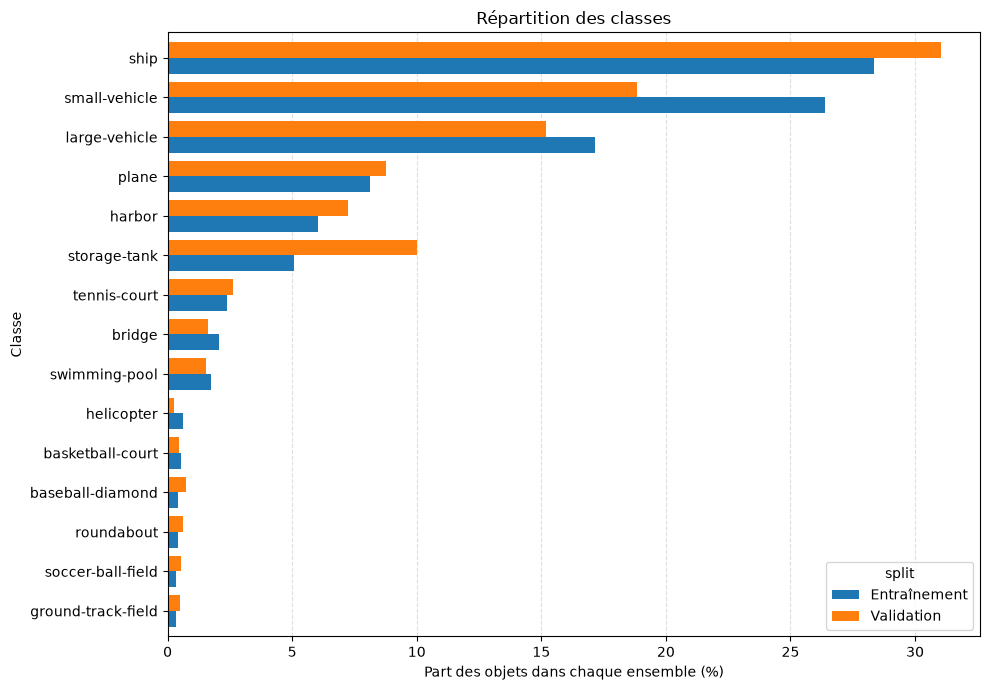

In [6]:
import matplotlib.pyplot as plt

# groupby rassemble les objets ayant la même classe et le même ensemble.
# size compte ensuite le nombre de lignes dans chaque groupe.
class_counts = objects_df.groupby(["class_name", "split"]).size()
# unstack transforme le niveau split en colonnes train et validation.
# fill_value=0 remplace les combinaisons absentes par zéro.
class_counts = class_counts.unstack(fill_value=0)
class_counts["total"] = class_counts["train"] + class_counts["validation"]

# Chaque pourcentage est calculé avec le total de son propre ensemble.
class_counts["train_percent"] = (
    100 * class_counts["train"] / class_counts["train"].sum()
)
class_counts["validation_percent"] = (
    100 * class_counts["validation"] / class_counts["validation"].sum()
)
class_counts = class_counts.sort_values("total", ascending=False)

display(class_counts.round(2))

# Le tri croissant place les classes les plus fréquentes en haut.
class_plot = class_counts.sort_values("total")[
    ["train_percent", "validation_percent"]
].rename(
    columns={"train_percent": "Entraînement", "validation_percent": "Validation"}
)

axis = class_plot.plot(kind="barh", figsize=(10, 7), width=0.8)
axis.set_title("Répartition des classes")
axis.set_xlabel("Part des objets dans chaque ensemble (%)")
axis.set_ylabel("Classe")
axis.grid(axis="x", linestyle="--", alpha=0.4)
axis.set_axisbelow(True)
plt.tight_layout()
plt.show()

#### Interprétation des classes

Les classes `ship`, `small-vehicle` et `large-vehicle` regroupent environ 70,4 % des 127 843 objets. À l'inverse, `ground-track-field` ne contient que 469 objets. Le modèle disposera donc de beaucoup plus d'exemples pour certaines classes que pour d'autres.

La répartition varie aussi entre l'entraînement et la validation. Par exemple, `small-vehicle` représente 26,39 % des objets d'entraînement contre 18,85 % en validation. Ces différences ne prouvent pas une fuite de données, mais elles peuvent influencer les résultats. Une moyenne globale ne suffira donc pas : les performances devront aussi être présentées par classe.

### 5 - Mesurer les dimensions des images

Les images DOTA n'ont pas toutes la même taille. Nous lisons seulement leur largeur, leur hauteur et leur mode de couleur, sans charger tous leurs pixels en mémoire en même temps. Cette analyse permet de décider si les images peuvent être fournies directement aux modèles ou si elles doivent être découpées.

In [7]:
from PIL import Image

image_rows = []

for split_name, paths in image_files.items():
    for image_path in paths:
        # Le bloc with ferme automatiquement le fichier après la lecture.
        with Image.open(image_path) as image:
            width, height = image.size
            color_mode = image.mode

        image_rows.append(
            {
                "split": split_name,
                "image_id": image_path.stem,
                "image_path": image_path,
                "width": width,
                "height": height,
                "color_mode": color_mode,
            }
        )

images_df = pd.DataFrame(image_rows)

# La médiane décrit mieux la taille habituelle que la moyenne lorsque
# quelques images sont beaucoup plus grandes que les autres.
dimension_summary = images_df.groupby("split", sort=False).agg(
    image_count=("image_id", "count"),
    width_min=("width", "min"),
    width_median=("width", "median"),
    width_max=("width", "max"),
    height_min=("height", "min"),
    height_median=("height", "median"),
    height_max=("height", "max"),
)

display(dimension_summary)

# unstack transforme le niveau split en colonnes train, validation et test.
color_mode_counts = (
    images_df.groupby(["color_mode", "split"]).size().unstack(fill_value=0)
)
display(color_mode_counts)

,image_count,width_min,width_median,width_max,height_min,height_median,height_max
split,,,,,,,
train,1411,387,1824.0,12029,278,1791.0,8115
validation,458,353,1871.5,13383,511,1705.5,6759
test,937,211,1817.0,10240,288,1816.0,7665


split,test,train,validation
color_mode,,,
L,154,202,75
RGB,783,1208,383
RGBA,0,1,0


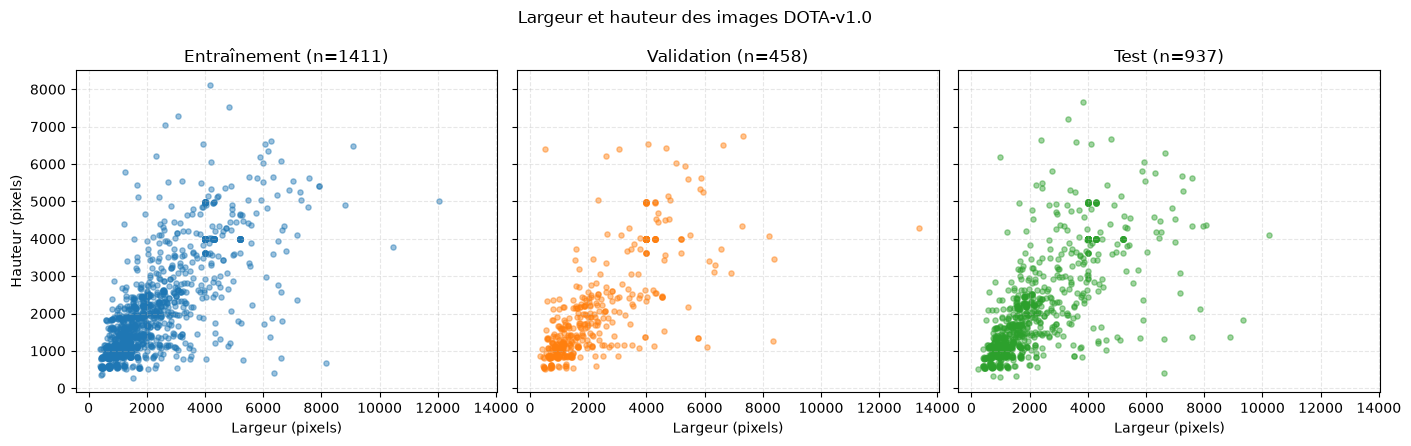

In [8]:
figure, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True, sharey=True)
split_styles = [
    ("train", "Entraînement", "tab:blue"),
    ("validation", "Validation", "tab:orange"),
    ("test", "Test", "tab:green"),
]

# Chaque point représente une image : largeur en x et hauteur en y.
for axis, (split_name, title, color) in zip(axes, split_styles):
    selected_images = images_df[images_df["split"] == split_name]
    axis.scatter(
        selected_images["width"],
        selected_images["height"],
        s=14,
        alpha=0.45,
        color=color,
    )
    axis.set_title(f"{title} (n={len(selected_images)})")
    axis.set_xlabel("Largeur (pixels)")
    axis.grid(linestyle="--", alpha=0.3)

axes[0].set_ylabel("Hauteur (pixels)")
figure.suptitle("Largeur et hauteur des images DOTA-v1.0")
plt.tight_layout()
plt.show()

#### Interprétation des dimensions

Les dimensions médianes sont proches de 1 800 × 1 800 pixels, mais certaines images dépassent 10 000 pixels de largeur. Réduire fortement une grande image ferait disparaître une partie des petits objets, tandis que la traiter directement demanderait beaucoup de mémoire.

Nous utiliserons donc le tuilage, c'est-à-dire le découpage des grandes images en zones plus petites. Toutes les tuiles provenant d'une même image devront rester dans le même ensemble. Sinon, des zones presque identiques pourraient se retrouver à la fois dans l'entraînement et dans la validation, ce qui créerait une fuite de données. Les modes `L` et `RGBA` seront aussi convertis en RGB pendant la préparation.

### 6 - Étudier l'indicateur `difficult`

L'indicateur `difficult` vient directement des annotations DOTA. Il vaut 1 pour un objet considéré difficile à reconnaître. Ce n'est ni une erreur détectée par notre code ni un score produit par le modèle.

In [9]:
# Nous comptons séparément les valeurs 0 et 1 dans chaque ensemble.
difficult_summary = objects_df.groupby(["difficult", "split"]).size()
# unstack transforme le niveau split en colonnes train et validation.
difficult_summary = difficult_summary.unstack(fill_value=0)

difficult_summary["train_percent"] = (
    100 * difficult_summary["train"] / difficult_summary["train"].sum()
)
difficult_summary["validation_percent"] = (
    100
    * difficult_summary["validation"]
    / difficult_summary["validation"].sum()
)
difficult_summary["total"] = (
    difficult_summary["train"] + difficult_summary["validation"]
)
difficult_summary["total_percent"] = (
    100 * difficult_summary["total"] / difficult_summary["total"].sum()
)

display(difficult_summary.round(2))

split,train,validation,train_percent,validation_percent,total,total_percent
difficult,,,,,,
0,93496,26944,94.45,93.38,120440,94.21
1,5494,1909,5.55,6.62,7403,5.79


#### Interprétation de `difficult`

Les objets marqués `difficult=1` représentent 5,79 % des annotations : 5,55 % dans l'entraînement et 6,62 % dans la validation. Ils restent inclus dans cette exploration afin de ne pas modifier artificiellement les données. Leur utilisation exacte pendant l'entraînement et l'évaluation sera expliquée dans la préparation des annotations.

### 7 - Vérifier la géométrie des boîtes

La surface d'une boîte orientée est calculée à partir de ses quatre sommets avec la formule du lacet :

$$A = \frac{1}{2} \left|\sum_{i=1}^{4}(x_i y_{i+1} - y_i x_{i+1})\right|$$

Pour l'orientation, nous choisissons le côté le plus long comme axe principal. `atan2(dy, dx)` fournit son angle, puis `% 180` le ramène entre 0 et 180 degrés. Enfin, les coordonnées minimales et maximales permettent de vérifier si la boîte reste dans l'image.

In [10]:
import math


def compute_polygon_area(vertices):
    """Calcule la surface d'un polygone avec la formule du lacet."""

    if len(vertices) < 3:
        raise ValueError("Un polygone doit avoir au moins trois sommets.")

    signed_sum = 0.0
    for index in range(len(vertices)):
        # Le modulo relie le dernier sommet au premier.
        next_index = (index + 1) % len(vertices)
        x_current, y_current = vertices[index]
        x_next, y_next = vertices[next_index]
        signed_sum += x_current * y_next - y_current * x_next

    return abs(signed_sum) / 2


def compute_obb_orientation(vertices):
    """Retourne l'angle du plus long côté de l'OBB, entre 0 et 180 degrés."""

    if len(vertices) != 4:
        raise ValueError("Une OBB doit avoir exactement quatre sommets.")

    side_vectors = []
    for index in range(4):
        next_index = (index + 1) % 4 # si on est au dernier idx il deermine le premier comme le suivant
        x_current, y_current = vertices[index]
        x_next, y_next = vertices[next_index]
        dx, dy = x_next - x_current, y_next - y_current
        side_vectors.append((math.hypot(dx, dy), dx, dy))

    longest_length, dx, dy = max(side_vectors, key=lambda side: side[0])
    if longest_length == 0:
        raise ValueError("L'orientation est indéfinie pour une boîte nulle.")

    return math.degrees(math.atan2(dy, dx)) % 180

In [11]:
# merge associe à chaque objet les dimensions de son image.
# many_to_one vérifie qu'une image possède une seule paire de dimensions.
image_dimensions = images_df[["split", "image_id", "width", "height"]]
objects_geometry_df = objects_df.merge(
    image_dimensions,
    on=["split", "image_id"],
    how="left",
    validate="many_to_one",
)

# apply appelle la fonction indiquée pour chaque liste de sommets.
objects_geometry_df["area_px2"] = objects_geometry_df["vertices"].apply(
    compute_polygon_area
)
objects_geometry_df["orientation_deg"] = objects_geometry_df["vertices"].apply(
    compute_obb_orientation
)

# Ces quatre colonnes décrivent les limites de chaque boîte.
objects_geometry_df["min_x"] = objects_geometry_df["vertices"].apply(
    lambda vertices: min(x for x, _ in vertices)
)
objects_geometry_df["max_x"] = objects_geometry_df["vertices"].apply(
    lambda vertices: max(x for x, _ in vertices)
)
objects_geometry_df["min_y"] = objects_geometry_df["vertices"].apply(
    lambda vertices: min(y for _, y in vertices)
)
objects_geometry_df["max_y"] = objects_geometry_df["vertices"].apply(
    lambda vertices: max(y for _, y in vertices)
)

# Chaque valeur mesure un dépassement; clip remplace les valeurs négatives par 0.
boundary_excess = pd.DataFrame(
    {
        "left": -objects_geometry_df["min_x"],
        "top": -objects_geometry_df["min_y"],
        "right": objects_geometry_df["max_x"] - objects_geometry_df["width"],
        "bottom": objects_geometry_df["max_y"] - objects_geometry_df["height"],
    }
).clip(lower=0)
objects_geometry_df["boundary_excess_px"] = boundary_excess.max(axis=1)

outside_objects = objects_geometry_df[objects_geometry_df["boundary_excess_px"] > 0]
outside_by_image = (
    outside_objects.groupby(["split", "image_id"])
    .agg(
        outside_objects=("object_index", "count"),
        largest_excess_px=("boundary_excess_px", "max"),
    )
    .sort_values("largest_excess_px", ascending=False)
)

print("Surfaces nulles ou négatives :", (objects_geometry_df["area_px2"] <= 0).sum())
print("Objets dépassant leur image :", len(outside_objects))
display(outside_by_image.head())

# P1872 est retirée seulement des analyses suivantes; le fichier brut reste intact.
corrupted_image = (
    (objects_geometry_df["split"] == "train")
    & (objects_geometry_df["image_id"] == "P1872")
)
analysis_objects_df = objects_geometry_df.loc[~corrupted_image].copy()

Surfaces nulles ou négatives : 0
Objets dépassant leur image : 171


outside_objects  largest_excess_px
split image_id                                    
train P1872                  84             7749.0
      P0387                   1                3.0
      P0713                   2                2.0
      P0383                   1                2.0
      P1805                   2                2.0

#### Interprétation du contrôle géométrique

Toutes les boîtes possèdent une surface positive. Nous trouvons toutefois 171 objets qui dépassent les limites de leur image. Pour 87 d'entre eux, le dépassement ne mesure que 1 à 3 pixels. Les 84 grands dépassements restants proviennent tous de l'image d'entraînement `P1872`, avec un maximum de 7 749 pixels. Cette image est donc retirée des distributions suivantes. Les petits dépassements seront corrigés de la même manière pour l'entraînement et la validation dans la question 2. Les fichiers bruts ne sont jamais modifiés.

### 8 - Étudier la surface des objets

La surface est exprimée en pixels carrés. Comme les valeurs vont de quelques pixels à plus d'un million, le graphique utilise une échelle logarithmique afin que les petits et les grands objets restent visibles.

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
split,,,,,,,,,,,
train,98804.0,3820.4,23899.2,12.0,462.0,759.0,1810.0,5203.8,14390.0,52170.7,1393355.5
validation,28853.0,4649.7,22495.7,9.0,456.0,766.0,2068.0,5965.9,17842.0,77255.6,1127740.5


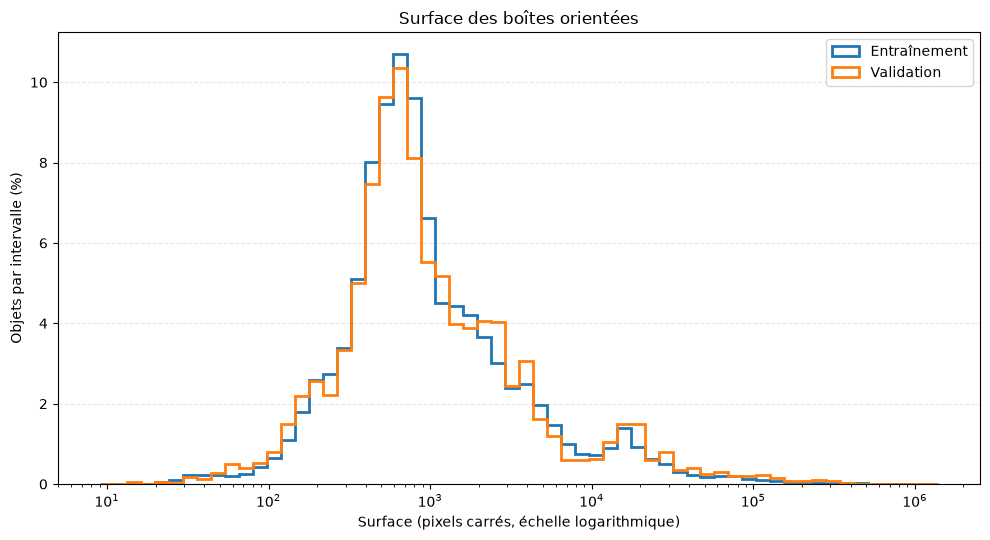

In [12]:
import numpy as np

area_summary = analysis_objects_df.groupby("split")["area_px2"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)
display(area_summary.round(1))

# logspace crée des intervalles réguliers sur une échelle logarithmique.
# 61 bornes donnent 60 intervalles, assez détaillés sans surcharger la figure.
area_bins = np.logspace(
    np.log10(analysis_objects_df["area_px2"].min()),
    np.log10(analysis_objects_df["area_px2"].max()),
    61, # 61 bornes créent 60 intervalles pour l'histogramme.
)

figure, axis = plt.subplots(figsize=(10, 5.5))
for split_name, title, color in [
    ("train", "Entraînement", "tab:blue"),
    ("validation", "Validation", "tab:orange"),
]:
    areas = analysis_objects_df.loc[
        analysis_objects_df["split"] == split_name, "area_px2"
    ]
    # Les poids font totaliser chaque ensemble à 100 %.
    weights = np.full(len(areas), 100 / len(areas))
    axis.hist(
        areas, bins=area_bins, weights=weights, histtype="step",
        linewidth=2, color=color, label=title,
    )

axis.set_xscale("log")
axis.set_title("Surface des boîtes orientées")
axis.set_xlabel("Surface (pixels carrés, échelle logarithmique)")
axis.set_ylabel("Objets par intervalle (%)")
axis.grid(axis="y", linestyle="--", alpha=0.3)
axis.legend()
plt.tight_layout()
plt.show()

#### Interprétation des surfaces

La surface médiane vaut 759 pixels carrés dans l'entraînement et 766 dans la validation. Les moyennes sont beaucoup plus élevées, car quelques objets dépassent un million de pixels carrés. Le jeu de données contient donc beaucoup de petits objets et une minorité de très grands objets. Cette différence de taille renforce le choix du tuilage : une forte réduction des images ferait perdre les petits objets, tandis qu'une tuile peut couper les plus grands.

### 9 - Étudier l'orientation des objets

Les angles sont regroupés par intervalles de 15 degrés. Une orientation de 0 degré et une orientation de 180 degrés décrivent le même axe. Un graphique en barres suffit ici à comparer l'entraînement et la validation.

split,train,validation
angle_group,,
"[0, 15)",14.20,17.56
"[15, 30)",6.55,4.06
"[30, 45)",5.94,4.52
"[45, 60)",7.68,5.12
"[60, 75)",7.36,6.37
"[75, 90)",9.39,9.03
"[90, 105)",13.70,20.83
"[105, 120)",7.26,8.52
"[120, 135)",6.72,7.08


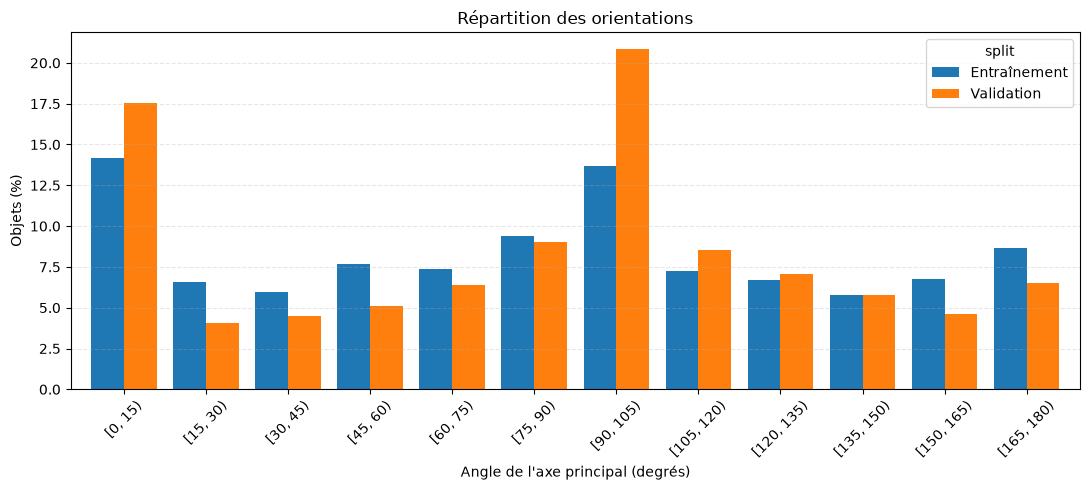

In [13]:
orientation_edges = list(range(0, 181, 15))
orientation_labels = [
    f"[{start}, {start + 15})" for start in orientation_edges[:-1]
]

orientation_df = analysis_objects_df[["split", "orientation_deg"]].copy()
# pd.cut associe chaque angle à l'un des intervalles de 15 degrés.
orientation_df["angle_group"] = pd.cut(
    orientation_df["orientation_deg"],
    bins=orientation_edges,
    labels=orientation_labels,
    right=False,
    include_lowest=True,
)

# unstack transforme le niveau split en colonnes train et validation.
orientation_counts = (
    orientation_df.groupby(["angle_group", "split"], observed=False)
    .size()
    .unstack(fill_value=0)
)
# Chaque colonne est divisée par son total pour obtenir des pourcentages.
orientation_percent = 100 * orientation_counts.div(
    orientation_counts.sum(axis=0), axis=1
)
display(orientation_percent.round(2))

axis = orientation_percent.rename(
    columns={"train": "Entraînement", "validation": "Validation"}
).plot(kind="bar", figsize=(11, 5), width=0.8)
axis.set_title("Répartition des orientations")
axis.set_xlabel("Angle de l'axe principal (degrés)")
axis.set_ylabel("Objets (%)")
axis.tick_params(axis="x", rotation=45)
axis.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

#### Interprétation des orientations

Les objets ne sont pas répartis uniformément entre les angles. Les orientations proches des axes horizontaux et verticaux sont les plus fréquentes. L'intervalle `[90, 105)` contient notamment 13,70 % des objets d'entraînement et 20,83 % de ceux de validation. Un détecteur OBB est donc utile pour conserver cette information. Une boîte horizontale perd l'angle et ajoute souvent de l'arrière-plan autour des objets inclinés. Pour une boîte presque carrée, l'orientation du plus long côté peut toutefois devenir instable et doit être interprétée avec prudence.

### 10 - Visualiser les boîtes orientées

Nous affichons une image d'entraînement et une image de validation. La fonction retrouve l'image et ses objets à partir du couple `(split, image_id)`, puis dessine les quatre sommets de chaque OBB. Elle sera réutilisable plus loin sans dépendre d'un script externe.

In [14]:
from matplotlib.patches import Polygon, Rectangle


def get_image_and_objects(image_id, split_name, images_table, objects_table):
    """Retourne le chemin d'une image et les objets qui lui appartiennent."""

    image_mask = (
        (images_table["split"] == split_name)
        & (images_table["image_id"] == image_id)
    )
    selected_images = images_table.loc[image_mask]
    if len(selected_images) != 1:
        raise ValueError(f"{split_name}/{image_id}: image unique attendue.")

    object_mask = (
        (objects_table["split"] == split_name)
        & (objects_table["image_id"] == image_id)
    )
    image_objects = objects_table.loc[object_mask].copy()
    return selected_images.iloc[0]["image_path"], image_objects


def plot_image_with_obb(image_path, image_objects, show_labels=False):
    """Affiche une image avec les OBB de ses objets."""

    with Image.open(image_path) as image:
        image_array = np.asarray(image.convert("RGB"))

    figure, axis = plt.subplots(figsize=(11, 8))
    axis.imshow(image_array)

    # iterrows parcourt une ligne d'annotation à la fois.
    for _, object_row in image_objects.iterrows():
        vertices = object_row["vertices"]
        axis.add_patch(
            Polygon(
                vertices, closed=True, fill=False,
                edgecolor="red", linewidth=1.2,
            )
        )

        if show_labels:
            # La taille 7 garde le texte lisible sans trop couvrir l'objet.
            label_x, label_y = vertices[0]
            axis.text(
                label_x, label_y, object_row["class_name"],
                color="yellow", fontsize=7,
                bbox={"facecolor": "black", "alpha": 0.6, "pad": 1},
            )

    axis.set_title(f"{Path(image_path).stem} - {len(image_objects)} objets")
    axis.axis("off")
    figure.tight_layout()
    plt.show()

train/P2257: 13 objets, 6 classes


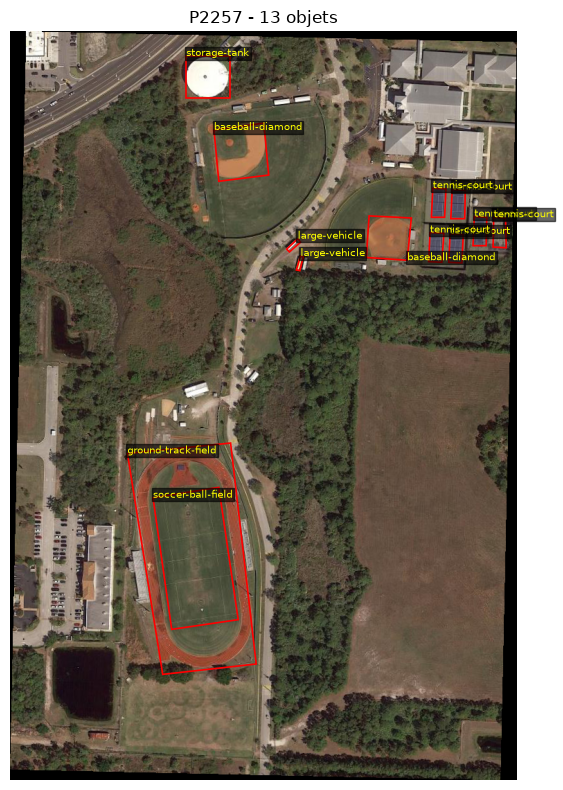

validation/P2166: 15 objets, 4 classes


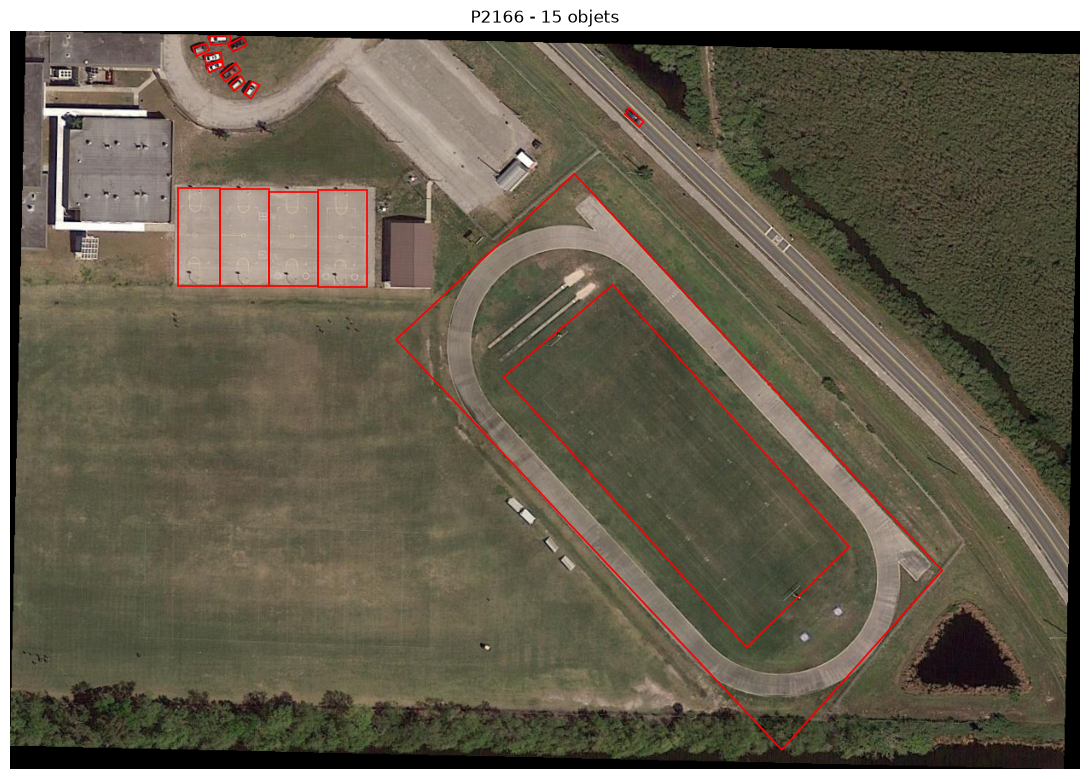

In [15]:
# P2257 contient plusieurs classes avec assez peu d'objets pour afficher les noms.
# P2166 montre un autre type de scène provenant de la validation.
obb_examples = [
    ("train", "P2257", True),
    ("validation", "P2166", False),
]

for split_name, image_id, show_labels in obb_examples:
    image_path, image_objects = get_image_and_objects(
        image_id, split_name, images_df, analysis_objects_df
    )
    print(
        f"{split_name}/{image_id}: {len(image_objects)} objets, "
        f"{image_objects['class_name'].nunique()} classes"
    )
    plot_image_with_obb(image_path, image_objects, show_labels=show_labels)

#### Lecture des exemples

Les OBB suivent la direction réelle des véhicules, des terrains et des autres objets. Les exemples montrent aussi que plusieurs classes et plusieurs tailles peuvent apparaître dans une même image. Les textes sont retirés de l'image la plus chargée afin de ne pas masquer les petits objets.

### 11 - Comparer une OBB et sa HBB

Une HBB est définie par les valeurs minimales et maximales en x et en y. Elle contient toute l'OBB, mais ne conserve pas son angle. Nous superposons les deux boîtes sur le même avion afin de rendre cette perte visible.

In [16]:
def convert_obb_to_hbb(vertices):
    """Convertit quatre sommets OBB en (min_x, min_y, max_x, max_y)."""

    if len(vertices) != 4:
        raise ValueError("Une OBB doit avoir exactement quatre sommets.")

    x_coordinates = [x for x, _ in vertices]
    y_coordinates = [y for _, y in vertices]
    return (
        min(x_coordinates), min(y_coordinates),
        max(x_coordinates), max(y_coordinates),
    )

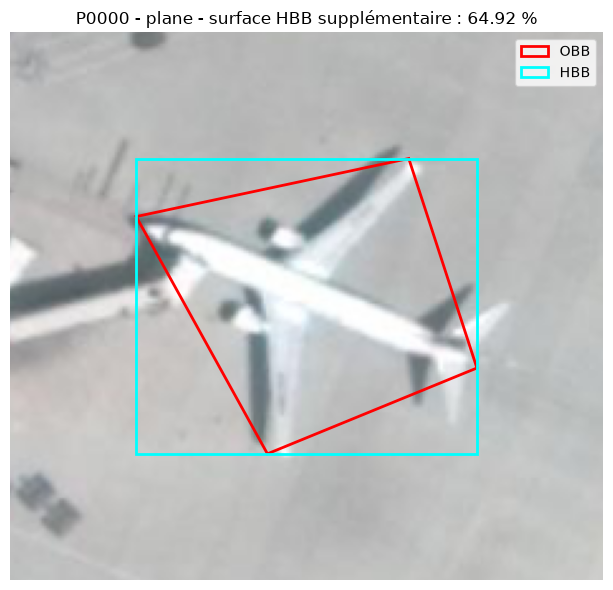

Surface OBB : 9577.5 pixels carrés
Surface HBB : 15795.0 pixels carrés


In [17]:
comparison_path, comparison_objects = get_image_and_objects(
    "P0000", "train", images_df, analysis_objects_df
)
# Le premier objet de P0000 est un avion incliné, utile pour cette comparaison.
comparison_object = comparison_objects.iloc[0]
vertices = comparison_object["vertices"]
min_x, min_y, max_x, max_y = convert_obb_to_hbb(vertices)

obb_area = compute_polygon_area(vertices)
hbb_area = (max_x - min_x) * (max_y - min_y)
extra_area_percent = 100 * (hbb_area - obb_area) / obb_area

with Image.open(comparison_path) as image:
    comparison_image = np.asarray(image.convert("RGB"))

figure, axis = plt.subplots(figsize=(8, 6))
axis.imshow(comparison_image)
axis.add_patch(
    Polygon(vertices, closed=True, fill=False, edgecolor="red",
            linewidth=2, label="OBB")
)
axis.add_patch(
    Rectangle((min_x, min_y), max_x - min_x, max_y - min_y,
              fill=False, edgecolor="cyan", linewidth=2, label="HBB")
)

# Une marge de 50 pixels montre le contexte sans trop éloigner l'objet.
padding = 50
axis.set_xlim(max(0, min_x - padding), min(comparison_image.shape[1], max_x + padding))
axis.set_ylim(min(comparison_image.shape[0], max_y + padding), max(0, min_y - padding))
axis.set_title(
    f"P0000 - {comparison_object['class_name']} - "
    f"surface HBB supplémentaire : {extra_area_percent:.2f} %"
)
axis.legend()
axis.axis("off")
figure.tight_layout()
plt.show()

print("Surface OBB :", round(obb_area, 2), "pixels carrés")
print("Surface HBB :", round(hbb_area, 2), "pixels carrés")

#### Interprétation de la conversion

Pour cet avion, la HBB ajoute 64,92 % de surface par rapport à l'OBB. Cette surface supplémentaire contient surtout de l'arrière-plan. La HBB est plus simple et compatible avec Faster R-CNN, mais l'OBB décrit mieux les objets inclinés. Cet exemple montre le type de perte produit par la conversion sans prétendre représenter tous les objets.

### 12 - Choisir les méthodes

| Méthode | Utilité dans ce projet | Limite principale |
|---|---|---|
| YOLO-OBB sur des tuiles | Détecte rapidement les classes et conserve l'orientation | Les très petits objets restent difficiles |
| Faster R-CNN avec HBB | Fournit un modèle de comparaison connu et précis | Plus lent et perte de l'orientation |
| RetinaNet avec HBB | Réduit l'influence des exemples faciles grâce à la focal loss | Perd l'orientation |
| DETR avec HBB | Utilise le contexte global de l'image | Entraînement plus coûteux |
| Arbre ou forêt causale | Étudie plus tard la variation d'un effet entre les objets | Ne réalise aucune détection |

Nous retenons YOLO-OBB comme modèle principal et Faster R-CNN comme comparaison. YOLO sera d'abord entraîné sur DOTA-v1.0, puis son meilleur modèle sera adapté à DOTA-v1.5. Faster R-CNN sera entraîné directement sur DOTA-v1.5 avec les annotations converties en HBB. Le tuilage est une étape de préparation commune, et non un modèle.

### 13 - Écarter les méthodes inadaptées

Un classifieur d'images utilisé seul, comme une simple classification ResNet, attribue une classe à l'image entière. Il ne fournit ni position ni boîte et ne peut donc pas localiser les nombreux objets présents dans une scène DOTA.

Un détecteur appliqué directement aux images géantes est également inadapté. Une forte réduction ferait disparaître les petits objets, alors que conserver la taille originale demanderait trop de mémoire. Le détecteur devient utilisable après le découpage en tuiles.

### 14 - Retenir les principaux risques

- Fuite entre tuiles : toutes les tuiles d'une image doivent rester dans le même ensemble.
- Déséquilibre des classes : une moyenne globale peut cacher de faibles résultats pour les classes rares.
- Conversion OBB vers HBB : l'angle est perdu et davantage d'arrière-plan est inclus.
- Prédiction et causalité : un bon mAP mesure la détection, mais ne prouve pas qu'une caractéristique cause les erreurs.

Ces risques guideront le tuilage, l'évaluation par classe et la séparation entre les questions prédictives et causales.

### 15 - Synthèse de la question 1

L'exploration du jeu de données conduit aux constats suivants :

- DOTA-v1.0 contient localement 2 806 images et 127 843 objets annotés dans 15 classes.
- Les images ont des tailles très variables et beaucoup d'objets sont petits, ce qui justifie le tuilage.
- Les classes sont déséquilibrées, les orientations varient et 5,79 % des objets sont marqués `difficult`.
- L'image `P1872` contient des annotations clairement hors limites et sera exclue pendant le nettoyage.
- YOLO-OBB conservera l'orientation; Faster R-CNN utilisera des HBB pour fournir une comparaison.
- Les futures performances prédictives resteront distinctes des effets causaux.

## Question 2 - Prétraitement des images, annotations et variables dérivées

Cette question transforme les données vérifiées en entrées utilisables par YOLO-OBB, Faster R-CNN et l'analyse causale. Les fichiers originaux restent inchangés : toutes les corrections sont appliquées uniquement aux tables et aux fichiers produits par le notebook.

Les principales étapes sont le nettoyage des boîtes, le découpage en tuiles, la création des formats OBB et HBB, puis le calcul des variables décrivant les objets et les images.

### 1 - Nettoyer les annotations

L'image `P1872`, repérée comme corrompue dans la question 1, est exclue. Les 87 autres objets qui dépassent leur image de 1 à 3 pixels sont ramenés sur le bord. Les surfaces et les angles sont ensuite recalculés.

Les objets marqués `difficult`, les petites boîtes valides et les classes rares sont conservés. Ils représentent des cas importants pour l'entraînement et pour l'étude des erreurs. Une boîte est retirée seulement si sa géométrie reste invalide après les corrections.

In [18]:
def clip_vertices_to_image(vertices, image_width, image_height):
    """Ramène les sommets d'une OBB dans les limites de son image."""

    if len(vertices) != 4:
        raise ValueError("Une OBB doit avoir exactement quatre sommets.")
    if image_width <= 0 or image_height <= 0:
        raise ValueError("Les dimensions de l'image doivent être positives.")

    clipped_vertices = []
    for x, y in vertices:
        # max empêche une valeur négative et min empêche un dépassement.
        clipped_x = min(max(float(x), 0.0), float(image_width))
        clipped_y = min(max(float(y), 0.0), float(image_height))
        clipped_vertices.append((clipped_x, clipped_y))

    return clipped_vertices

In [19]:
# P1872 est retirée de la table des images comme elle l'était déjà des objets.
p1872_image = (
    (images_df["split"] == "train") & (images_df["image_id"] == "P1872")
)
preprocessed_images_df = images_df.loc[~p1872_image].copy()
preprocessed_objects_df = analysis_objects_df.copy()

preprocessed_objects_df["was_clipped"] = (
    preprocessed_objects_df["boundary_excess_px"] > 0
)
area_before_clipping = preprocessed_objects_df["area_px2"].copy()

# apply avec axis=1 transmet une ligne complète à la fonction.
preprocessed_objects_df["vertices"] = preprocessed_objects_df.apply(
    lambda object_row: clip_vertices_to_image(
        object_row["vertices"], object_row["width"], object_row["height"]
    ),
    axis=1,
)

# apply recalcule chaque valeur depuis les sommets corrigés.
preprocessed_objects_df["area_px2"] = preprocessed_objects_df["vertices"].apply(
    compute_polygon_area
)
preprocessed_objects_df["orientation_deg"] = (
    preprocessed_objects_df["vertices"].apply(compute_obb_orientation)
)

# Chaque tuple HBB devient une ligne de quatre colonnes.
hbb_values = preprocessed_objects_df["vertices"].apply(convert_obb_to_hbb)
hbb_columns = ["min_x", "min_y", "max_x", "max_y"]
preprocessed_objects_df[hbb_columns] = pd.DataFrame(
    hbb_values.tolist(),
    index=preprocessed_objects_df.index,
    columns=hbb_columns,
)

still_outside = (
    (preprocessed_objects_df["min_x"] < 0)
    | (preprocessed_objects_df["min_y"] < 0)
    | (preprocessed_objects_df["max_x"] > preprocessed_objects_df["width"])
    | (preprocessed_objects_df["max_y"] > preprocessed_objects_df["height"])
)

clipped_mask = preprocessed_objects_df["was_clipped"]
area_change_percent = 100 * (
    preprocessed_objects_df.loc[clipped_mask, "area_px2"]
    - area_before_clipping.loc[clipped_mask]
) / area_before_clipping.loc[clipped_mask]

assert not still_outside.any()
print("Images conservées :", len(preprocessed_images_df))
print("Objets corrigés :", int(clipped_mask.sum()))
print("Objets encore hors limites :", int(still_outside.sum()))
print("Variation médiane de leur surface :", round(area_change_percent.median(), 2), "%")

Images conservées : 2805
Objets corrigés : 87
Objets encore hors limites : 0
Variation médiane de leur surface : -2.19 %


### 2 - Retirer les géométries invalides

Dans une boîte valide, les quatre sommets suivent toujours le même sens autour de l'objet. Le signe du produit vectoriel indique le sens de chaque virage. Si les quatre signes ne sont pas identiques, le quadrilatère est replié vers l'intérieur et ne représente pas une OBB valide.

In [20]:
def is_convex_quadrilateral(vertices):
    """Vérifie que les quatre virages du quadrilatère ont le même sens."""

    if len(vertices) != 4:
        return False

    cross_products = []
    for index in range(4):
        point_a = vertices[index]
        point_b = vertices[(index + 1) % 4]
        point_c = vertices[(index + 2) % 4]

        first_dx, first_dy = point_b[0] - point_a[0], point_b[1] - point_a[1]
        second_dx, second_dy = point_c[0] - point_b[0], point_c[1] - point_b[1]
        cross_products.append(first_dx * second_dy - first_dy * second_dx)

    return all(value > 0 for value in cross_products) or all(
        value < 0 for value in cross_products
    )


# apply répète le contrôle sur chaque liste de sommets.
preprocessed_objects_df["is_valid_geometry"] = (
    preprocessed_objects_df["vertices"].apply(is_convex_quadrilateral)
    & (preprocessed_objects_df["area_px2"] > 0)
)
invalid_objects_df = preprocessed_objects_df.loc[
    ~preprocessed_objects_df["is_valid_geometry"],
    ["split", "image_id", "object_index", "class_name", "difficult"],
]
validated_objects_df = preprocessed_objects_df.loc[
    preprocessed_objects_df["is_valid_geometry"]
].copy()

display(invalid_objects_df)
print("Objets avant le contrôle :", len(preprocessed_objects_df))
print("Objets invalides retirés :", len(invalid_objects_df))
print("Objets conservés :", len(validated_objects_df))

,split,image_id,object_index,class_name,difficult
87128,train,P2628,9,small-vehicle,1


Objets avant le contrôle : 127657
Objets invalides retirés : 1
Objets conservés : 127656


#### Résultat du nettoyage

Après l'exclusion de `P1872`, 2 805 images sont conservées. Les 87 petits dépassements sont bornés et leur surface diminue d'environ 2,19 % en valeur médiane. Une seule boîte non convexe, associée à l'objet 9 de `P2628`, est retirée. La table finale de cette étape contient 127 656 objets.

Les annotations `difficult`, minuscules ou rares restent présentes et identifiables. Ce choix évite de rendre artificiellement la tâche plus facile et permettra d'étudier leurs performances séparément.

### 3 - Découper les images en tuiles sans fuite

Les images DOTA sont trop grandes et trop variables pour être fournies directement aux détecteurs. Nous les découpons donc en tuiles de 1 024 × 1 024 pixels avec un chevauchement de 200 pixels. Le chevauchement réduit le risque qu'un objet situé près d'un bord perde tout son contexte.

Le découpage est effectué après la séparation officielle des données. Chaque tuile hérite de l'ensemble de son image source : les tuiles d'une même image ne peuvent donc pas être réparties entre l'entraînement et la validation.

In [21]:
# 1 024 pixels correspond à la taille utilisée par les deux détecteurs.
# Elle conserve assez de contexte tout en restant compatible avec la mémoire GPU.
TILE_SIZE = 1024

# Les 200 pixels partagés représentent environ 20 % de la largeur d'une tuile.
TILE_OVERLAP = 200

# Le pas est la distance entre les débuts de deux tuiles voisines.
TILE_STRIDE = TILE_SIZE - TILE_OVERLAP

print("Taille d'une tuile :", TILE_SIZE, "x", TILE_SIZE, "pixels")
print("Chevauchement :", TILE_OVERLAP, "pixels")
print("Pas :", TILE_STRIDE, "pixels")

Taille d'une tuile : 1024 x 1024 pixels
Chevauchement : 200 pixels
Pas : 824 pixels


In [22]:
def compute_tile_starts(dimension_size, tile_size, stride):
    """Calcule les positions de départ des tuiles sur un axe."""

    if dimension_size <= 0 or tile_size <= 0 or not 0 < stride <= tile_size:
        raise ValueError("La dimension, la taille et le pas doivent être positifs.")

    # Une petite image produit une seule tuile, complétée plus tard par du padding.
    if dimension_size <= tile_size:
        return [0]

    # +1 permet d'inclure une tuile qui se termine exactement sur le bord.
    starts = list(range(0, dimension_size - tile_size + 1, stride))
    last_start = dimension_size - tile_size

    # Cette dernière position évite de laisser une bande de pixels non couverte.
    if starts[-1] != last_start:
        starts.append(last_start)

    return starts


def compute_tile_windows(image_width, image_height, tile_size, stride):
    """Construit les fenêtres (x_début, y_début, x_fin, y_fin)."""

    x_starts = compute_tile_starts(image_width, tile_size, stride)
    y_starts = compute_tile_starts(image_height, tile_size, stride)
    windows = []

    for y_start in y_starts:
        for x_start in x_starts:
            # min empêche la fenêtre de dépasser les limites de l'image.
            x_stop = min(x_start + tile_size, image_width)
            y_stop = min(y_start + tile_size, image_height)
            windows.append((x_start, y_start, x_stop, y_stop))

    return windows


# Cet exemple simple permet de vérifier le chevauchement et la dernière fenêtre.
example_windows = compute_tile_windows(1800, 800, TILE_SIZE, TILE_STRIDE)
print("Fenêtres de l'exemple :", example_windows)

Fenêtres de l'exemple : [(0, 0, 1024, 800), (776, 0, 1800, 800)]


In [23]:
# Le manifeste décrit les futures tuiles sans encore écrire les images sur le disque.
tile_records = []

# itertuples parcourt les images et donne accès aux colonnes par leur nom.
for image_row in preprocessed_images_df.itertuples(index=False):
    windows = compute_tile_windows(
        image_row.width, image_row.height, TILE_SIZE, TILE_STRIDE
    )

    for x_start, y_start, x_stop, y_stop in windows:
        content_width = x_stop - x_start
        content_height = y_stop - y_start

        # L'identifiant conserve l'image source et la position de la tuile.
        tile_id = (
            f"{image_row.split}__{image_row.image_id}__s{TILE_SIZE}"
            f"__x{x_start}_{x_stop}__y{y_start}_{y_stop}"
        )
        tile_records.append(
            {
                "tile_id": tile_id,
                # Le split est hérité de l'image, jamais tiré au hasard par tuile.
                "split": image_row.split,
                "source_image_id": image_row.image_id,
                "source_image_path": image_row.image_path,
                "x_start": x_start,
                "y_start": y_start,
                "x_stop": x_stop,
                "y_stop": y_stop,
                "content_width": content_width,
                "content_height": content_height,
                "pad_right": TILE_SIZE - content_width,
                "pad_bottom": TILE_SIZE - content_height,
            }
        )

tile_manifest_df = pd.DataFrame(tile_records)

# Un identifiant dupliqué rendrait les futurs noms de fichiers ambigus.
if tile_manifest_df["tile_id"].duplicated().any():
    raise ValueError("Des identifiants de tuiles sont dupliqués.")

# Une valeur supérieure à 1 révélerait une image présente dans plusieurs splits.
splits_per_source = tile_manifest_df.groupby("source_image_id")["split"].nunique()
if splits_per_source.max() > 1:
    raise ValueError("Une image source apparaît dans plusieurs ensembles.")

tile_summary = tile_manifest_df.groupby("split", sort=False).agg(
    source_images=("source_image_id", "nunique"),
    tiles=("tile_id", "size"),
)

display(tile_summary)
print("Nombre total de tuiles :", len(tile_manifest_df))


,source_images,tiles
split,,
train,1410,15719
validation,458,5297
test,937,10833


Nombre total de tuiles : 31849


,tile_id,split,source_image_id,source_image_path,x_start,y_start,x_stop,y_stop,content_width,content_height,pad_right,pad_bottom
0,train__P0000__s1024__x0_1024__y0_1024,train,P0000,dota-minim...,0,0,1024,1024,1024,1024,0,0
1,train__P0000__s1024__x824_1848__y0_1024,train,P0000,dota-minim...,824,0,1848,1024,1024,1024,0,0
2,train__P0000__s1024__x1648_2672__y0_1024,train,P0000,dota-minim...,1648,0,2672,1024,1024,1024,0,0
3,train__P0000__s1024__x2472_3496__y0_1024,train,P0000,dota-minim...,2472,0,3496,1024,1024,1024,0,0
4,train__P0000__s1024__x2851_3875__y0_1024,train,P0000,dota-minim...,2851,0,3875,1024,1024,1024,0,0


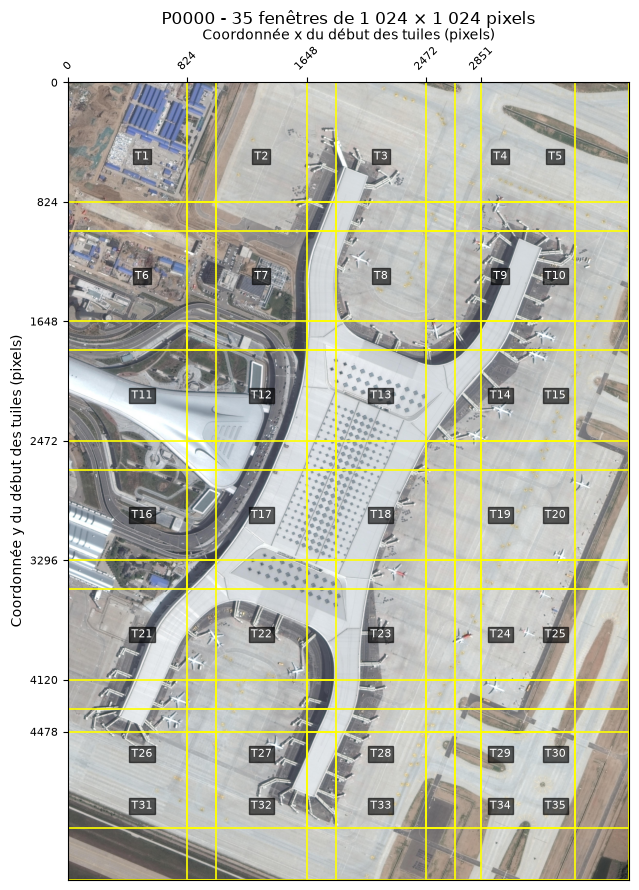

In [24]:
# P0000 est assez grande pour montrer plusieurs rangées de tuiles.
example_image = preprocessed_images_df.loc[
    (preprocessed_images_df["split"] == "train")
    & (preprocessed_images_df["image_id"] == "P0000")
].iloc[0]

example_tiles = tile_manifest_df.loc[
    (tile_manifest_df["split"] == example_image["split"])
    & (tile_manifest_df["source_image_id"] == example_image["image_id"])
].sort_values(["y_start", "x_start"])
display(example_tiles.head())
#display(example_tiles.iloc[4])
with Image.open(example_image["image_path"]) as source_image:
    displayed_image = np.asarray(source_image.convert("RGB"))

figure, axis = plt.subplots(figsize=(9, 9))
axis.imshow(displayed_image)

# enumerate numérote les tuiles dans leur ordre de lecture.
for tile_number, tile in enumerate(
    example_tiles.itertuples(index=False), start=1
):
    # Rectangle trace la fenêtre sans modifier les pixels de l'image.
    axis.add_patch(
        Rectangle(
            (tile.x_start, tile.y_start),
            tile.content_width,
            tile.content_height,
            fill=False,
            edgecolor="yellow",
            linewidth=1.2,
        )
    )

    # Le centre est obtenu en ajoutant la moitié de chaque dimension.
    tile_center_x = tile.x_start + tile.content_width / 2
    tile_center_y = tile.y_start + tile.content_height / 2
    axis.text(
        tile_center_x,
        tile_center_y,
        f"T{tile_number}",
        color="white",
        fontsize=8,
        ha="center",
        va="center",
        bbox={"facecolor": "black", "alpha": 0.6, "pad": 1.5},
    )

# Les axes indiquent seulement les coordonnées où chaque tuile commence.
x_starts = sorted(example_tiles["x_start"].unique())
y_starts = sorted(example_tiles["y_start"].unique())
axis.set_xticks(x_starts)
axis.set_yticks(y_starts)
axis.xaxis.tick_top()
axis.xaxis.set_label_position("top")
axis.set_xlabel("Coordonnée x du début des tuiles (pixels)")
axis.set_ylabel("Coordonnée y du début des tuiles (pixels)")
axis.tick_params(axis="x", rotation=45, labelsize=8)
axis.tick_params(axis="y", labelsize=8)
axis.set_title(
    f"P0000 - {len(example_tiles)} fenêtres de 1 024 × 1 024 pixels",
    pad=42,
)
figure.tight_layout()
plt.show()

#### Résultat du tuilage

Le manifeste contient 31 849 tuiles provenant des 2 805 images conservées : 15 719 pour l'entraînement, 5 297 pour la validation et 10 833 pour le test. Les images plus petites que 1 024 pixels dans une dimension seront complétées par du padding uniquement sur leur bord droit ou inférieur.

Chaque ligne conserve l'identifiant, le chemin et l'ensemble de l'image source. La séparation a donc lieu au niveau des images avant le découpage, ce qui empêche les tuiles très semblables d'une même scène de se retrouver à la fois dans l'entraînement et dans la validation.

### 4 - Traiter les objets coupés par le tuilage

Une OBB peut traverser le bord d'une tuile. Nous calculons alors son intersection exacte avec la tuile et la proportion de surface encore visible :

fraction visible = aire de l'objet dans la tuile / aire complète de l'objet

Une copie est annotée lorsqu'au moins 70 % de l'objet reste visible. Ce seuil conserve presque tous les objets sources tout en évitant d'apprendre à partir de fragments trop incomplets. Le chevauchement peut faire apparaître le même objet dans plusieurs tuiles, mais ces copies restent toujours dans le même ensemble que leur image source.

In [25]:
# Les alias distinguent le Polygon de Shapely de celui de Matplotlib.
from shapely.geometry import Polygon as ShapelyPolygon
from shapely.geometry import box as shapely_box


def intersect_object_with_tile(vertices, tile_window):
    """Renvoie la partie visible d'un objet et sa fraction de surface."""

    object_polygon = ShapelyPolygon(vertices)
    if object_polygon.area <= 0:
        raise ValueError("L'objet doit avoir une surface positive.")

    x_start, y_start, x_stop, y_stop = tile_window
    tile_polygon = shapely_box(x_start, y_start, x_stop, y_stop)

    # intersection conserve seulement la géométrie commune aux deux polygones.
    visible_geometry = object_polygon.intersection(tile_polygon)
    visible_fraction = visible_geometry.area / object_polygon.area

    return visible_geometry, visible_fraction


# Dans cet exemple, une partie de l'objet dépasse le bord x = 1 024.
example_object = [(800, 200), (1100, 200), (1100, 500), (800, 500)]
_, example_fraction = intersect_object_with_tile(
    example_object, (0, 0, TILE_SIZE, TILE_SIZE)
)
print("Fraction visible de l'exemple :", round(100 * example_fraction, 2), "%")

Fraction visible de l'exemple : 74.67 %


In [26]:
# Cet identifiant permet de suivre un objet même s'il apparaît dans plusieurs tuiles.
validated_objects_df["source_object_id"] = (
    validated_objects_df["split"]
    + "__"
    + validated_objects_df["image_id"]
    + "__object_"
    + validated_objects_df["object_index"].astype(str)
)

# Deux objets portant le même identifiant seraient mélangés lors des jointures.
if validated_objects_df["source_object_id"].duplicated().any():
    raise ValueError("Des identifiants d'objets sont dupliqués.")

display(
    validated_objects_df[
        ["source_object_id", "split", "image_id", "object_index"]
    ].head()
)

,source_object_id,split,image_id,object_index
0,train__P0000__object_0,train,P0000,0
1,train__P0000__object_1,train,P0000,1
2,train__P0000__object_2,train,P0000,2
3,train__P0000__object_3,train,P0000,3
4,train__P0000__object_4,train,P0000,4


In [27]:
# Ce groupby permet de retrouver rapidement les tuiles d'une image source.
tiles_by_image = tile_manifest_df.groupby(
    ["split", "source_image_id"], sort=False
)
intersection_records = []

# Les objets sont traités image par image pour ne jamais mélanger les sources.
for image_key, image_objects in validated_objects_df.groupby(
    ["split", "image_id"], sort=False
):
    image_tiles = tiles_by_image.get_group(image_key)

    for object_row in image_objects.itertuples(index=False):
        # La HBB élimine rapidement les tuiles sans recouvrement possible.
        candidate_mask = (
            (image_tiles["x_start"] < object_row.max_x)
            & (image_tiles["x_stop"] > object_row.min_x)
            & (image_tiles["y_start"] < object_row.max_y)
            & (image_tiles["y_stop"] > object_row.min_y)
        )
        candidate_tiles = image_tiles.loc[candidate_mask]

        # Shapely effectue ensuite le calcul exact seulement sur ces candidates.
        for tile_row in candidate_tiles.itertuples(index=False):
            tile_window = (
                tile_row.x_start, tile_row.y_start,
                tile_row.x_stop, tile_row.y_stop,
            )
            visible_geometry, visible_fraction = intersect_object_with_tile(
                object_row.vertices, tile_window
            )

            # Un simple contact avec un bord ne possède aucune surface.
            if visible_geometry.area <= 0:
                continue

            # Shapely répète le premier sommet à la fin; [:-1] retire ce doublon.
            visible_vertices = list(visible_geometry.exterior.coords)[:-1]
            intersection_records.append(
                {
                    "source_object_id": object_row.source_object_id,
                    "tile_id": tile_row.tile_id,
                    "split": object_row.split,
                    "source_image_id": object_row.image_id,
                    "object_index": object_row.object_index,
                    "class_name": object_row.class_name,
                    "difficult": object_row.difficult,
                    "x_start": tile_row.x_start,
                    "y_start": tile_row.y_start,
                    "visible_area_px2": visible_geometry.area,
                    "visible_fraction": visible_fraction,
                    # La tolérance évite de confondre un arrondi avec une coupure.
                    "is_truncated": visible_fraction < 1.0 - 1e-9,
                    "visible_vertices_source": visible_vertices,
                }
            )

object_tile_intersections_df = pd.DataFrame(intersection_records)
covered_objects = object_tile_intersections_df["source_object_id"].nunique()
if covered_objects != len(validated_objects_df):
    raise ValueError("Certains objets ne rencontrent aucune tuile.")

print("Intersections de surface positive :", len(object_tile_intersections_df))
print("Objets sources couverts :", covered_objects)
print("Intersections tronquées :", int(object_tile_intersections_df["is_truncated"].sum()))

Intersections de surface positive : 269956
Objets sources couverts : 127656
Intersections tronquées : 35882


In [28]:
# Une annotation est conservée si au moins 70 % de l'objet reste visible.
MIN_VISIBLE_FRACTION = 0.70
retained_tile_objects_df = object_tile_intersections_df.loc[
    object_tile_intersections_df["visible_fraction"] >= MIN_VISIBLE_FRACTION
].copy()


def translate_vertices_to_tile(vertices, x_start, y_start):
    """Transforme les coordonnées de l'image en coordonnées de la tuile."""

    # Le coin supérieur gauche de la tuile devient le nouveau point (0, 0).
    return [(float(x - x_start), float(y - y_start)) for x, y in vertices]


# axis=1 transmet à la fonction les informations d'une annotation complète.
retained_tile_objects_df["visible_vertices_local"] = (
    retained_tile_objects_df.apply(
        lambda object_row: translate_vertices_to_tile(
            object_row["visible_vertices_source"],
            object_row["x_start"],
            object_row["y_start"],
        ),
        axis=1,
    )
)

def vertices_are_inside_tile(vertices):
    """Vérifie que tous les sommets d'un objet restent dans sa tuile."""

    # La petite tolérance absorbe seulement les erreurs d'arrondi.
    tolerance = 1e-9
    for x, y in vertices:
        x_is_valid = -tolerance <= x <= TILE_SIZE + tolerance
        y_is_valid = -tolerance <= y <= TILE_SIZE + tolerance
        if not (x_is_valid and y_is_valid):
            return False

    return True


# apply vérifie chaque objet et all exige que tous les résultats soient vrais.
local_vertices_are_valid = (
    retained_tile_objects_df["visible_vertices_local"]
    .apply(vertices_are_inside_tile)
    .all()
)
if not local_vertices_are_valid:
    raise ValueError("Des sommets locaux sortent de leur tuile.")

print("Annotations retenues :", len(retained_tile_objects_df))
print("Objets sources représentés :", retained_tile_objects_df["source_object_id"].nunique())
print("Tous les sommets locaux sont valides :", local_vertices_are_valid)
display(
    retained_tile_objects_df[
        ["tile_id", "visible_vertices_source", "visible_vertices_local"]
    ].head(1)
)

Annotations retenues : 245822
Objets sources représentés : 127578
Tous les sommets locaux sont valides : True


,tile_id,visible_vertices_source,visible_vertices_local
0,train__P0000__s1024__x2472_3496__y1648_2672,"[(2805.0, 2502.0), (2888.0, 2468.0), (2861.0, ...","[(333.0, 854.0), (416.0, 820.0), (389.0, 737.0..."


#### Résultat du traitement des objets coupés

Les 127 656 objets valides produisent 269 956 intersections de surface positive en raison du chevauchement entre les tuiles. Après le seuil de visibilité de 70 %, 245 822 annotations sont conservées et représentent 127 578 objets sources. Seuls 78 objets ne possèdent aucune copie suffisamment complète.

Les sommets sont ensuite exprimés relativement au coin supérieur gauche de leur tuile et restent tous entre 0 et 1 024 pixels. Les fragments rejetés ne seront pas automatiquement considérés comme du fond : cette distinction sera faite lors de la construction des ensembles pour éviter d'apprendre au modèle qu'un fragment réel est de l'arrière-plan.

### 5 - Convertir les annotations vers les formats des détecteurs

YOLO-OBB représente une annotation par un identifiant de classe suivi de quatre sommets orientés. Les huit coordonnées sont divisées par 1 024 afin d'être comprises entre 0 et 1.

Faster R-CNN utilise plutôt une boîte horizontale sous la forme `(x_min, y_min, x_max, y_max)`. Cette conversion est plus simple, mais elle perd l'orientation et peut inclure davantage d'arrière-plan. La classe 0 est réservée au fond dans Faster R-CNN, alors que YOLO numérote directement les classes à partir de 0.

In [29]:
# Cette liste ordonnée fixe le même numéro de classe dans tout le projet.
DOTA_CLASS_NAMES = [
    "plane", "ship", "storage-tank", "baseball-diamond",
    "tennis-court", "basketball-court", "ground-track-field",
    "harbor", "bridge", "large-vehicle", "small-vehicle",
    "helicopter", "roundabout", "soccer-ball-field",
    "swimming-pool",
]

# enumerate associe chaque nom à sa position, en commençant par zéro.
class_to_yolo_id = {
    class_name: class_id
    for class_id, class_name in enumerate(DOTA_CLASS_NAMES)
}
retained_tile_objects_df["yolo_class_id"] = (
    retained_tile_objects_df["class_name"].map(class_to_yolo_id)
)

if retained_tile_objects_df["yolo_class_id"].isna().any():
    raise ValueError("Une classe ne possède pas d'identifiant YOLO.")

retained_tile_objects_df["yolo_class_id"] = (
    retained_tile_objects_df["yolo_class_id"].astype("int64")
)
# Faster R-CNN réserve zéro au fond; ses objets commencent donc à un.
retained_tile_objects_df["faster_rcnn_class_id"] = (
    retained_tile_objects_df["yolo_class_id"] + 1
)

class_mapping_df = pd.DataFrame(
    {
        "class_name": DOTA_CLASS_NAMES,
        "yolo_class_id": range(len(DOTA_CLASS_NAMES)),
        "faster_rcnn_class_id": range(1, len(DOTA_CLASS_NAMES) + 1),
    }
)
display(class_mapping_df)

,class_name,yolo_class_id,faster_rcnn_class_id
0,plane,0,1
1,ship,1,2
2,storage-tank,2,3
3,baseball-diamond,3,4
4,tennis-court,4,5
5,basketball-court,5,6
6,ground-track-field,6,7
7,harbor,7,8
8,bridge,8,9
9,large-vehicle,9,10


In [30]:
from itertools import combinations

# Une intersection peut produire de 4 à 7 sommets, mais YOLO en exige 4.
vertex_counts = retained_tile_objects_df["visible_vertices_local"].map(len)
display(
    vertex_counts.value_counts().sort_index().rename("annotations").to_frame()
)


def reduce_polygon_to_quadrilateral(vertices):
    """Conserve les quatre sommets couvrant la plus grande surface."""

    if len(vertices) < 4:
        raise ValueError("Le polygone visible possède moins de quatre sommets.")
    if len(vertices) == 4:
        return list(vertices)

    best_vertices = None
    largest_area = 0.0

    # combinations essaie chaque groupe possible de quatre sommets.
    for vertex_indices in combinations(range(len(vertices)), 4):
        candidate_vertices = [vertices[index] for index in vertex_indices]
        candidate_area = compute_polygon_area(candidate_vertices)
        if candidate_area > largest_area:
            best_vertices = candidate_vertices
            largest_area = candidate_area

    return best_vertices


retained_tile_objects_df["yolo_obb_vertices_local"] = (
    retained_tile_objects_df["visible_vertices_local"]
    .map(reduce_polygon_to_quadrilateral)
)

# Les fonctions déjà définies vérifient le nombre et la position des sommets.
yolo_quadrilaterals_are_valid = (
    retained_tile_objects_df["yolo_obb_vertices_local"]
    .apply(
        lambda vertices: len(vertices) == 4
        and vertices_are_inside_tile(vertices)
    )
    .all()
)
if not yolo_quadrilaterals_are_valid:
    raise ValueError("Des quadrilatères YOLO sont invalides.")

print("Polygones déjà à quatre sommets :", int((vertex_counts == 4).sum()))
print("Polygones réduits :", int((vertex_counts > 4).sum()))

,annotations
visible_vertices_local,
4,240258
5,5430
6,132
7,2


Polygones déjà à quatre sommets : 240258
Polygones réduits : 5564


In [31]:
def normalize_vertices_for_yolo(vertices):
    """Divise les coordonnées locales par la taille de la tuile."""

    return [(float(x / TILE_SIZE), float(y / TILE_SIZE)) for x, y in vertices]


def normalized_vertices_are_valid(vertices):
    """Vérifie que toutes les coordonnées sont comprises entre 0 et 1."""

    for x, y in vertices:
        if not (0.0 <= x <= 1.0 and 0.0 <= y <= 1.0):
            return False
    return True


retained_tile_objects_df["yolo_obb_vertices_normalized"] = (
    retained_tile_objects_df["yolo_obb_vertices_local"]
    .map(normalize_vertices_for_yolo)
)
normalized_coordinates_are_valid = (
    retained_tile_objects_df["yolo_obb_vertices_normalized"]
    .apply(normalized_vertices_are_valid)
    .all()
)
if not normalized_coordinates_are_valid:
    raise ValueError("Des coordonnées YOLO sortent de l'intervalle [0, 1].")

print("Coordonnées YOLO valides :", normalized_coordinates_are_valid)
display(
    retained_tile_objects_df[
        ["yolo_obb_vertices_local", "yolo_obb_vertices_normalized"]
    ].head(1)
)

Coordonnées YOLO valides : True


,yolo_obb_vertices_local,yolo_obb_vertices_normalized
0,"[(333.0, 854.0), (416.0, 820.0), (389.0, 737.0...","[(0.3251953125, 0.833984375), (0.40625, 0.8007..."


In [32]:
def convert_visible_polygon_to_hbb(vertices):
    """Construit la plus petite HBB contenant tous les sommets visibles."""

    x_coordinates = [x for x, _ in vertices]
    y_coordinates = [y for _, y in vertices]
    return (
        float(min(x_coordinates)),
        float(min(y_coordinates)),
        float(max(x_coordinates)),
        float(max(y_coordinates)),
    )


def hbb_is_valid(horizontal_box):
    """Vérifie l'ordre et les limites d'une boîte horizontale."""

    x_min, y_min, x_max, y_max = horizontal_box
    return (
        0.0 <= x_min < x_max <= TILE_SIZE
        and 0.0 <= y_min < y_max <= TILE_SIZE
    )


retained_tile_objects_df["faster_rcnn_hbb_local"] = (
    retained_tile_objects_df["visible_vertices_local"]
    .map(convert_visible_polygon_to_hbb)
)
faster_rcnn_boxes_are_valid = (
    retained_tile_objects_df["faster_rcnn_hbb_local"]
    .apply(hbb_is_valid)
    .all()
)
if not faster_rcnn_boxes_are_valid:
    raise ValueError("Des HBB Faster R-CNN sont invalides.")

print("HBB Faster R-CNN valides :", faster_rcnn_boxes_are_valid)
display(
    retained_tile_objects_df[
        ["visible_vertices_local", "faster_rcnn_hbb_local"]
    ].head(1)
)

HBB Faster R-CNN valides : True


,visible_vertices_local,faster_rcnn_hbb_local
0,"[(333.0, 854.0), (416.0, 820.0), (389.0, 737.0...","(281.0, 737.0, 416.0, 854.0)"


In [33]:
def format_yolo_obb_label(class_id, normalized_vertices):
    """Forme une ligne YOLO : une classe suivie de huit coordonnées."""

    # In: (0 , [(0, 0), (1, 0), (1, 1), (0, 1)])
    # Out: "0 0.000000 0.000000 ... 0.000000 1.000000" (9 valeurs)

    flattened_coordinates = []
    for x_normalized, y_normalized in normalized_vertices:
        flattened_coordinates.extend([x_normalized, y_normalized])

    # Six décimales conservent la précision sans allonger inutilement le fichier.
    coordinate_text = " ".join(
        f"{coordinate:.6f}" for coordinate in flattened_coordinates
    )
    return f"{int(class_id)} {coordinate_text}"


example_annotation = retained_tile_objects_df.iloc[0]
example_yolo_label = format_yolo_obb_label(
    example_annotation["yolo_class_id"],
    example_annotation["yolo_obb_vertices_normalized"],
)
if len(example_yolo_label.split()) != 9:
    raise ValueError("Une ligne YOLO-OBB doit contenir neuf valeurs.")

print("Classe :", example_annotation["class_name"])
print("Ligne YOLO-OBB :", example_yolo_label)
print("HBB Faster R-CNN :", example_annotation["faster_rcnn_hbb_local"])

Classe : plane
Ligne YOLO-OBB : 0 0.325195 0.833984 0.406250 0.800781 0.379883 0.719727 0.274414 0.742188
HBB Faster R-CNN : (281.0, 737.0, 416.0, 854.0)


#### Résultat des conversions

Parmi les 245 822 annotations retenues, 240 258 possèdent déjà quatre sommets et 5 564 polygones issus d'une coupure doivent être réduits à quatre sommets pour YOLO-OBB. Toutes les coordonnées YOLO sont ensuite normalisées entre 0 et 1.

La HBB de Faster R-CNN est calculée avec tous les sommets visibles : elle contient donc l'objet, mais abandonne son orientation. Les 15 classes de DOTA-v1.0 reçoivent les identifiants 0 à 14 pour YOLO et 1 à 15 pour Faster R-CNN. Lors du passage à DOTA-v1.5, `container-crane` sera simplement ajoutée à la fin avec les identifiants 15 et 16.

### 6 - Distinguer les tuiles positives, ambiguës et de fond

Une tuile positive contient au moins une annotation conservée à 70 %. Une tuile ambiguë rencontre un objet réel, mais seulement sous forme de fragment rejeté. Elle est exclue pour ne pas apprendre au modèle que ce fragment est du fond. Une vraie tuile de fond ne rencontre aucun objet annoté.

Une tuile positive peut aussi contenir d'autres fragments visibles à moins de 70 %. Ils restent dans l'image, mais ne sont pas ajoutés aux annotations. Cela produit un peu de bruit d'étiquetage; le chevauchement le réduit sans l'éliminer complètement.

Toutes les tuiles positives sont conservées. Pour l'entraînement, nous sélectionnons 10 % des vrais fonds afin de fournir des exemples négatifs sans qu'ils deviennent trop nombreux. La validation garde tous ses positifs et tous ses fonds pour mesurer les performances sur sa distribution complète.

In [34]:
# Le test est exclu ici, car ses annotations ne sont pas publiques.
labeled_tile_manifest_df = tile_manifest_df.loc[
    tile_manifest_df["split"].isin(["train", "validation"])
].copy()

retained_tile_ids = set(retained_tile_objects_df["tile_id"])
intersecting_tile_ids = set(object_tile_intersections_df["tile_id"])
labeled_tile_manifest_df["has_retained_object"] = (
    labeled_tile_manifest_df["tile_id"].isin(retained_tile_ids)
)
labeled_tile_manifest_df["has_any_intersection"] = (
    labeled_tile_manifest_df["tile_id"].isin(intersecting_tile_ids)
)

# Toutes les tuiles commencent comme de vrais fonds.
labeled_tile_manifest_df["tile_category"] = "background"

# Une intersection sans objet retenu rend d'abord la tuile ambiguë.
labeled_tile_manifest_df.loc[
    labeled_tile_manifest_df["has_any_intersection"], "tile_category"
] = "ambiguous"

# La catégorie positive est appliquée en dernier et possède la priorité.
labeled_tile_manifest_df.loc[
    labeled_tile_manifest_df["has_retained_object"], "tile_category"
] = "positive"

tile_category_summary_df = pd.crosstab(
    labeled_tile_manifest_df["split"],
    labeled_tile_manifest_df["tile_category"],
).reindex(
    columns=["positive", "ambiguous", "background"],
    fill_value=0,
)
tile_category_summary_df["total"] = tile_category_summary_df.sum(axis=1)
display(tile_category_summary_df)

tile_category,positive,ambiguous,background,total
split,,,,
train,9715,732,5272,15719
validation,3066,275,1956,5297


In [35]:
# 10 % apporte des exemples de fond sans dominer les tuiles positives.
TRAIN_BACKGROUND_FRACTION = 0.10
# La graine rend le tirage aléatoire identique à chaque exécution.
RANDOM_SEED = 42

train_positive_tiles_df = labeled_tile_manifest_df.loc[
    (labeled_tile_manifest_df["split"] == "train")
    & (labeled_tile_manifest_df["tile_category"] == "positive")
]
train_background_tiles_df = labeled_tile_manifest_df.loc[
    (labeled_tile_manifest_df["split"] == "train")
    & (labeled_tile_manifest_df["tile_category"] == "background")
].sample(
    frac=TRAIN_BACKGROUND_FRACTION,
    random_state=RANDOM_SEED,
)

# Toutes les tuiles non ambiguës de validation sont conservées.
validation_tiles_df = labeled_tile_manifest_df.loc[
    (labeled_tile_manifest_df["split"] == "validation")
    & labeled_tile_manifest_df["tile_category"].isin(
        ["positive", "background"]
    )
]

# Sans annotations publiques, les tuiles du test gardent la catégorie unknown.
test_tiles_df = tile_manifest_df.loc[
    tile_manifest_df["split"] == "test"
].copy()
test_tiles_df["tile_category"] = "unknown"

manifest_columns = list(tile_manifest_df.columns) + ["tile_category"]
generation_tile_manifest_df = pd.concat(
    [
        train_positive_tiles_df[manifest_columns],
        train_background_tiles_df[manifest_columns],
        validation_tiles_df[manifest_columns],
        test_tiles_df[manifest_columns],
    ],
    ignore_index=True,
).sort_values(
    ["split", "source_image_id", "y_start", "x_start"]
).reset_index(drop=True)

generation_summary_df = pd.crosstab(
    generation_tile_manifest_df["split"],
    generation_tile_manifest_df["tile_category"],
).reindex(
    index=["train", "validation", "test"],
    columns=["positive", "background", "unknown"],
    fill_value=0,
)
generation_summary_df["total"] = generation_summary_df.sum(axis=1)
display(generation_summary_df)

tile_category,positive,background,unknown,total
split,,,,
train,9715,527,0,10242
validation,3066,1956,0,5022
test,0,0,10833,10833


#### Résultat de la sélection

L'entraînement contient 9 715 tuiles positives, 732 tuiles ambiguës et 5 272 vrais fonds. Les tuiles ambiguës sont retirées et 527 fonds sont tirés de façon reproductible, ce qui donne 10 242 tuiles d'entraînement.

La validation conserve 3 066 tuiles positives et 1 956 fonds, soit 5 022 tuiles. Les 10 833 tuiles de test sont toutes conservées, mais restent marquées `unknown` puisqu'elles ne possèdent pas de vérité terrain publique.

### 7 - Créer les variables dérivées

Les annotations brutes donnent la classe et les sommets, mais elles ne décrivent pas directement la taille relative, la forme ou le contexte d'un objet. Nous calculons donc des variables qui pourront expliquer les performances des détecteurs et servir plus tard à l'analyse causale.

Pour chaque objet source, nous conservons sa surface relative, les dimensions de son OBB, son ratio longueur-largeur et la position normalisée de son centre. Nous résumons ensuite son contexte par le nombre d'autres objets visibles dans les tuiles qu'il rencontre. Ces informations existent avant toute prédiction : ce ne sont donc pas encore des résultats du modèle.

In [36]:
def compute_obb_side_features(vertices):
    """Calcule les deux côtés principaux et leur ratio."""

    side_lengths = []
    for index in range(4):
        x1, y1 = vertices[index]
        x2, y2 = vertices[(index + 1) % 4]
        # hypot applique la distance euclidienne entre deux sommets.
        side_lengths.append(math.hypot(x2 - x1, y2 - y1))

    long_side_px = max(side_lengths)
    short_side_px = min(side_lengths)
    if short_side_px <= 0:
        raise ValueError("Une OBB possède un côté nul.")

    return long_side_px, short_side_px, long_side_px / short_side_px


# In: rectangle de côtés 4 et 2 -> Out: (4.0, 2.0, 2.0)
shape_values = validated_objects_df["vertices"].apply(
    compute_obb_side_features
)
shape_columns = [
    "obb_long_side_px", "obb_short_side_px", "obb_aspect_ratio"
]
# Chaque tuple retourné devient une ligne de trois colonnes.
validated_objects_df[shape_columns] = pd.DataFrame(
    shape_values.tolist(),
    index=validated_objects_df.index,
    columns=shape_columns,
)

# La surface relative compare l'objet à son image source complète.
validated_objects_df["relative_area"] = (
    validated_objects_df["area_px2"]
    / (validated_objects_df["width"] * validated_objects_df["height"])
)
# La moyenne des quatre sommets donne le centre de l'OBB.
validated_objects_df["center_x_normalized"] = (
    validated_objects_df["vertices"].map(
        lambda vertices: sum(x for x, _ in vertices) / 4
    ) / validated_objects_df["width"]
)
validated_objects_df["center_y_normalized"] = (
    validated_objects_df["vertices"].map(
        lambda vertices: sum(y for _, y in vertices) / 4
    ) / validated_objects_df["height"]
)
validated_objects_df["gsd_missing"] = validated_objects_df["gsd"].isna()
validated_objects_df["tile_size_px"] = TILE_SIZE

display(
    validated_objects_df[
        ["relative_area", *shape_columns,
        "center_x_normalized", "center_y_normalized"]
    ].describe().loc[["min", "50%", "mean", "max"]].round(3)
)

,relative_area,obb_long_side_px,obb_short_side_px,obb_aspect_ratio,center_x_normalized,center_y_normalized
min,0.000,3.000,1.000,1.000,0.002,0.002
50%,0.000,43.324,17.263,2.561,0.487,0.499
mean,0.001,66.928,27.489,2.871,0.491,0.501
max,0.378,2486.899,1093.000,68.839,0.999,0.998


In [37]:
# nunique compte chaque objet une seule fois, même s'il possède plusieurs copies.
objects_per_tile = (
    object_tile_intersections_df.groupby("tile_id")["source_object_id"]
    .nunique()
    .rename("visible_object_count")
)

intersections_with_density_df = object_tile_intersections_df.merge(
    objects_per_tile,
    on="tile_id",
    how="left",
    validate="many_to_one",
)
# On retire l'objet lui-même pour ne compter que ses voisins.
intersections_with_density_df["nearby_object_count"] = (
    intersections_with_density_df["visible_object_count"] - 1
)

local_density_df = (
    intersections_with_density_df.groupby("source_object_id")
    .agg(
        mean_nearby_object_count=("nearby_object_count", "mean"),
        max_nearby_object_count=("nearby_object_count", "max"),
    )
    .reset_index()
)

# La couverture indique combien de tuiles montrent chaque objet.
object_coverage_df = (
    object_tile_intersections_df.groupby("source_object_id")
    .agg(
        intersecting_tile_count=("tile_id", "nunique"),
        max_visible_fraction=("visible_fraction", "max"),
    )
    .reset_index()
)
retained_tile_count = (
    retained_tile_objects_df.groupby("source_object_id")["tile_id"]
    .nunique()
    .rename("retained_tile_count")
)
object_context_features_df = object_coverage_df.merge(
    retained_tile_count,
    left_on="source_object_id",
    right_index=True,
    how="left",
    validate="one_to_one",
).merge(
    local_density_df,
    on="source_object_id",
    how="left",
    validate="one_to_one",
)
# Une valeur absente signifie qu'aucune copie n'a atteint le seuil de 70 %.
object_context_features_df["retained_tile_count"] = (
    object_context_features_df["retained_tile_count"].fillna(0).astype(int)
)
object_context_features_df["has_retained_tile"] = (
    object_context_features_df["retained_tile_count"] > 0
)

print("Objets décrits :", len(object_context_features_df))
print("Objets sans copie retenue :", int(
    (~object_context_features_df["has_retained_tile"]).sum()
))
display(object_context_features_df.head())

Objets décrits : 127656
Objets sans copie retenue : 78


,source_object_id,intersecting_tile_count,max_visible_fraction,retained_tile_count,mean_nearby_object_count,max_nearby_object_count,has_retained_tile
0,train__P0000__object_0,4,1.0,1,4.00,5,True
1,train__P0000__object_1,4,1.0,4,5.75,8,True
2,train__P0000__object_10,1,1.0,1,18.00,18,True
3,train__P0000__object_100,1,1.0,1,6.00,6,True
4,train__P0000__object_101,2,1.0,2,8.50,11,True


### 8 - Construire la base de la future analyse causale

L'unité d'observation est un objet réel de validation. Même si le chevauchement le fait apparaître dans plusieurs tuiles, son identifiant `source_object_id` doit rester présent une seule fois dans la table. Utiliser la validation permet d'étudier plus tard des prédictions réalisées sur des images qui n'ont pas servi à entraîner le détecteur.

Cette première version rassemble seulement les caractéristiques connues avant les prédictions : classe, géométrie, position, difficulté, source, GSD, couverture et densité locale. Le traitement causal et le résultat de détection seront définis puis ajoutés dans les questions 4 et 5.

In [38]:
causal_object_columns = [
    "source_object_id", "split", "image_id", "object_index",
    "class_name", "difficult", "image_source", "gsd",
    "gsd_missing", "width", "height", "area_px2",
    "relative_area", "orientation_deg", "obb_long_side_px",
    "obb_short_side_px", "obb_aspect_ratio", "was_clipped",
    "center_x_normalized", "center_y_normalized", "tile_size_px",
]

# Une ligne est sélectionnée par objet source, et non par copie dans une tuile.
causal_base_df = validated_objects_df.loc[
    validated_objects_df["split"] == "validation",
    causal_object_columns,
].copy()
causal_base_df["yolo_class_id"] = (
    causal_base_df["class_name"].map(class_to_yolo_id).astype(int)
)
causal_base_df = causal_base_df.rename(
    columns={"image_id": "source_image_id"}
)

# La jointure ajoute le contexte calculé à partir des tuiles.
causal_base_df = causal_base_df.merge(
    object_context_features_df,
    on="source_object_id",
    how="left",
    validate="one_to_one",
)

expected_object_count = (
    validated_objects_df["split"] == "validation"
).sum()
if len(causal_base_df) != expected_object_count:
    raise ValueError("La jointure a perdu ou dupliqué des objets.")
if not causal_base_df["source_object_id"].is_unique:
    raise ValueError("Un objet source apparaît plusieurs fois.")

preview_columns = [
    "source_object_id", "class_name", "relative_area",
    "orientation_deg", "mean_nearby_object_count",
    "retained_tile_count", "has_retained_tile",
]
print("Dimensions :", causal_base_df.shape)
print("Identifiants uniques :", causal_base_df["source_object_id"].is_unique)
display(causal_base_df[preview_columns].head())
#display(causal_base_df.head())



Dimensions : (28853, 28)
Identifiants uniques : True


,source_object_id,class_name,relative_area,orientation_deg,mean_nearby_object_count,retained_tile_count,has_retained_tile
0,validation__P0003__object_0,small-vehicle,0.000536,94.513988,47.0,2,True
1,validation__P0003__object_1,large-vehicle,0.001113,4.085617,47.0,2,True
2,validation__P0003__object_2,large-vehicle,0.001236,179.028978,47.0,2,True
3,validation__P0003__object_3,large-vehicle,0.001066,3.945186,47.0,2,True
4,validation__P0003__object_4,large-vehicle,0.001811,76.660751,47.0,2,True


In [39]:
# Ce fichier contient la table dérivée disponible dans le dossier de prétraitement.
causal_base_path = (
    project_dir / "outputs" / "dota_tiles_1024" / "metadata"
    / "causal_base_validation.csv"
)

# Le notebook final le lit sans le modifier ni le réenregistrer.
if causal_base_path.is_file():
    causal_base_df = pd.read_csv(causal_base_path)
    table_origin = "fichier de prétraitement existant"
else:
    # La table construite dans la cellule précédente reste utilisable en mémoire.
    table_origin = "table reconstruite en mémoire"

if not causal_base_df["source_object_id"].is_unique:
    raise ValueError("La base causale contient des objets dupliqués.")

print("Origine :", table_origin)
print("Dimensions :", causal_base_df.shape)
print("Aucun fichier n'a été écrit par cette cellule.")

Origine : fichier de prétraitement existant
Dimensions : (28853, 29)
Aucun fichier n'a été écrit par cette cellule.


### 9 - Réutiliser les fichiers produits par le premier notebook

Les cellules précédentes présentent les choix et les fonctions du prétraitement. La génération complète des 26 097 images a déjà été réalisée et validée dans le premier notebook. Nous relisons donc ses fichiers au lieu de les recréer ou de les remplacer.

Le manifeste décrit chaque tuile, la table d'annotations relie les objets sources à leurs copies et le mapping fixe les identifiants de classes des deux détecteurs. La cellule suivante effectue uniquement des lectures et des contrôles.

In [40]:
derived_dataset_dir = project_dir / "outputs" / "dota_tiles_1024"
metadata_dir = derived_dataset_dir / "metadata"
artifact_paths = {
    "manifeste": metadata_dir / "tile_manifest.csv",
    "annotations": metadata_dir / "object_annotations.csv",
    "classes": metadata_dir / "class_mapping.csv",
    "configuration YOLO": derived_dataset_dir / "dota_obb.yaml",
}
missing_artifacts = [
    name for name, path in artifact_paths.items() if not path.is_file()
]
if missing_artifacts:
    raise FileNotFoundError(f"Fichiers dérivés manquants : {missing_artifacts}")

saved_tile_manifest_df = pd.read_csv(artifact_paths["manifeste"])
# usecols évite de charger les coordonnées inutiles pour ce contrôle.
saved_annotations_df = pd.read_csv(
    artifact_paths["annotations"],
    usecols=["ground_truth_id", "tile_id", "split", "class_name"],
)
saved_class_mapping_df = pd.read_csv(artifact_paths["classes"])

if not saved_tile_manifest_df["tile_id"].is_unique:
    raise ValueError("Le manifeste contient des tuiles dupliquées.")
if not saved_annotations_df["ground_truth_id"].is_unique:
    raise ValueError("Des annotations dérivées sont dupliquées.")
if not set(saved_annotations_df["tile_id"]).issubset(
    set(saved_tile_manifest_df["tile_id"])
):
    raise ValueError("Une annotation désigne une tuile absente.")

saved_dataset_summary_df = (
    saved_tile_manifest_df.groupby("split")
    .agg(tiles=("tile_id", "size"))
)
saved_annotation_counts = saved_annotations_df.groupby("split").size()
saved_dataset_summary_df["annotations"] = saved_annotation_counts.reindex(
    saved_dataset_summary_df.index, fill_value=0
).astype(int)

display(saved_dataset_summary_df)
display(saved_class_mapping_df)
print("Lecture seule : aucun fichier n'a été modifié.")

,tiles,annotations
split,,
test,10833,0
train,10242,190018
validation,5022,55804


,class_name,yolo_class_id,faster_rcnn_class_id
0,plane,0,1
1,ship,1,2
2,storage-tank,2,3
3,baseball-diamond,3,4
4,tennis-court,4,5
5,basketball-court,5,6
6,ground-track-field,6,7
7,harbor,7,8
8,bridge,8,9
9,large-vehicle,9,10


Lecture seule : aucun fichier n'a été modifié.


### 10 - Synthèse de la question 2

Le prétraitement conserve les fichiers DOTA d'origine et respecte leurs ensembles. L'image corrompue `P1872` est exclue, 87 petits dépassements sont bornés et une géométrie non convexe est retirée. Les objets difficiles, petits ou rares restent présents afin de ne pas simplifier artificiellement la tâche.

Les images sont découpées en tuiles de 1 024 × 1 024 pixels avec un chevauchement de 200 pixels. Une annotation est conservée lorsqu'au moins 70 % de l'objet reste visible. Les tuiles entièrement ambiguës sont retirées et 10 % des vrais fonds d'entraînement sont conservés. Certains fragments inférieurs au seuil peuvent néanmoins rester visibles dans une tuile positive; ils constituent une limite mineure du prétraitement.

YOLO reçoit les sommets OBB normalisés, tandis que Faster R-CNN reçoit des HBB en pixels. Cette seconde représentation est compatible avec le modèle, mais perd l'orientation et ajoute souvent du fond autour des objets.

Le jeu dérivé DOTA-v1.0 contient 26 097 tuiles et 245 822 annotations. Une base séparée rassemble une ligne pour chacun des 28 853 objets de validation avec sa classe, sa géométrie, sa position, sa source, son GSD et sa densité locale. Le résultat des prédictions et le traitement causal seront ajoutés seulement après l'entraînement et la formulation de la question causale. Le même prétraitement sera ensuite appliqué aux annotations DOTA-v1.5, qui ajoutent la classe `container-crane`.

## Question 3 - Modèles prédictifs de détection

Cette question consiste à localiser et à classer les objets présents dans chaque tuile DOTA-v1.5. Pour un objet détecté, le modèle renvoie une classe, une boîte et un score de confiance.

Nous comparons YOLO11s-OBB, qui conserve l'orientation des objets, à Faster R-CNN, qui utilise des boîtes horizontales. Cette partie est prédictive : elle mesure la qualité des détections, sans encore chercher à expliquer leurs causes.

### 1 - Définir la tâche et le protocole

L'entrée d'un modèle est une tuile de 1 024 × 1 024 pixels. Sa sortie est une liste de détections appartenant aux 16 classes de DOTA-v1.5.

- L'ensemble d'entraînement sert à modifier les poids des modèles.
- L'ensemble de validation sert à suivre les performances et à retenir le meilleur checkpoint.
- L'ensemble de test DOTA n'est pas utilisé pour calculer nos métriques, car ses annotations ne sont pas fournies localement.

Les deux modèles utilisent les mêmes tuiles de validation, mais chacun est évalué dans son format natif : OBB pour YOLO et HBB pour Faster R-CNN.

### 2 - Comparer les deux architectures

| Modèle | Chemin suivi par une image | Sortie |
|---|---|---|
| YOLO11s-OBB | tuile → extraction des caractéristiques → prédiction directe | classe, confiance et OBB |
| Faster R-CNN | tuile → caractéristiques FPN → propositions RPN → classification des régions | classe, confiance et HBB |

YOLO est un détecteur en une étape : il produit directement ses détections à plusieurs échelles. Faster R-CNN est un détecteur en deux étapes : le RPN propose d'abord des zones susceptibles de contenir un objet, puis la tête RoI les classe et ajuste leurs boîtes.

Le FPN combine des détails fins et des informations plus globales, ce qui aide à traiter des objets de tailles différentes. Faster R-CNN sert ici de modèle de référence HBB; sa conversion des OBB en rectangles horizontaux perd toutefois l'angle et peut inclure davantage d'arrière-plan.

### 3 - Organiser le parcours d'apprentissage

Deux parcours YOLO ont finalement été étudiés :

```text
Poids COCO → DOTA-v1.0 → DOTA-v1.5   : transfert entre les deux versions
Poids COCO ────────────→ DOTA-v1.5   : apprentissage sans checkpoint DOTA-v1.0
```

Le premier parcours conserve les caractéristiques visuelles apprises sur DOTA-v1.0. Lors du passage de 15 à 16 classes, la tête est adaptée pour ajouter `container-crane` et un nouvel optimiseur est créé.

Le second parcours construit directement YOLO11s-OBB pour DOTA-v1.5. Les couches compatibles du modèle COCO sont transférées, tandis que la partie propre aux boîtes orientées et aux 16 classes est apprise sur DOTA-v1.5. Ce parcours fournit le checkpoint prédictif final, alors que le premier permet d'étudier l'effet du transfert sur la vitesse de convergence.

Faster R-CNN est entraîné directement avec les annotations DOTA-v1.5. Il part également de poids COCO, puis sa tête est remplacée pour produire 17 sorties : les 16 classes DOTA et l'arrière-plan.

### 4 - Entraîner YOLO11s-OBB sur DOTA-v1.0

Un pilote d'une heure a d'abord confirmé que la variante Small et un batch de 2 étaient compatibles avec la RTX 4060. Ce pilote avait transféré les poids compatibles du modèle COCO `yolo11s.pt`; la tête OBB incompatible avait été initialisée séparément. Le run principal DOTA-v1.0 est ensuite parti du meilleur poids du pilote avec un nouvel optimiseur sur les 15 classes.

La cellule suivante présente le noyau scientifique de l'entraînement. Le script complet ajoute surtout la reprise après interruption, le suivi du temps et les sauvegardes de récupération. Le booléen reste à `False` afin qu'une exécution complète du notebook ne relance pas l'entraînement.

In [41]:
from pathlib import Path

from ultralytics import YOLO

q3_project_dir = Path.cwd().resolve()
q3_v10_dataset_path = (
    q3_project_dir / "outputs" / "dota_tiles_1024" / "dota_obb.yaml"
)
q3_v10_initial_weights_path = (
    q3_project_dir / "outputs" / "yolo_runs"
    / "yolo11s_obb_pilot_1h" / "weights" / "best.pt"
)

# Cette protection empêche Run All de lancer plusieurs jours de calcul.
run_yolo_v10_training = False

q3_v10_training_parameters = {
    "data": str(q3_v10_dataset_path),
    "epochs": 810,       # Plafond; le script limitait aussi le run à 7 jours.
    "imgsz": 1024,       # Même taille que les tuiles préparées.
    "batch": 2,          # Deux tuiles sont traitées simultanément.
    "nbs": 64,           # Batch nominal utilisé par Ultralytics.
    "device": 0,         # Première carte graphique CUDA.
    "workers": 4,        # Quatre processus préparent les images.
    "amp": True,         # Précision mixte : moins de mémoire et de calcul.
    "optimizer": "AdamW",
    "lr0": 0.0005,       # Taux d'apprentissage initial.
    "momentum": 0.9,
    "weight_decay": 0.0005,
    "warmup_epochs": 1.0,
    "patience": 50,      # Arrêt si la validation ne progresse plus.
    "degrees": 180.0,    # Les objets aériens peuvent avoir tout angle.
    "flipud": 0.5,
    "fliplr": 0.5,
    "close_mosaic": 10,  # Retirer la mosaïque pendant la fin du run.
    "cache": False,      # Le jeu complet reste sur le disque.
    "seed": 42,
    "deterministic": True,
    "multi_scale": False, # Toutes les entrées restent à 1 024 pixels.
    "val": True,
    "save": True,
    "save_period": 25,
    "plots": True,
    "project": str(q3_project_dir / "outputs" / "yolo_runs"),
    "name": "yolo11s_obb_final_7d",
    "exist_ok": True,
}

if run_yolo_v10_training:
    if not q3_v10_dataset_path.is_file():
        raise FileNotFoundError(q3_v10_dataset_path)
    if not q3_v10_initial_weights_path.is_file():
        raise FileNotFoundError(q3_v10_initial_weights_path)

    q3_v10_model = YOLO(str(q3_v10_initial_weights_path), task="obb")
    if len(q3_v10_model.names) != 15:
        raise ValueError("Le checkpoint initial doit avoir 15 classes.")

    # resume n'est pas utilisé : un nouvel optimiseur est créé.
    q3_v10_model.train(**q3_v10_training_parameters)
else:
    print("Entraînement DOTA-v1.0 désactivé dans le notebook final.")
    print("Durée historique visée : 168 heures.(Non atteinte)")
    print("Meilleur checkpoint retenu : époque 273.")

Entraînement DOTA-v1.0 désactivé dans le notebook final.
Durée historique visée : 168 heures.(Non atteinte)
Meilleur checkpoint retenu : époque 273.


### 5 - Transférer YOLO de DOTA-v1.0 vers DOTA-v1.5

DOTA-v1.5 ajoute la classe `container-crane`. Nous rechargeons le meilleur checkpoint DOTA-v1.0, obtenu à l'époque 273 avec une mAP50-95 de 63,74 %, puis nous lançons un nouvel entraînement sur le YAML à 16 classes. Cette ancienne mAP décrit DOTA-v1.0 et ne doit pas être comparée directement aux résultats DOTA-v1.5.

Ultralytics conserve les poids compatibles du backbone, du neck et de la tête OBB, puis adapte la sortie au nombre de classes indiqué dans le nouveau YAML. Comme `resume` n'est pas utilisé, AdamW repart avec un état neuf : nous transférons les connaissances visuelles, mais pas l'ancien optimiseur.

La valeur `epochs=5000` était seulement un plafond technique pour un entraînement contrôlé par sa durée active. Le meilleur modèle est choisi avec la validation et peut donc être retenu bien avant ce plafond.

In [42]:
from pathlib import Path

from ultralytics import YOLO

q3_project_dir = Path.cwd().resolve()
q3_v15_dataset_path = (
    q3_project_dir / "outputs" / "dota_v15_tiles_1024" / "dota_obb.yaml"
)
q3_v10_best_weights_path = (
    q3_project_dir / "outputs" / "transfer_weights"
    / "yolo11s_obb_dota_v10_best_epoch273.pt"
)

# False documente le run sans le relancer pendant Run All.
run_yolo_v15_training = False

q3_v15_training_parameters = {
    "data": str(q3_v15_dataset_path),  # YAML DOTA-v1.5 à 16 classes.
    "epochs": 5000,      # Plafond; le script arrête selon le temps actif.
    "imgsz": 1024,
    "batch": 2,          # Valeur confirmée sur les tuiles très denses.
    "nbs": 64,
    "device": 0,
    "workers": 2,        # Valeur mesurée sur la RTX 5080.
    "amp": True,
    "optimizer": "AdamW",
    "lr0": 0.0005,
    "momentum": 0.9,
    "weight_decay": 0.0005,
    "warmup_epochs": 1.0,
    "patience": 50,
    "degrees": 180.0,
    "flipud": 0.5,
    "fliplr": 0.5,
    "close_mosaic": 10,
    "cache": False,
    "seed": 42,
    "deterministic": True,
    "multi_scale": False,
    "val": True,
    "save": True,
    "save_period": 25,
    "plots": True,
    "project": str(q3_project_dir / "outputs" / "yolo_runs"),
    "name": "yolo11s_obb_v15_rtx5080",
    "exist_ok": True,
}

if run_yolo_v15_training:
    if not q3_v15_dataset_path.is_file():
        raise FileNotFoundError(q3_v15_dataset_path)
    if not q3_v10_best_weights_path.is_file():
        raise FileNotFoundError(q3_v10_best_weights_path)

    q3_v15_model = YOLO(str(q3_v10_best_weights_path), task="obb")
    if len(q3_v15_model.names) != 15:
        raise ValueError("Le checkpoint source doit avoir 15 classes.")

    # Le YAML à 16 classes provoque l'adaptation de la tête au démarrage.
    q3_v15_model.train(**q3_v15_training_parameters)
else:
    print("Transfert DOTA-v1.0 vers DOTA-v1.5 non relancé.")
    print("Source : meilleur checkpoint DOTA-v1.0, époque 273.")

Transfert DOTA-v1.0 vers DOTA-v1.5 non relancé.
Source : meilleur checkpoint DOTA-v1.0, époque 273.


#### Variante finale : partir directement des poids COCO

Ce second run n'utilise aucun checkpoint DOTA-v1.0. `yolo11s.pt` contient un détecteur horizontal entraîné sur COCO; nous construisons donc d'abord l'architecture `yolo11s-obb.yaml`, puis nous copions uniquement les couches compatibles. La tête orientée absente du modèle COCO est initialisée avant l'apprentissage des 16 classes DOTA-v1.5.

Le plafond de 400 époques correspond au budget de 55 heures sur la RTX 5080. L'entraînement s'est terminé proprement à l'époque 366 lorsque ce budget a été atteint, et le meilleur checkpoint de validation provient de l'époque 313.

In [43]:
import torch


q3_coco_weights_path = q3_project_dir / "yolo11s.pt"

# Les réglages communs à DOTA-v1.5 ont été définis dans la cellule précédente.
# Cette copie change seulement les paramètres propres au run COCO direct.
q3_v15_clean_parameters = {
    **q3_v15_training_parameters,
    "epochs": 400,       # Plafond cohérent avec le budget de 55 heures.
    "patience": 150,     # Tolérer une longue convergence avant l'arrêt anticipé.
    "cos_lr": True,      # Faire diminuer progressivement le taux d'apprentissage.
    "lrf": 0.01,         # Taux final égal à 1 % du taux initial.
    "name": "yolo11s_obb_v15_clean_coco_55h",
}

run_yolo_v15_clean_training = False

if run_yolo_v15_clean_training:
    if not q3_coco_weights_path.is_file():
        raise FileNotFoundError(q3_coco_weights_path)

    # In : poids COCO HBB; Out : architecture OBB recevant les couches compatibles.
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)
    q3_v15_clean_model = YOLO("yolo11s-obb.yaml", task="obb")
    q3_v15_clean_model.load(str(q3_coco_weights_path))
    q3_v15_clean_model.train(**q3_v15_clean_parameters)
else:
    print("Entraînement COCO vers DOTA-v1.5 désactivé dans le notebook final.")
    print("Run historique : meilleur checkpoint à l'époque 313.")

Entraînement COCO vers DOTA-v1.5 désactivé dans le notebook final.
Run historique : meilleur checkpoint à l'époque 313.


### 6 - Construire Faster R-CNN pour DOTA-v1.5

Faster R-CNN constitue notre baseline comparative HBB standard, même s'il s'agit lui aussi d'un réseau profond. Son backbone ResNet50 extrait les caractéristiques, le FPN combine plusieurs échelles, le RPN propose des régions et la tête RoI classe ces régions tout en ajustant leurs boîtes.

La tête COCO d'origine est remplacée par une tête de 17 sorties : l'indice 0 représente l'arrière-plan interne et les indices 1 à 16 représentent les classes DOTA-v1.5. Le modèle apprend donc directement sur DOTA-v1.5, sans checkpoint DOTA-v1.0.

Le pilote d'une heure partait des poids COCO. Le run final a ensuite chargé uniquement les meilleurs poids de ce pilote et a créé un nouvel optimiseur. Les étapes de suivi et de récupération du script autonome ne sont pas reproduites ici.

In [44]:
from torchvision.models.detection import (
    FasterRCNN_ResNet50_FPN_V2_Weights,
    fasterrcnn_resnet50_fpn_v2,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

q3_faster_dota_class_count = 16
# Faster R-CNN réserve toujours la sortie 0 à l'arrière-plan.
q3_faster_output_count = q3_faster_dota_class_count + 1


def build_faster_rcnn_v15(use_coco_weights=True):
    """Construit Faster R-CNN avec une tête adaptée à DOTA-v1.5."""

    selected_weights = (
        FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
        if use_coco_weights
        else None
    )
    model = fasterrcnn_resnet50_fpn_v2(
        weights=selected_weights,
        weights_backbone=None,  # Les poids COCO contiennent déjà le backbone.
        min_size=1024,        # Conserver la résolution des tuiles.
        max_size=1024,
        # Les tuiles denses exigent davantage de propositions que COCO.
        rpn_post_nms_top_n_train=3000,
        rpn_post_nms_top_n_test=3000,
        box_score_thresh=0.05,       # Seuil bas pour préserver le rappel.
        box_detections_per_img=2500, # Maximum de sorties par tuile.
    )

    # cls_score.in_features donne la taille reçue par l'ancienne tête.
    input_feature_count = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(
        input_feature_count,
        q3_faster_output_count,
    )
    return model


# In : use_coco_weights=True
# Out : architecture Faster R-CNN avec 17 sorties, sans entraînement.
print("Fonction Faster R-CNN définie; aucun modèle n'a été entraîné.")

Fonction Faster R-CNN définie; aucun modèle n'a été entraîné.


### 7 - Charger les HBB et entraîner Faster R-CNN

Chaque élément du dataset contient une image et un dictionnaire cible. Ce dictionnaire associe à la tuile ses HBB, leurs classes, leurs surfaces et l'indicateur `iscrowd` attendu par Torchvision. Les identifiants de classe vont de 1 à 16, puisque 0 est réservé au fond.

Le nombre d'objets varie selon la tuile. La fonction `collate_detection_batch` conserve donc une liste d'images et une liste de cibles au lieu d'essayer de les empiler dans un seul tenseur de taille fixe.

Pendant l'apprentissage, Faster R-CNN renvoie quatre pertes : classification des régions, ajustement des HBB, présence d'un objet dans le RPN et ajustement des propositions du RPN. Leur somme sert à mettre à jour le réseau. Pour les tuiles extrêmes, qui peuvent contenir plus de 2 000 objets, le script complet calcule l'appariement du RPN par groupes de 32 annotations afin de réduire la mémoire sans modifier le résultat recherché.

In [45]:
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset


def collate_detection_batch(batch):
    """Sépare les images et les cibles sans empiler leurs boîtes."""

    return tuple(zip(*batch))


class DotaV15HbbDataset(Dataset):
    """Charge les tuiles DOTA-v1.5 et leurs HBB."""

    def __init__(self, dataset_dir, split):
        self.dataset_dir = Path(dataset_dir)
        metadata_dir = self.dataset_dir / "metadata"

        tile_manifest = pd.read_csv(
            metadata_dir / "tile_manifest.csv",
            usecols=["tile_id", "split", "tile_image_path"],
        )
        self.tiles = tile_manifest.loc[
            tile_manifest["split"] == split
        ].reset_index(drop=True)

        annotations = pd.read_csv(
            metadata_dir / "object_annotations.csv",
            usecols=[
                "tile_id", "split", "hbb_x_min", "hbb_y_min",
                "hbb_x_max", "hbb_y_max", "faster_rcnn_class_id",
            ],
        )
        annotations = annotations.loc[annotations["split"] == split]
        box_columns = [
            "hbb_x_min", "hbb_y_min", "hbb_x_max", "hbb_y_max",
        ]

        # Le dictionnaire évite de filtrer tout le CSV à chaque image.
        self.annotations_by_tile = {
            tile_id: (
                group[box_columns].to_numpy(dtype=np.float32),
                group["faster_rcnn_class_id"].to_numpy(dtype=np.int64),
            )
            for tile_id, group in annotations.groupby("tile_id", sort=False)
        }

    def __len__(self):
        return len(self.tiles)

    def __getitem__(self, index):
        tile = self.tiles.iloc[index]
        with Image.open(self.dataset_dir / tile["tile_image_path"]) as image:
            image_array = np.asarray(image.convert("RGB"), dtype=np.float32).copy()

        # PyTorch attend les canaux avant la hauteur et la largeur.
        image_tensor = torch.from_numpy(image_array).permute(2, 0, 1) / 255.0
        boxes, labels = self.annotations_by_tile.get(
            tile["tile_id"],
            (np.empty((0, 4), np.float32), np.empty(0, np.int64)),
        )
        boxes_tensor = torch.from_numpy(boxes.copy())
        labels_tensor = torch.from_numpy(labels.copy())

        target = {
            "boxes": boxes_tensor,
            "labels": labels_tensor,
            "image_id": torch.tensor(index, dtype=torch.int64),
            "area": (boxes_tensor[:, 2] - boxes_tensor[:, 0])
                    * (boxes_tensor[:, 3] - boxes_tensor[:, 1]),
            "iscrowd": torch.zeros(len(boxes_tensor), dtype=torch.int64),
        }
        return image_tensor, target


# In : index d'une tuile
# Out : tenseur image [3, 1024, 1024] et dictionnaire de ses annotations.
print("Dataset Faster R-CNN défini; aucune image n'a été chargée.")

Dataset Faster R-CNN défini; aucune image n'a été chargée.


In [46]:
def train_faster_one_epoch(model, data_loader, optimizer, scaler, device):
    """Entraîne Faster R-CNN pendant une époque et moyenne ses pertes."""

    model.train()
    loss_sums = {
        "loss_classifier": 0.0,
        "loss_box_reg": 0.0,
        "loss_objectness": 0.0,
        "loss_rpn_box_reg": 0.0,
    }

    for images, targets in data_loader:
        images_gpu = [image.to(device, non_blocking=True) for image in images]
        targets_gpu = [
            {name: value.to(device) for name, value in target.items()}
            for target in targets
        ]
        optimizer.zero_grad(set_to_none=True)

        # En mode train, le modèle renvoie les quatre pertes plutôt que des boîtes.
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss_tensors = model(images_gpu, targets_gpu)
            total_loss = sum(loss_tensors.values())

        if not torch.isfinite(total_loss):
            raise RuntimeError("Une perte Faster R-CNN n'est pas finie.")

        scaler.scale(total_loss).backward()
        scaler.unscale_(optimizer)
        # Le clipping évite une mise à jour anormalement grande.
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
        scaler.step(optimizer)
        scaler.update()

        for loss_name, loss_value in loss_tensors.items():
            loss_sums[loss_name] += float(loss_value.detach().cpu())

    batch_count = max(1, len(data_loader))
    return {name: value / batch_count for name, value in loss_sums.items()}

In [47]:
from torch.utils.data import DataLoader

q3_faster_dataset_dir = q3_project_dir / "outputs" / "dota_v15_tiles_1024"
q3_faster_pilot_weights_path = (
    q3_project_dir / "outputs" / "faster_rcnn_runs"
    / "faster_rcnn_v15_pilot_1h" / "checkpoints" / "best.pt"
)
q3_faster_best_output_path = (
    q3_project_dir / "outputs" / "faster_rcnn_runs"
    / "faster_rcnn_v15_final_72h" / "checkpoints" / "best.pt"
)

run_faster_rcnn_training = False

if run_faster_rcnn_training:
    train_dataset = DotaV15HbbDataset(q3_faster_dataset_dir, "train")
    validation_dataset = DotaV15HbbDataset(
        q3_faster_dataset_dir, "validation"
    )
    validation_loader = DataLoader(
        validation_dataset, batch_size=1, shuffle=False, num_workers=0,
        pin_memory=True, collate_fn=collate_detection_batch,
    )

    # False évite de télécharger COCO : les poids du pilote sont chargés ensuite.
    q3_faster_model = build_faster_rcnn_v15(use_coco_weights=False)
    pilot_checkpoint = torch.load(
        q3_faster_pilot_weights_path, map_location="cpu", weights_only=False
    )
    q3_faster_model.load_state_dict(pilot_checkpoint["model_state"])
    device = torch.device("cuda:0")
    q3_faster_model.to(device)

    # Le run final crée un nouvel optimiseur et un nouveau scheduler.
    optimizer = torch.optim.SGD(
        q3_faster_model.parameters(), lr=0.0025, momentum=0.9,
        weight_decay=0.0005,
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2,
    )
    scaler = torch.amp.GradScaler("cuda")
    best_map50_95 = float("-inf")
    epochs_without_improvement = 0

    for epoch in range(90):
        # La graine change par époque, mais reste reproductible.
        epoch_generator = torch.Generator().manual_seed(42 + epoch)
        train_loader = DataLoader(
            train_dataset, batch_size=1, shuffle=True,
            generator=epoch_generator, num_workers=0, pin_memory=True,
            collate_fn=collate_detection_batch,
        )
        train_losses = train_faster_one_epoch(
            q3_faster_model, train_loader, optimizer, scaler, device
        )

        # L'évaluateur COCO, présenté ensuite, renvoie notamment la mAP50-95.
        validation_metrics = evaluate_faster_rcnn(
            q3_faster_model, validation_loader, device
        )
        current_map50_95 = validation_metrics["mAP50_95"]
        scheduler.step(current_map50_95)

        if current_map50_95 > best_map50_95:
            best_map50_95 = current_map50_95
            epochs_without_improvement = 0
            q3_faster_best_output_path.parent.mkdir(parents=True, exist_ok=True)
            torch.save(
                {"model_state": q3_faster_model.state_dict(),
                "epoch": epoch + 1, "mAP50_95": best_map50_95},
                q3_faster_best_output_path,
            )
        else:
            epochs_without_improvement += 1

        print(epoch + 1, train_losses, validation_metrics)
        if epochs_without_improvement >= 8:
            break  # Arrêt anticipé après huit époques sans progrès.
else:
    print("Entraînement Faster R-CNN désactivé dans le notebook final.")
    print("Run historique : meilleur modèle à l'époque 12.")

Entraînement Faster R-CNN désactivé dans le notebook final.
Run historique : meilleur modèle à l'époque 12.


### 8 - Comprendre les métriques de détection

L'IoU mesure le recouvrement entre une boîte prédite et une annotation : `aire de l'intersection / aire de l'union`. Une association de même classe qui atteint le seuil choisi devient un vrai positif (TP). Une prédiction non associée est un faux positif (FP) et une annotation manquée est un faux négatif (FN).

- précision = `TP / (TP + FP)` : parmi les détections, combien sont correctes;
- rappel = `TP / (TP + FN)` : parmi les objets réels, combien sont retrouvés;
- F1 = moyenne harmonique de la précision et du rappel à un seuil de confiance donné;
- AP = aire sous la courbe précision-rappel d'une classe;
- mAP = moyenne des AP entre les classes.

La mAP50 utilise un seuil d'IoU de 0,50. La mAP50-95 moyenne les résultats obtenus de 0,50 à 0,95 et exige donc des boîtes mieux localisées. Ultralytics emploie un recouvrement orienté pour les OBB de YOLO, tandis que Faster R-CNN utilise l'IoU horizontale pour ses HBB.

### 9 - Retrouver les meilleurs résultats natifs

Nous lisons directement le meilleur checkpoint du run YOLO parti de COCO et le fichier de résultats Faster R-CNN déjà produits. Le checkpoint YOLO correspond à l'époque 313, choisie selon la plus grande mAP50-95 observée pendant l'entraînement DOTA-v1.5.

Ces résultats permettent de vérifier la sélection de chaque modèle dans son format natif. Puisque YOLO est évalué avec des OBB et Faster R-CNN avec des HBB, leurs valeurs sont décrites séparément et ne sont pas soustraites directement. Une valeur absente reste manquante dans le tableau; elle n'est jamais remplacée par zéro.

In [48]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

q3_project_dir = Path.cwd().resolve()
q3_yolo_run_dir = (
    q3_project_dir / "outputs" / "yolo_runs"
    / "yolo11s_obb_v15_clean_coco_55h"
)
q3_yolo_best_path = q3_yolo_run_dir / "recovery" / "best_latest.pt"
q3_yolo_status_path = q3_yolo_run_dir / "training_status.json"
q3_faster_run_dir = (
    q3_project_dir / "outputs" / "faster_rcnn_runs"
    / "faster_rcnn_v15_final_72h"
)
q3_faster_results_path = q3_faster_run_dir / "results.csv"
q3_faster_status_path = q3_faster_run_dir / "training_status.json"
q3_faster_best_path = q3_faster_run_dir / "checkpoints" / "best.pt"

required_paths = [
    q3_yolo_best_path, q3_yolo_status_path,
    q3_faster_results_path, q3_faster_status_path, q3_faster_best_path,
]
missing_paths = [str(path) for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError(f"Résultats finaux manquants : {missing_paths}")

# Ce checkpoint nous appartient; weights_only=False permet de lire ses métadonnées.
yolo_checkpoint = torch.load(
    q3_yolo_best_path, map_location="cpu", weights_only=False
)
yolo_metrics = yolo_checkpoint["train_metrics"]
# L'époque interne commence à 0 : 312 correspond donc à l'époque 313.
yolo_best_epoch = int(yolo_checkpoint["epoch"]) + 1
yolo_status = json.loads(q3_yolo_status_path.read_text(encoding="utf-8"))
if yolo_best_epoch != int(yolo_status["best"]["epoch"]):
    raise ValueError("Le checkpoint YOLO ne correspond pas au statut final.")

faster_results_df = pd.read_csv(q3_faster_results_path)
# idxmax renvoie l'indice de l'époque ayant la plus grande mAP50-95.
faster_best_row = faster_results_df.loc[
    faster_results_df["mAP50_95"].idxmax()
]
faster_status = json.loads(q3_faster_status_path.read_text(encoding="utf-8"))

native_metrics_df = pd.DataFrame([
    {
        "modèle": "YOLO11s-OBB (COCO → DOTA-v1.5)",
        "géométrie": "OBB",
        "meilleure époque": yolo_best_epoch,
        "précision": yolo_metrics["metrics/precision(B)"],
        "rappel": yolo_metrics["metrics/recall(B)"],
        "mAP50": yolo_metrics["metrics/mAP50(B)"],
        "mAP75": np.nan,
        "mAP50-95": yolo_metrics["metrics/mAP50-95(B)"],
    },
    {
        "modèle": "Faster R-CNN",
        "géométrie": "HBB",
        "meilleure époque": int(faster_best_row["epoch"]),
        "précision": np.nan,
        "rappel": faster_best_row["recall"],
        "mAP50": faster_best_row["mAP50"],
        "mAP75": faster_best_row["mAP75"],
        "mAP50-95": faster_best_row["mAP50_95"],
    },
])
percentage_columns = ["précision", "rappel", "mAP50", "mAP75", "mAP50-95"]
# Les fichiers stockent 0,58406; le tableau affiche 58,41 %.
native_metrics_df[percentage_columns] = (
    100 * native_metrics_df[percentage_columns]
).round(2)

display(native_metrics_df)
print("Fin du run YOLO :", yolo_status["message"])
print("Fin du run Faster R-CNN :", faster_status["message"])

del yolo_checkpoint  # Libérer la RAM occupée par le checkpoint.

,modèle,géométrie,meilleure époque,précision,rappel,mAP50,mAP75,mAP50-95
0,YOLO11s-OBB (COCO → DOTA-v1.5),OBB,313,74.96,70.07,74.31,NaN,58.41
1,Faster R-CNN,HBB,12,NaN,38.19,49.12,34.87,31.88


Fin du run YOLO : Entrainement termine proprement
Fin du run Faster R-CNN : Arret anticipe sans nouvelle amelioration


### 10 - Observer l'évolution de l'apprentissage

Les pertes indiquent les erreurs que le modèle cherche à réduire pendant l'entraînement. La mAP, calculée sur les données de validation, indique plutôt si cette amélioration se généralise à des images non utilisées pour mettre à jour le modèle.

Les valeurs des pertes de YOLO et de Faster R-CNN ne sont pas comparées directement, car leurs architectures et leurs fonctions de coût diffèrent. Nous observons seulement leur évolution au sein de chaque modèle.

In [49]:
from pathlib import Path

import pandas as pd

q3_project_dir = Path.cwd().resolve()
q3_yolo_results_path = (
    q3_project_dir / "outputs" / "yolo_runs"
    / "yolo11s_obb_v15_clean_coco_55h" / "results.csv"
)
q3_faster_results_path = (
    q3_project_dir / "outputs" / "faster_rcnn_runs"
    / "faster_rcnn_v15_final_72h" / "results.csv"
)

for result_path in (q3_yolo_results_path, q3_faster_results_path):
    if not result_path.is_file():
        raise FileNotFoundError(f"Résultat introuvable : {result_path}")

# Les CSV contiennent aussi les époques effectuées après le meilleur résultat.
yolo_history_df = pd.read_csv(q3_yolo_results_path)
faster_history_df = pd.read_csv(q3_faster_results_path)

# idxmax repère la ligne où la mAP50-95 de validation est la plus élevée.
yolo_best_epoch_curve = int(
    yolo_history_df.loc[
        yolo_history_df["metrics/mAP50-95(B)"].idxmax(), "epoch"
    ]
)
yolo_post_peak_epochs = int(
    (yolo_history_df["epoch"] > yolo_best_epoch_curve).sum()
)
faster_best_epoch_curve = int(
    faster_history_df.loc[faster_history_df["mAP50_95"].idxmax(), "epoch"]
)

print(
    f"YOLO COCO → DOTA-v1.5 : {len(yolo_history_df)} époques, dont "
    f"{yolo_post_peak_epochs} après son meilleur résultat."
)
print(f"Faster R-CNN : {len(faster_history_df)} époques chargées.")

YOLO COCO → DOTA-v1.5 : 366 époques, dont 53 après son meilleur résultat.
Faster R-CNN : 20 époques chargées.


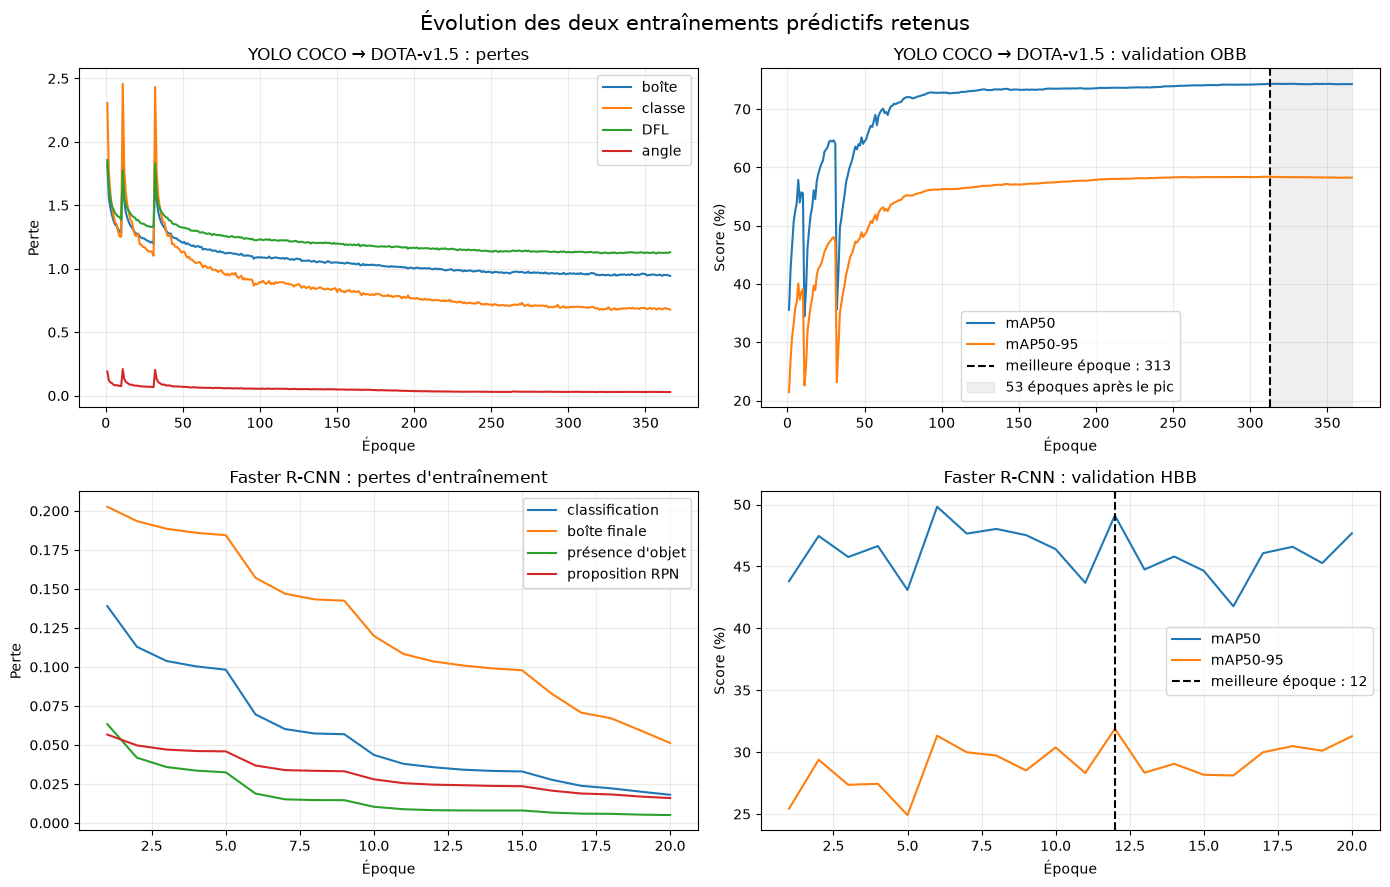

In [50]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(2, 2, figsize=(14, 9))

# Les quatre pertes de YOLO décrivent des erreurs de nature différente.
for column_name, label in [
    ("train/box_loss", "boîte"),
    ("train/cls_loss", "classe"),
    ("train/dfl_loss", "DFL"),
    ("train/angle_loss", "angle"),
]:
    axes[0, 0].plot(
        yolo_history_df["epoch"], yolo_history_df[column_name], label=label
    )
axes[0, 0].set_title("YOLO COCO → DOTA-v1.5 : pertes")
axes[0, 0].set_ylabel("Perte")
axes[0, 0].legend()

# La multiplication par 100 affiche les métriques sous forme de pourcentages.
axes[0, 1].plot(
    yolo_history_df["epoch"],
    100 * yolo_history_df["metrics/mAP50(B)"],
    label="mAP50",
)
axes[0, 1].plot(
    yolo_history_df["epoch"],
    100 * yolo_history_df["metrics/mAP50-95(B)"],
    label="mAP50-95",
)
axes[0, 1].axvline(
    yolo_best_epoch_curve, color="black", linestyle="--",
    label=f"meilleure époque : {yolo_best_epoch_curve}",
)
# La zone grise montre les époques poursuivies sans nouveau record.
axes[0, 1].axvspan(
    yolo_best_epoch_curve, yolo_history_df["epoch"].max(),
    color="gray", alpha=0.12,
    label=f"{yolo_post_peak_epochs} époques après le pic",
)
axes[0, 1].set_title("YOLO COCO → DOTA-v1.5 : validation OBB")
axes[0, 1].set_ylabel("Score (%)")
axes[0, 1].legend()

for column_name, label in [
    ("loss_classifier", "classification"),
    ("loss_box_reg", "boîte finale"),
    ("loss_objectness", "présence d'objet"),
    ("loss_rpn_box_reg", "proposition RPN"),
]:
    axes[1, 0].plot(
        faster_history_df["epoch"], faster_history_df[column_name], label=label
    )
axes[1, 0].set_title("Faster R-CNN : pertes d'entraînement")
axes[1, 0].set_ylabel("Perte")
axes[1, 0].legend()

axes[1, 1].plot(
    faster_history_df["epoch"], 100 * faster_history_df["mAP50"],
    label="mAP50",
)
axes[1, 1].plot(
    faster_history_df["epoch"], 100 * faster_history_df["mAP50_95"],
    label="mAP50-95",
)
axes[1, 1].axvline(
    faster_best_epoch_curve, color="black", linestyle="--",
    label=f"meilleure époque : {faster_best_epoch_curve}",
)
axes[1, 1].set_title("Faster R-CNN : validation HBB")
axes[1, 1].set_ylabel("Score (%)")
axes[1, 1].legend()

for axis in axes.flat:
    axis.set_xlabel("Époque")
    axis.grid(alpha=0.25)

figure.suptitle("Évolution des deux entraînements prédictifs retenus", fontsize=15)
figure.tight_layout()
plt.show()

#### Lecture des courbes

- Le run YOLO parti de COCO commence à 21,45 % de mAP50-95, puis atteint son maximum de 58,41 % à l'époque 313. Les 53 validations suivantes restent entre 58,22 % et 58,37 %, et l'époque 366 termine à 58,25 %. Cette stabilité confirme un plateau; le checkpoint de l'époque 313 est donc conservé.
- Faster R-CNN atteint sa meilleure mAP50-95, soit 31,88 %, à l'époque 12. Ses pertes continuent ensuite à diminuer sans amélioration durable sur la validation; l'arrêt anticipé termine le run à l'époque 20 et conserve le checkpoint de l'époque 12.

Une perte d'entraînement plus faible ne garantit donc pas une meilleure généralisation. Les scores des deux modèles restent propres à leur géométrie native et sont interprétés séparément.

#### Comparaison complémentaire des initialisations YOLO

Nous comparons maintenant le run final parti directement de COCO à celui qui avait d'abord appris sur DOTA-v1.0. Les deux utilisent la même validation DOTA-v1.5. Cette comparaison permet surtout de voir si le transfert depuis DOTA-v1.0 accélère l'arrivée à une bonne performance.

Les principaux réglages sont communs, mais la planification du taux d'apprentissage et la durée maximale diffèrent. Cette expérience décrit donc les deux runs réellement effectués; elle n'isole pas parfaitement l'effet de l'initialisation.

In [51]:
from pathlib import Path

import pandas as pd

q3_project_dir = Path.cwd().resolve()
transfer_results_path = (
    q3_project_dir / "outputs" / "yolo_runs"
    / "yolo11s_obb_v15_from_v10" / "results.csv"
)
clean_coco_results_path = (
    q3_project_dir / "outputs" / "yolo_runs"
    / "yolo11s_obb_v15_clean_coco_55h" / "results.csv"
)

for result_path in (transfer_results_path, clean_coco_results_path):
    if not result_path.is_file():
        raise FileNotFoundError(f"Résultat introuvable : {result_path}")

transfer_yolo_history_df = pd.read_csv(transfer_results_path).sort_values("epoch")
clean_yolo_history_df = pd.read_csv(clean_coco_results_path).sort_values("epoch")

metric_name = "metrics/mAP50-95(B)"

# In : historique et seuil 0,58; Out : première époque atteignant 58 %.
def first_epoch_reaching(history_df, threshold):
    qualifying_epochs = history_df.loc[
        history_df[metric_name] >= threshold, "epoch"
    ]
    return int(qualifying_epochs.iloc[0]) if not qualifying_epochs.empty else None


def summarize_yolo_run(initialization, history_df):
    # idxmax repère ici l'époque possédant la meilleure mAP50-95.
    best_row = history_df.loc[history_df[metric_name].idxmax()]
    return {
        "initialisation": initialization,
        "époques disponibles": int(history_df["epoch"].max()),
        "meilleure époque": int(best_row["epoch"]),
        "meilleure mAP50-95 (%)": round(100 * best_row[metric_name], 2),
        "première époque à 55 %": first_epoch_reaching(history_df, 0.55),
        "première époque à 58 %": first_epoch_reaching(history_df, 0.58),
    }


initialization_comparison_df = pd.DataFrame([
    summarize_yolo_run("DOTA-v1.0 → DOTA-v1.5", transfer_yolo_history_df),
    summarize_yolo_run("COCO → DOTA-v1.5", clean_yolo_history_df),
])
display(initialization_comparison_df)

transfer_best_row = transfer_yolo_history_df.loc[
    transfer_yolo_history_df[metric_name].idxmax()
]
clean_best_row = clean_yolo_history_df.loc[
    clean_yolo_history_df[metric_name].idxmax()
]
score_gap_points = 100 * (
    clean_best_row[metric_name] - transfer_best_row[metric_name]
)
epoch_ratio = clean_best_row["epoch"] / transfer_best_row["epoch"]
print(f"Écart des meilleurs scores : {score_gap_points:.3f} point.")
print(f"Rapport des époques des pics : {epoch_ratio:.2f}.")

,initialisation,époques disponibles,meilleure époque,meilleure mAP50-95 (%),première époque à 55 %,première époque à 58 %
0,DOTA-v1.0 → DOTA-v1.5,103,70,58.37,3,63
1,COCO → DOTA-v1.5,366,313,58.41,76,210


Écart des meilleurs scores : 0.037 point.
Rapport des époques des pics : 4.47.


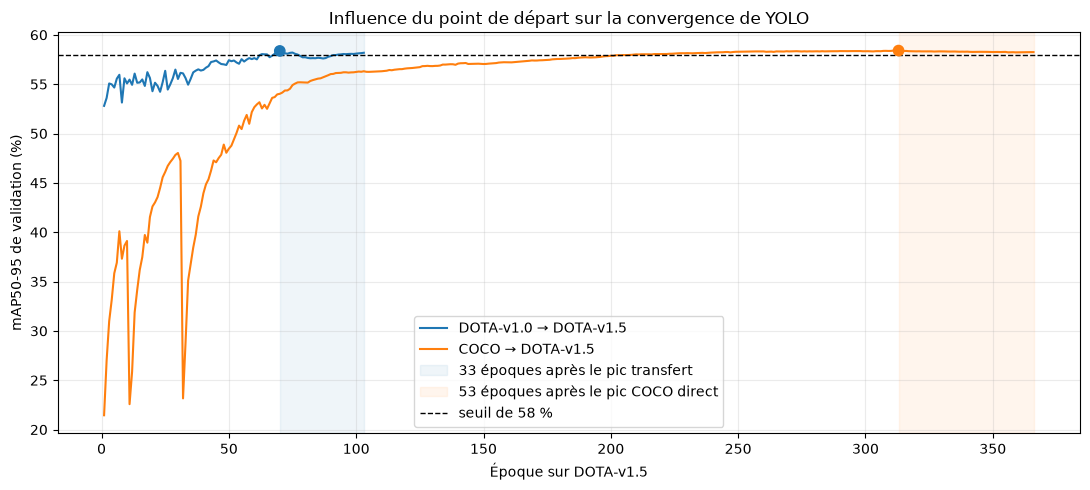

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))
plt.plot(
    transfer_yolo_history_df["epoch"],
    100 * transfer_yolo_history_df[metric_name],
    label="DOTA-v1.0 → DOTA-v1.5",
)
plt.plot(
    clean_yolo_history_df["epoch"],
    100 * clean_yolo_history_df[metric_name],
    label="COCO → DOTA-v1.5",
)
# Les points marquent les meilleurs résultats des deux runs.
plt.scatter(
    [transfer_best_row["epoch"], clean_best_row["epoch"]],
    [100 * transfer_best_row[metric_name], 100 * clean_best_row[metric_name]],
    color=["C0", "C1"], s=55, zorder=3,
)

# Les zones pâles montrent les validations poursuivies après chaque pic.
for best_row, history_df, color, label in [
    (transfer_best_row, transfer_yolo_history_df, "C0", "transfert"),
    (clean_best_row, clean_yolo_history_df, "C1", "COCO direct"),
]:
    post_peak_count = int((history_df["epoch"] > best_row["epoch"]).sum())
    plt.axvspan(
        best_row["epoch"], history_df["epoch"].max(),
        color=color, alpha=0.07,
        label=f"{post_peak_count} époques après le pic {label}",
    )

plt.axhline(58, color="black", linestyle="--", linewidth=1, label="seuil de 58 %")
plt.xlabel("Époque sur DOTA-v1.5")
plt.ylabel("mAP50-95 de validation (%)")
plt.title("Influence du point de départ sur la convergence de YOLO")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

#### Interprétation

Le transfert depuis DOTA-v1.0 atteint 55 % dès l'époque 3 et 58 % à l'époque 63. Son maximum de 58,37 % arrive à l'époque 70. Le run parti de COCO atteint ces seuils plus tard, aux époques 76 et 210, puis obtient son maximum de 58,41 % à l'époque 313.

Le score maximal du transfert est donc inférieur de seulement 0,04 point, alors que son pic est atteint environ 4,5 fois plus tôt en nombre d'époques. Cet écart de score est trop faible pour établir une supériorité réelle du départ COCO; les deux initialisations convergent pratiquement vers le même niveau. Le passage par DOTA-v1.0 apporte surtout un gain important d'efficacité d'apprentissage.

Le checkpoint COCO de l'époque 313 devient néanmoins la référence prédictive finale de cette question, puisqu'il possède le maximum numérique observé et qu'il ne dépend pas des annotations DOTA-v1.0. Cette sélection ne change pas rétroactivement le détecteur déjà figé pour l'analyse causale.

### 11 - Comparer l'efficacité à l'inférence

Ce benchmark mesure le coût nécessaire pour appliquer les deux architectures, sans comparer leurs géométries. Les 200 mêmes tuiles de validation sont préchargées en mémoire, puis traitées sur la RTX 4060 avec un batch de 1, en précision `float32` et avec un seuil de confiance de 0,25. Les 20 premières images servent à stabiliser le GPU et ne sont pas chronométrées.

La latence est le temps nécessaire pour traiter une image. La latence p95 indique que 95 % des images ont été traitées en moins de cette durée; le débit exprime le nombre d'images traitées par seconde.

Les mesures conservées ont été produites avec le checkpoint YOLO transféré de l'époque 70, avant la fin du run COCO. Elles restent une estimation pertinente du coût de l'architecture YOLO11s-OBB, car le réseau, la taille d'entrée et les réglages d'inférence sont identiques, mais elles ne constituent pas un nouveau chronométrage exact du checkpoint de l'époque 313.

Le script `benchmark_yolo_faster_inference_v15_simplifie.py` reprend les étapes essentielles dans une version plus facile à lire. La cellule suivante charge les résultats enregistrés; elle ne relance pas les modèles.

,modèle,paramètres (millions),checkpoint (Mio),latence moyenne (ms),latence p95 (ms),images/s,pic mémoire GPU (Mio)
0,YOLO11s-OBB,9.70,74.91,24.53,31.90,40.76,585.74
1,Faster R-CNN ResNet50-FPN v2,43.33,331.03,134.80,149.56,7.42,888.42


Protocole : 200 images, 20 warm-up, batch 1, NVIDIA GeForce RTX 4060.


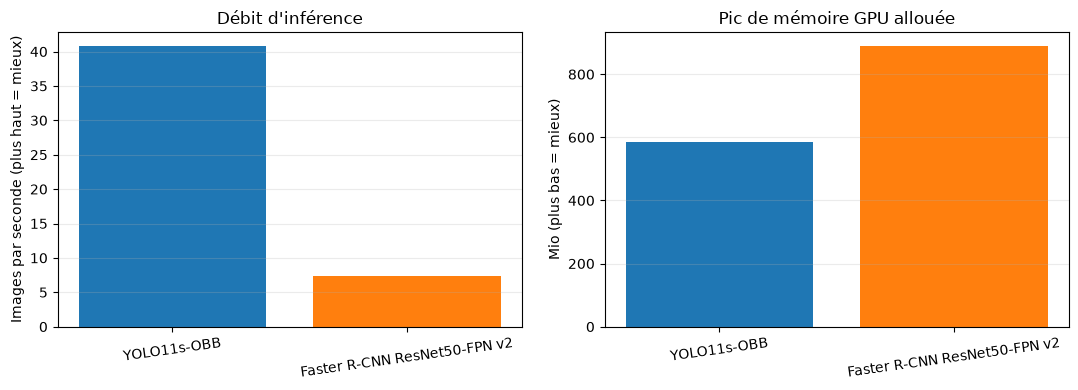

In [53]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd


benchmark_dir = (
    Path.cwd().resolve() / "outputs" / "model_comparison"
    / "q3_inference_benchmark_200"
)
metrics_path = benchmark_dir / "efficiency_metrics.csv"
protocol_path = benchmark_dir / "protocol.json"

if not metrics_path.is_file() or not protocol_path.is_file():
    raise FileNotFoundError("Les résultats du benchmark sont introuvables.")

# Le protocole conserve les conditions du test; le CSV contient les mesures.
protocol = json.loads(protocol_path.read_text(encoding="utf-8"))
efficiency_df = pd.read_csv(metrics_path)

# Ces vérifications empêchent de présenter deux tests réalisés différemment.
if set(efficiency_df["model_key"]) != {"yolo", "faster_rcnn"}:
    raise ValueError("Les deux modèles attendus ne sont pas présents.")
if protocol["images"] != 200 or protocol["batch_size"] != 1:
    raise ValueError("Le protocole chargé ne correspond pas au benchmark retenu.")

efficiency_table = efficiency_df[
    [
        "model", "parameters_millions", "checkpoint_size_mib",
        "mean_latency_ms", "p95_latency_ms", "images_per_second",
        "peak_allocated_memory_mib",
    ]
].rename(columns={
    "model": "modèle",
    "parameters_millions": "paramètres (millions)",
    "checkpoint_size_mib": "checkpoint (Mio)",
    "mean_latency_ms": "latence moyenne (ms)",
    "p95_latency_ms": "latence p95 (ms)",
    "images_per_second": "images/s",
    "peak_allocated_memory_mib": "pic mémoire GPU (Mio)",
})

numeric_columns = efficiency_table.columns.drop("modèle")
efficiency_table[numeric_columns] = efficiency_table[numeric_columns].round(2)
display(efficiency_table)
print(
    f"Protocole : {protocol['images']} images, {protocol['warmup_images']} warm-up, "
    f"batch {protocol['batch_size']}, {protocol['gpu_name']}."
)

# Les deux graphiques résument les ressources principales : vitesse et mémoire.
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ["C0", "C1"]
axes[0].bar(
    efficiency_table["modèle"], efficiency_table["images/s"], color=colors
)
axes[0].set_title("Débit d'inférence")
axes[0].set_ylabel("Images par seconde (plus haut = mieux)")

axes[1].bar(
    efficiency_table["modèle"],
    efficiency_table["pic mémoire GPU (Mio)"],
    color=colors,
)
axes[1].set_title("Pic de mémoire GPU allouée")
axes[1].set_ylabel("Mio (plus bas = mieux)")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)
    axis.tick_params(axis="x", rotation=8)

figure.tight_layout()
plt.show()

#### Interprétation

Dans ce benchmark, YOLO traite environ 40,76 images/s contre 7,42 pour Faster R-CNN : l'architecture YOLO11s-OBB est donc environ 5,5 fois plus rapide. Sa latence moyenne est de 24,53 ms, contre 134,80 ms, et sa latence p95 reste inférieure : 31,90 ms contre 149,56 ms.

YOLO est également plus léger : 9,70 millions de paramètres contre 43,33 millions, un checkpoint d'environ 75 Mio contre 331,03 Mio et environ 34 % de mémoire GPU allouée en moins au pic. Ces mesures comparent le coût des architectures; les performances de détection sont présentées séparément dans leur format natif.

### 12 - Examiner quelques prédictions

Les métriques résument des milliers de tuiles, mais elles ne montrent pas la forme des erreurs. Nous examinons donc trois tuiles de validation choisies avant de regarder les prédictions : un aéroport, un port et des installations sportives. Chacune contient 15 objets annotés, ce qui permet de conserver une figure lisible tout en variant les classes.

YOLO utilise ici le checkpoint final parti de COCO, retenu à l'époque 313. Pour chaque tuile, la figure présente l'image originale, les annotations OBB, ses prédictions OBB et les prédictions HBB de Faster R-CNN. Chaque modèle conserve ainsi sa géométrie native; aucune conversion n'est effectuée. Le seuil de confiance de 0,25 sert uniquement à rendre la figure lisible.

In [54]:
import gc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Polygon as PlotPolygon
from matplotlib.patches import Rectangle
from PIL import Image
import torch
from torchvision.transforms.functional import pil_to_tensor
from ultralytics import YOLO

from train_faster_rcnn_v15 import build_model


q3_project_dir = Path.cwd().resolve()
q3_dataset_dir = q3_project_dir / "outputs" / "dota_v15_tiles_1024"
q3_metadata_dir = q3_dataset_dir / "metadata"
q3_yolo_checkpoint = (
    q3_project_dir / "outputs" / "yolo_runs"
    / "yolo11s_obb_v15_clean_coco_55h"
    / "recovery" / "best_latest.pt"
)
q3_faster_checkpoint = (
    q3_project_dir / "outputs" / "faster_rcnn_runs"
    / "faster_rcnn_v15_final_72h" / "checkpoints" / "best.pt"
)

# Les trois cas sont fixes : ils ne dépendent donc pas des prédictions obtenues.
qualitative_tiles = {
    "Aéroport (15 objets)": (
        "validation__P1854__s1024__x6592_7616__y824_1848"
    ),
    "Port (15 objets)": (
        "validation__P2701__s1024__x2926_3950__y824_1848"
    ),
    "Installations sportives (15 objets)": (
        "validation__P2768__s1024__x0_1024__y1333_2357"
    ),
}

tile_manifest = pd.read_csv(q3_metadata_dir / "tile_manifest.csv")
object_annotations = pd.read_csv(
    q3_metadata_dir / "object_annotations.csv"
)
class_mapping = pd.read_csv(q3_metadata_dir / "class_mapping.csv")

selected_tile_ids = list(qualitative_tiles.values())
selected_tiles = tile_manifest.loc[
    tile_manifest["tile_id"].isin(selected_tile_ids)
].set_index("tile_id")
selected_annotations = object_annotations.loc[
    object_annotations["tile_id"].isin(selected_tile_ids)
]

missing_tiles = set(selected_tile_ids) - set(selected_tiles.index)
if missing_tiles:
    raise FileNotFoundError(f"Tuiles de validation manquantes : {missing_tiles}")

# Les images restent en RAM et seront réutilisées par les deux modèles.
qualitative_images = {}
for tile_id in selected_tile_ids:
    image_path = q3_dataset_dir / selected_tiles.loc[tile_id, "tile_image_path"]
    with Image.open(image_path) as image:
        qualitative_images[tile_id] = image.convert("RGB").copy()

yolo_class_names = class_mapping.set_index("yolo_class_id")[
    "class_name"
].to_dict()
faster_class_names = class_mapping.set_index("faster_rcnn_class_id")[
    "class_name"
].to_dict()

selection_summary = pd.DataFrame([
    {
        "cas": case_name,
        "image source": selected_tiles.loc[tile_id, "source_image_id"],
        "annotations": int(
            (selected_annotations["tile_id"] == tile_id).sum()
        ),
    }
    for case_name, tile_id in qualitative_tiles.items()
])
display(selection_summary)

,cas,image source,annotations
0,Aéroport (15 objets),P1854,15
1,Port (15 objets),P2701,15
2,Installations sportives (15 objets),P2768,15


In [55]:
display_confidence = 0.25
maximum_display_detections = 300
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

if device.type != "cuda":
    raise RuntimeError("Cette cellule d'inférence nécessite le GPU CUDA.")

# Première étape : YOLO renvoie les quatre sommets de chaque OBB.
yolo_model = YOLO(str(q3_yolo_checkpoint), task="obb")
yolo_predictions = {}
for tile_id, image in qualitative_images.items():
    result = yolo_model.predict(
        image,
        imgsz=1024,
        conf=display_confidence,
        iou=0.70,
        max_det=maximum_display_detections,
        device=0,
        verbose=False,
    )[0]

    if result.obb is None:
        vertices = np.empty((0, 4, 2))
        class_ids = np.empty(0, dtype=int)
        scores = np.empty(0)
    else:
        vertices = result.obb.xyxyxyxy.cpu().numpy()
        class_ids = result.obb.cls.cpu().numpy().astype(int)
        scores = result.obb.conf.cpu().numpy()

    yolo_predictions[tile_id] = {
        "vertices": vertices,
        "class_ids": class_ids,
        "scores": scores,
    }

del yolo_model, result
gc.collect()
torch.cuda.empty_cache()

# Deuxième étape : Faster R-CNN renvoie des HBB [x_min, y_min, x_max, y_max].
faster_checkpoint = torch.load(
    q3_faster_checkpoint, map_location="cpu", weights_only=False
)
faster_model = build_model(load_coco_weights=False)
faster_model.load_state_dict(faster_checkpoint["model_state"], strict=True)
faster_model.roi_heads.score_thresh = display_confidence
faster_model.roi_heads.detections_per_img = maximum_display_detections
faster_model.to(device).eval()
del faster_checkpoint

faster_predictions = {}
with torch.inference_mode():
    for tile_id, image in qualitative_images.items():
        # In : image PIL; Out : tenseur [3, 1024, 1024] compris entre 0 et 1.
        image_tensor = pil_to_tensor(image).float().div(255).to(device)
        prediction = faster_model([image_tensor])[0]
        faster_predictions[tile_id] = {
            "boxes": prediction["boxes"].cpu().numpy(),
            "class_ids": prediction["labels"].cpu().numpy().astype(int),
            "scores": prediction["scores"].cpu().numpy(),
        }

del faster_model, prediction, image_tensor
gc.collect()
torch.cuda.empty_cache()
print("Prédictions terminées sur les trois tuiles.")

Prédictions terminées sur les trois tuiles.


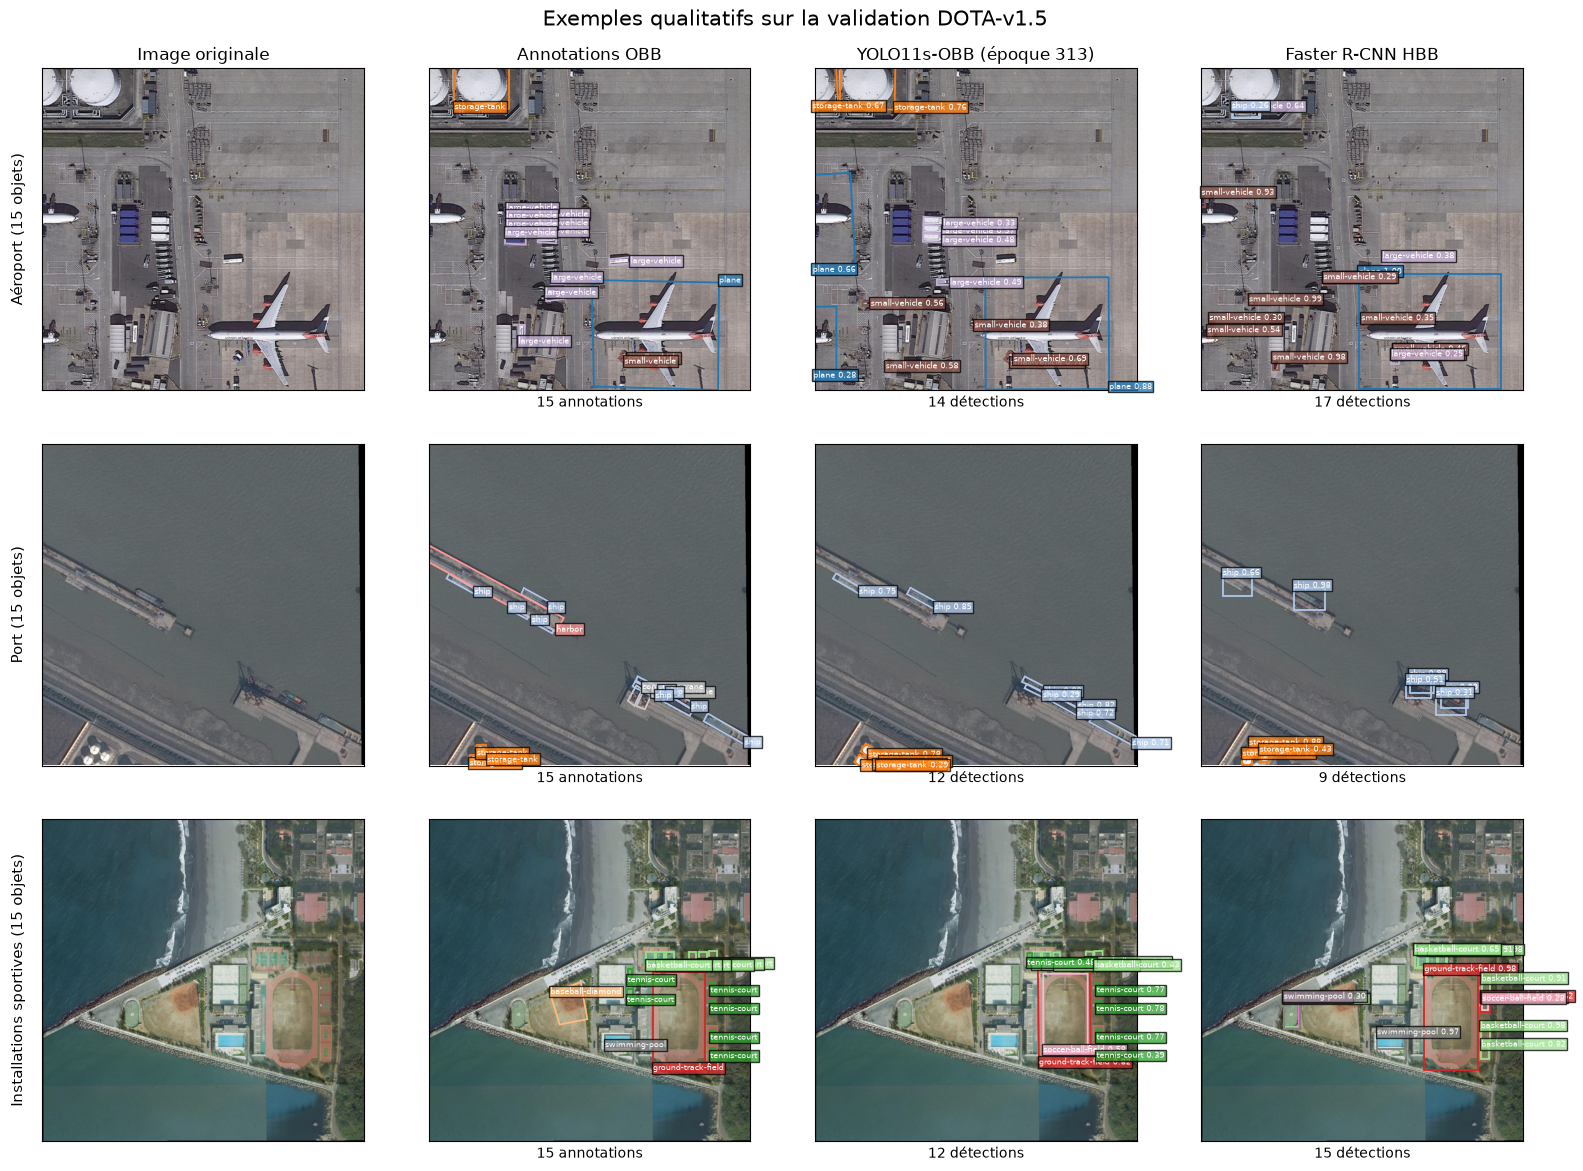

In [56]:
class_names = class_mapping.sort_values("yolo_class_id")[
    "class_name"
].tolist()
color_map = plt.get_cmap("tab20")
class_colors = {
    class_name: color_map(index % 20)
    for index, class_name in enumerate(class_names)
}


def add_label(axis, x, y, text, color, show_text):
    """Ajoute un nom de classe seulement si la scène reste lisible."""

    if show_text:
        axis.text(
            x, y, text, fontsize=6, color="white",
            bbox={"facecolor": color, "alpha": 0.75, "pad": 1},
        )


def draw_ground_truth(axis, annotations, show_text):
    """Dessine les quatre sommets OBB normalisés des annotations."""

    vertex_columns = [
        "obb_x1", "obb_y1", "obb_x2", "obb_y2",
        "obb_x3", "obb_y3", "obb_x4", "obb_y4",
    ]
    for _, annotation in annotations.iterrows():
        # Les coordonnées du CSV sont normalisées; ×1024 redonne des pixels.
        vertices = (
            annotation[vertex_columns].to_numpy(float).reshape(4, 2) * 1024
        )
        class_name = annotation["class_name"]
        color = class_colors[class_name]
        axis.add_patch(
            PlotPolygon(vertices, closed=True, fill=False, color=color, linewidth=1.3)
        )
        add_label(
            axis, vertices[0, 0], vertices[0, 1], class_name, color, show_text
        )


def draw_yolo_predictions(axis, predictions, show_text):
    """Dessine directement les OBB produites par YOLO."""

    for vertices, class_id, score in zip(
        predictions["vertices"],
        predictions["class_ids"],
        predictions["scores"],
    ):
        class_name = yolo_class_names[class_id]
        color = class_colors[class_name]
        axis.add_patch(
            PlotPolygon(vertices, closed=True, fill=False, color=color, linewidth=1.3)
        )
        add_label(
            axis, vertices[0, 0], vertices[0, 1],
            f"{class_name} {score:.2f}", color, show_text,
        )


def draw_faster_predictions(axis, predictions, show_text):
    """Dessine les HBB [x_min, y_min, x_max, y_max] de Faster R-CNN."""

    for box, class_id, score in zip(
        predictions["boxes"],
        predictions["class_ids"],
        predictions["scores"],
    ):
        x_min, y_min, x_max, y_max = box
        class_name = faster_class_names[class_id]
        color = class_colors[class_name]
        axis.add_patch(
            Rectangle(
                (x_min, y_min), x_max - x_min, y_max - y_min,
                fill=False, color=color, linewidth=1.3,
            )
        )
        add_label(
            axis, x_min, y_min,
            f"{class_name} {score:.2f}", color, show_text,
        )


figure, axes = plt.subplots(3, 4, figsize=(16, 12))
column_titles = [
    "Image originale", "Annotations OBB",
    "YOLO11s-OBB (époque 313)", "Faster R-CNN HBB",
]

for row_index, (case_name, tile_id) in enumerate(qualitative_tiles.items()):
    image = qualitative_images[tile_id]
    ground_truth = selected_annotations.loc[
        selected_annotations["tile_id"] == tile_id
    ]
    yolo_result = yolo_predictions[tile_id]
    faster_result = faster_predictions[tile_id]

    # Au-delà de 25 objets, les textes sont masqués mais toutes les boîtes restent.
    largest_count = max(len(ground_truth), len(yolo_result["scores"]),
                        len(faster_result["scores"]))
    show_text = largest_count <= 25

    for axis in axes[row_index]:
        axis.imshow(image)
        axis.set_xlim(0, image.width)
        axis.set_ylim(image.height, 0)
        axis.set_xticks([])
        axis.set_yticks([])

    if row_index == 0:
        for axis, title in zip(axes[row_index], column_titles):
            axis.set_title(title, fontsize=12)

    draw_ground_truth(axes[row_index, 1], ground_truth, show_text)
    draw_yolo_predictions(axes[row_index, 2], yolo_result, show_text)
    draw_faster_predictions(axes[row_index, 3], faster_result, show_text)

    axes[row_index, 0].set_ylabel(
        case_name, fontsize=11, rotation=90, labelpad=12
    )
    axes[row_index, 1].set_xlabel(f"{len(ground_truth)} annotations")
    axes[row_index, 2].set_xlabel(f"{len(yolo_result['scores'])} détections")
    axes[row_index, 3].set_xlabel(f"{len(faster_result['scores'])} détections")

figure.suptitle(
    "Exemples qualitatifs sur la validation DOTA-v1.5",
    fontsize=15,
)
figure.tight_layout()
plt.show()

#### Interprétation

Pour 15 annotations, YOLO produit 14 détections sur l'aéroport, 12 sur le port et 12 sur les installations sportives. Faster R-CNN en produit respectivement 17, 9 et 15. Un total proche de 15 ne garantit pas un résultat parfait : une omission peut être compensée par un doublon, un faux positif ou une erreur de classe.

Dans l'aéroport, YOLO retrouve le grand avion, mais confond encore plusieurs véhicules. Dans le port, il produit 7 détections `ship` pour 9 annotations `ship`, ne prédit ni `harbor` ni `container-crane` et produit davantage de `storage-tank` qu'il n'en existe dans les annotations. Dans la scène sportive, il reconnaît la majorité des courts de tennis et de basketball ainsi que la piste, mais manque notamment le terrain de baseball et la piscine.

Les OBB de YOLO suivent mieux la direction des objets inclinés, tandis que les HBB de Faster R-CNN englobent davantage d'arrière-plan. Ces trois exemples expliquent visuellement les types d'erreurs; la conclusion générale doit toutefois reposer sur l'ensemble de validation.

### 13 - Synthèse de la question 3

| Élément | YOLO11s-OBB | Faster R-CNN |
|---|---:|---:|
| géométrie de sortie | OBB | HBB |
| meilleure époque | 313 | 12 |
| mAP50 native | 74,31 % | 49,12 % |
| mAP50-95 native | 58,41 % | 31,88 % |
| débit mesuré sur RTX 4060 | 40,76 images/s | 7,42 images/s |
| paramètres | 9,70 millions | 43,33 millions |
| taille du checkpoint | 74,95 Mio | 331,03 Mio |
| pic de mémoire allouée | 585,74 Mio | 888,42 Mio |

Les mAP sont indiquées dans le format natif de chaque modèle : recouvrement orienté pour YOLO et horizontal pour Faster R-CNN. Elles décrivent donc leurs résultats respectifs, mais leur différence ne constitue pas une mesure commune exacte de l'avantage de YOLO. La valeur de 58,41 % est le meilleur score observé pendant l'entraînement; une revalidation finale du même checkpoint a donné 58,36 %, sans modifier l'interprétation.

Les deux initialisations YOLO atteignent presque le même plafond. Le transfert DOTA-v1.0 → DOTA-v1.5 obtient 58,37 % à l'époque 70, contre 58,41 % à l'époque 313 pour le départ COCO direct. Son résultat est inférieur de seulement 0,04 point, mais il atteint son pic environ 4,5 fois plus tôt en nombre d'époques. Le transfert apporte donc surtout un gain de convergence, sans différence finale substantielle.

Les exemples visuels utilisent le checkpoint COCO de l'époque 313. Ils confirment l'intérêt des OBB pour suivre les objets inclinés, tout en montrant des omissions, des classifications incorrectes et des détections supplémentaires. Les résultats de vitesse proviennent du benchmark antérieur effectué avec la même architecture YOLO11s-OBB et le checkpoint transféré de l'époque 70.

Le checkpoint COCO de l'époque 313 devient la référence prédictive finale de la question 3, car il possède le maximum numérique de mAP50-95 et ne dépend pas du passage par DOTA-v1.0. L'écart de 0,04 point ne prouve toutefois pas qu'il soit réellement supérieur. L'analyse causale conserve séparément le checkpoint transféré de l'époque 70, déjà figé lors de la construction de son résultat `Y`.

## Question 4 - Formulation de la question causale

Les questions précédentes évaluaient la capacité des modèles à détecter des objets. Nous changeons maintenant de point de vue : au lieu de demander seulement quels objets sont manqués, nous cherchons à savoir si une condition de l'image contribue à ces erreurs.

Une analyse causale exige de préciser la population, le traitement, le résultat, les variables d'ajustement et les hypothèses qui rendent la comparaison interprétable. Cette question fixe ces éléments avant toute estimation de l'effet.

### 1 - Choisir et définir le traitement

Le traitement est la condition dont nous voulons estimer l'effet. Ces deux lettres désignent donc le même indicateur binaire.

Le traitement doit être défini avant la sortie de YOLO. Nous avons considéré la petite taille, la troncature, l'annotation `difficult` et le GSD. La troncature était trop rare, la petite taille dépendait fortement de la classe et `difficult` regroupait plusieurs problèmes. Le GSD formait les deux groupes les plus interprétables et les mieux représentés.

Nous définissons donc :

- `T = 1` si le GSD est supérieur à `0,270646739654` : chaque pixel couvre davantage de terrain et la résolution spatiale est plus faible;
- `T = 0` si le GSD est inférieur ou égal à ce seuil : la résolution spatiale est meilleure.

La valeur retenue est la médiane des GSD connus. Elle donne deux groupes de tailles proches, mais ne représente pas une frontière physique universelle. Elle reste fixée avant l'estimation.

La cellule suivante repart des métadonnées DOTA-v1.5 déjà créées. Elle ramène les copies de tuiles à un objet source unique, puis vérifie dans quelles sources d'images les deux niveaux de traitement sont réellement observés.

In [57]:
from pathlib import Path

import pandas as pd
from IPython.display import display


project_dir = Path.cwd().resolve()
annotations_path = (
    project_dir / "outputs" / "dota_v15_tiles_1024"
    / "metadata" / "object_annotations.csv"
)
if not annotations_path.is_file():
    raise FileNotFoundError(f"Métadonnées introuvables : {annotations_path}")

# usecols charge uniquement les colonnes nécessaires à cette vérification.
columns_to_load = [
    "source_object_id", "source_image_id", "split",
    "class_name", "image_source", "gsd",
]
tile_objects_df = pd.read_csv(annotations_path, usecols=columns_to_load)
validation_tiles_df = tile_objects_df.loc[
    tile_objects_df["split"].eq("validation")
].copy()

# Un objet peut être copié dans plusieurs tuiles qui se chevauchent.
# groupby le ramène à une ligne; first conserve ses valeurs répétées.
source_objects_df = (
    validation_tiles_df
    .groupby("source_object_id", as_index=False)
    .agg(
        source_image_id=("source_image_id", "first"),
        class_name=("class_name", "first"),
        image_source=("image_source", "first"),
        gsd=("gsd", "first"),
    )
)

# La médiane est calculée avant les restrictions afin de garder le seuil fixé.
gsd_threshold = source_objects_df["gsd"].median()
known_gsd_df = source_objects_df.dropna(subset=["gsd"]).copy()
known_gsd_df["treatment"] = (
    known_gsd_df["gsd"] > gsd_threshold
).astype(int)

# crosstab compte les objets T=0 et T=1 dans chaque classe.
# reindex garantit la présence des deux colonnes, même si un groupe vaut zéro.
class_counts = pd.crosstab(
    known_gsd_df["class_name"], known_gsd_df["treatment"]
).reindex(columns=[0, 1], fill_value=0)
# any(axis=1) repère une classe absente d'au moins un des deux groupes.
classes_without_both_groups = class_counts.index[
    class_counts.eq(0).any(axis=1)
].tolist()

comparable_classes_df = known_gsd_df.loc[
    ~known_gsd_df["class_name"].isin(classes_without_both_groups)
].copy()
counts_by_source = pd.crosstab(
    comparable_classes_df["image_source"],
    comparable_classes_df["treatment"],
).reindex(columns=[0, 1], fill_value=0)
counts_by_source.columns = ["T=0 : meilleure résolution", "T=1 : faible résolution"]

# GF et JL n'ont pas de contrôle T=0; l'analyse principale garde GoogleEarth.
causal_population_df = comparable_classes_df.loc[
    comparable_classes_df["image_source"].eq("GoogleEarth")
].copy()

print(f"Objets sources après le découpage : {len(source_objects_df):,}")
print(f"Objets sans GSD : {source_objects_df['gsd'].isna().sum():,}")
print(f"Seuil médian du GSD : {gsd_threshold:.12f}")
print(f"Classe sans les deux groupes : {classes_without_both_groups}")
display(counts_by_source)
print(
    f"Population retenue : {len(causal_population_df):,} objets dans "
    f"{causal_population_df['source_image_id'].nunique():,} images GoogleEarth."
)

Objets sources après le découpage : 69,545
Objets sans GSD : 655
Seuil médian du GSD : 0.270646739654
Classe sans les deux groupes : ['container-crane']


,T=0 : meilleure résolution,T=1 : faible résolution
image_source,,
GF,0,1161
GoogleEarth,35325,31643
JL,0,747


Population retenue : 66,968 objets dans 375 images GoogleEarth.


#### Interprétation et population retenue

Les sources `GF` et `JL` ne contiennent ici que des objets avec `T=1`. À l'intérieur de ces sources, il est donc impossible d'observer un groupe comparable de meilleure résolution. Les conserver ferait confondre l'effet du GSD avec les différences entre sources d'acquisition.

L'analyse principale est ainsi limitée à `GoogleEarth`, où les deux traitements sont présents. La classe `container-crane` est également retirée, car elle ne possède pas les deux groupes. La population de départ contient 66 968 objets provenant de 375 images : 35 325 avec `T=0` et 31 643 avec `T=1`.

L'unité d'analyse est un objet source annoté, et non chacune de ses copies dans les tuiles. Tous les objets d'une même image partagent le même GSD; cette structure devra être respectée dans la validation croisée et les intervalles de confiance.

La question causale est la suivante :

> Parmi les objets GoogleEarth évaluables de validation DOTA-v1.5 qui possèdent des profils comparables dans les deux groupes, quel est l'effet moyen d'une faible résolution spatiale, par rapport à une meilleure résolution, sur la probabilité d'être correctement détecté par le checkpoint YOLO retenu à l'époque 70 ?

Ce checkpoint transféré est conservé comme détecteur causal figé. Le remplacer par celui de l'époque 313 modifierait les valeurs de `Y` et définirait donc une nouvelle analyse plutôt qu'une simple mise à jour du modèle.

Il reste maintenant à définir précisément le résultat « correctement détecté », les variables d'ajustement et les hypothèses nécessaires à cette interprétation.

### 3 - Définir le résultat `Y`

Le résultat est défini pour chaque objet source annoté :

- `Y = 1` si YOLO retrouve correctement l'objet;
- `Y = 0` si aucune prédiction compatible ne lui est attribuée.

Pour construire ce résultat de manière identique dans toutes les images, nous suivons le protocole suivant :

1. YOLO prédit les tuiles et nous conservons les sorties dont la confiance atteint `0,25`.
2. Dans chaque tuile, une première NMS OBB par classe au seuil `0,70` retire les boîtes presque identiques. Les prédictions centrées dans le remplissage de la tuile sont aussi rejetées.
3. Les boîtes restantes sont replacées dans les coordonnées de l'image source.
4. Une seconde NMS OBB par classe au seuil `0,70` retire les doublons provenant des tuiles qui se chevauchent.
5. Une prédiction peut être associée à une annotation seulement si leur classe est identique et si leur ProbIoU atteint `0,50`.
6. Les paires sont examinées de la meilleure à la moins bonne ProbIoU. Une prédiction et une annotation ne peuvent chacune être utilisées qu'une seule fois.

Ainsi, une détection correcte peut s'écrire simplement :

$$
Y_i =
\begin{cases}
1, & \text{si la classe est correcte, la confiance } \geq 0{,}25
     \text{ et la ProbIoU } \geq 0{,}50, \\
0, & \text{sinon.}
\end{cases}
$$

L'appariement un-à-un empêche qu'une même prédiction valide plusieurs objets. Les prédictions qui ne correspondent à aucune annotation sont des faux positifs; elles sont comptées séparément, mais ne possèdent pas de ligne dans ce résultat objet par objet. `Y` étudie donc surtout la probabilité de retrouver un objet réel, ce qui est lié au rappel plutôt qu'à la précision globale du modèle.

### 4 - Choisir les variables d'ajustement `X`

Une variable de confusion peut influencer à la fois le traitement `T` et le résultat `Y`. Sans ajustement, une différence entre les groupes pourrait lui être attribuable plutôt qu'au GSD. Un médiateur se situe au contraire sur le chemin par lequel le GSD agit sur la détection; le contrôler retirerait une partie de l'effet que nous cherchons à mesurer.

Les variables `X` retenues décrivent les objets et les images avant la détection :

| Groupe | Variables utilisées | Rôle |
|---|---|---|
| composition de l'image | nombre d'objets et proportions des classes | décrire le type et l'encombrement de la scène |
| densité | densité locale et résumés de densité de l'image | représenter la difficulté liée aux objets voisins |
| géométrie de l'objet | classe, orientation par sinus/cosinus et position normalisée | tenir compte des profils plus ou moins faciles à détecter |
| géométrie de l'image | largeur et hauteur de l'image source | décrire les différences de cadrage et d'échelle des scènes |

Comme `T` est commun à tous les objets d'une image, le score de propension sera appris avec une ligne par image. Les caractéristiques des objets seront alors résumées par leur moyenne, leur dispersion ou leur proportion par classe, puis le score obtenu sera reporté sur chaque objet de l'image.

La source d'acquisition n'est plus une variable de `X`, car la population a déjà été limitée à `GoogleEarth` : elle est donc constante.

Certaines colonnes sont volontairement exclues :

- le GSD exact, car il définit directement `T`;
- la taille et l'aire apparentes en pixels, car elles peuvent transmettre l'effet du GSD vers la détection;
- `difficult`, la fraction visible et la troncature, qui mélangent la qualité de l'objet et les conséquences du découpage;
- la confiance, la ProbIoU et `Y`, car elles sont produites après la prédiction;
- `source_image_id`, qui pourrait permettre de mémoriser chaque image au lieu d'apprendre une relation généralisable.

L'identifiant de l'image reste néanmoins indispensable pour garder tous ses objets dans le même pli et pour regrouper les intervalles de confiance. Il sert donc à organiser l'analyse, mais n'est jamais fourni au modèle comme variable explicative.

### 5 - Définir l'effet recherché

Pour un objet `i`, nous pouvons imaginer deux résultats potentiels :

- `Y_i(1)` : serait-il détecté si son image avait une faible résolution ?
- `Y_i(0)` : serait-il détecté si son image avait une meilleure résolution ?

Nous n'observons qu'une seule de ces situations, puisque chaque image possède un seul traitement réel. L'ATE chercherait la moyenne de `Y_i(1) - Y_i(0)` sur toute la population. Cependant, certains profils sont presque uniquement observés dans un seul groupe de résolution; leur situation contraire serait alors difficile à estimer de manière crédible.

Nous retenons donc l'ATO (*Average Treatment effect for the Overlap population*), qui cible les objets possédant des équivalents plausibles dans les deux groupes. Si

$$
e(X) = P(T=1 \mid X)
$$

est le score de propension, le poids de chevauchement est

$$
h(X) = e(X)\,[1-e(X)].
$$

Il est maximal lorsque `e(X)` est proche de `0,5`, donc lorsque les deux traitements sont plausibles. Il devient faible près de 0 ou de 1. L'effet recherché s'écrit alors

$$
ATO = \frac{E\!\left[h(X)\{Y(1)-Y(0)\}\right]}{E[h(X)]}.
$$

Un ATO négatif signifiera que la faible résolution diminue la probabilité de détection parmi les objets comparables. Ce choix produit une conclusion plus limitée que l'ATE, mais plus défendable avec les données disponibles.

### 6 - Représenter les hypothèses avec un DAG

Un DAG est un graphe orienté qui représente nos hypothèses causales. Une flèche `A → B` signifie que nous supposons que `A` peut influencer `B`; elle ne prouve pas cette relation.

Le graphe suivant distingue quatre rôles :

- les caractéristiques de la scène et de l'image peuvent influencer à la fois `T` et `Y`; elles créent donc un chemin de confusion à contrôler;
- le profil de l'objet influence surtout sa facilité de détection;
- la taille apparente et les détails visibles transmettent une partie de l'effet du GSD;
- `Y` est le résultat final produit par YOLO.

Le chemin `T → taille et détails visibles → Y` doit rester ouvert pour mesurer l'effet total de la résolution. Ces médiateurs ne sont donc pas ajoutés à `X`.

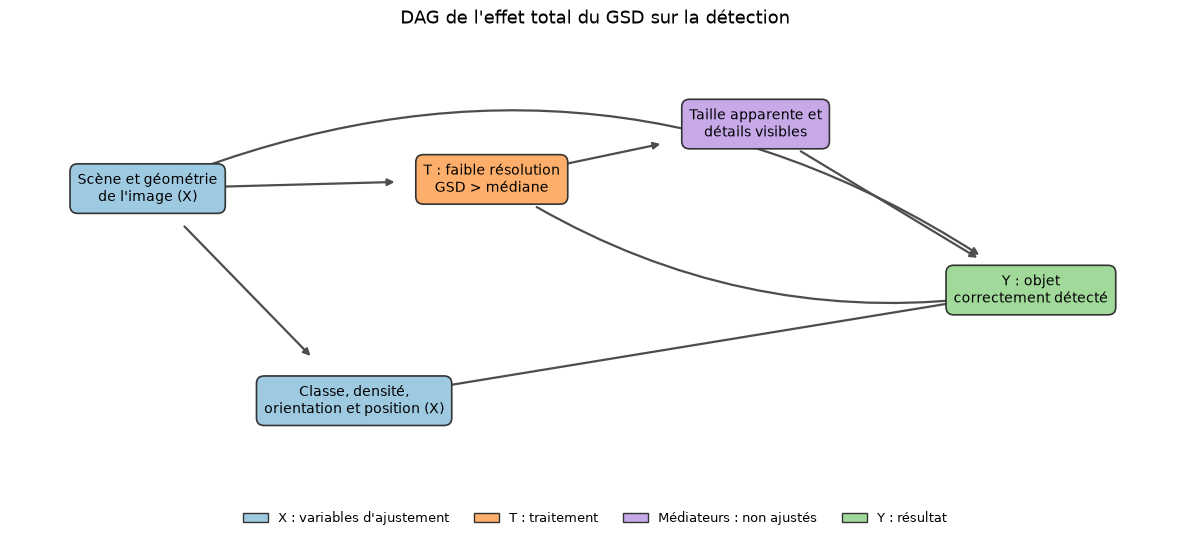

In [58]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch



node_positions = {
    "scene": (1.2, 3.1),
    "object_profile": (3.0, 0.8),
    "treatment": (4.2, 3.2),
    "mediators": (6.5, 3.8),
    "outcome": (8.9, 2.0),
}

node_labels = {
    "scene": "Scène et géométrie\nde l\'image (X)",
    "object_profile": "Classe, densité,\norientation et position (X)",
    "treatment": "T : faible résolution\nGSD > médiane",
    "mediators": "Taille apparente et\ndétails visibles",
    "outcome": "Y : objet\ncorrectement détecté",
}

node_colors = {
    "scene": "#9ECAE1",          # Variables d'ajustement.
    "object_profile": "#9ECAE1", # Variables d'ajustement ou de précision.
    "treatment": "#FDAE6B",      # Traitement T.
    "mediators": "#C7A9E8",      # Médiateurs à ne pas contrôler.
    "outcome": "#A1D99B",        # Résultat Y.
}

# Chaque paire signifie : le premier nœud peut influencer le second.
causal_arrows = [
    ("scene", "treatment"),
    ("scene", "object_profile"),
    ("scene", "outcome"),
    ("object_profile", "outcome"),
    ("treatment", "mediators"),
    ("mediators", "outcome"),
    ("treatment", "outcome"),
]

# Deux flèches sont courbées pour éviter qu'elles traversent d'autres nœuds.
arrow_curves = {
    ("scene", "outcome"): -0.28,
    ("treatment", "outcome"): 0.20,
}

# Les boîtes centrales sont plus larges : leur flèche doit s'arrêter plus tôt.
target_shrinks = {
    "treatment": 70,
    "mediators": 70,
    "object_profile": 45,
    "outcome": 45,
}

figure, axis = plt.subplots(figsize=(12, 5.5))

for source_name, target_name in causal_arrows:
    axis.annotate(
        "",
        xy=node_positions[target_name],
        xytext=node_positions[source_name],
        arrowprops={
            "arrowstyle": "-|>",
            "color": "#4D4D4D",
            "linewidth": 1.6,
            "shrinkA": 38,
            "shrinkB": target_shrinks[target_name],
            "connectionstyle": (
                f"arc3,rad={arrow_curves.get((source_name, target_name), 0.0)}"
            ),
        },
    )

for node_name, (x_position, y_position) in node_positions.items():
    axis.text(
        x_position,
        y_position,
        node_labels[node_name],
        ha="center",
        va="center",
        fontsize=10,
        bbox={
            "boxstyle": "round,pad=0.55",
            "facecolor": node_colors[node_name],
            "edgecolor": "#333333",
            "linewidth": 1.2,
        },
        zorder=3,
    )

axis.set_xlim(0, 10.2)
axis.set_ylim(0, 4.8)
axis.set_title("DAG de l'effet total du GSD sur la détection", fontsize=13)
axis.axis("off")

# La légende rappelle le rôle causal associé à chaque couleur.
# Les nœuds bleus sont les variables X utilisées dans l'ajustement;
# ils ne sont pas nécessairement tous des variables de confusion.
legend_elements = [
    Patch(
        facecolor="#9ECAE1", edgecolor="#333333",
        label="X : variables d'ajustement",
    ),
    Patch(
        facecolor="#FDAE6B", edgecolor="#333333",
        label="T : traitement",
    ),
    Patch(
        facecolor="#C7A9E8", edgecolor="#333333",
        label="Médiateurs : non ajustés",
    ),
    Patch(
        facecolor="#A1D99B", edgecolor="#333333",
        label="Y : résultat",
    ),
]
figure.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.015),
    ncol=4,
    frameon=False,
    fontsize=9,
)

# Cette marge réserve une petite zone sous le graphe pour la légende.
figure.tight_layout(rect=(0, 0.10, 1, 1))
plt.show()

### 7 - Hypothèses causales et limites

L'interprétation causale repose sur plusieurs conditions :

| Hypothèse | Signification dans notre analyse | Précaution retenue |
|---|---|---|
| échangeabilité | après l'ajustement sur `X`, aucune cause importante non mesurée ne devrait influencer à la fois `T` et `Y` | le contraste, la météo ou certains paramètres d'acquisition peuvent rester inconnus |
| positivité | pour un profil comparable, les deux valeurs de `T` doivent être possibles | l'analyse est limitée à `GoogleEarth`, la classe sans les deux groupes est retirée et l'ATO cible la zone de chevauchement |
| cohérence du traitement | `T` doit toujours conserver la même définition | `T` compare deux groupes de GSD; il ne représente pas le passage à une résolution exacte unique |
| qualité des mesures | le GSD, les annotations et l'appariement doivent être suffisamment fiables | des annotations manquantes ou une association incorrecte peuvent modifier `Y` |

Les objets d'une même image partagent le même traitement et peuvent également interagir par la densité ou la NMS. Les copies provenant des tuiles ne sont donc jamais traitées comme des unités indépendantes : elles sont ramenées à l'objet source, et tous les objets d'une image restent dans le même pli. L'incertitude sera elle aussi calculée par groupes d'images sources.

Enfin, la conclusion concernera les objets comparables des images `GoogleEarth` de validation DOTA-v1.5. Elle ne pourra pas être généralisée automatiquement à toutes les images aériennes.

### 8 - Synthèse de la question 4

| Élément | Définition retenue |
|---|---|
| population | 66 968 objets de 375 images `GoogleEarth` de validation DOTA-v1.5 |
| unité d'analyse | un objet annoté dans son image source, après regroupement de ses copies de tuiles |
| traitement `T` | `T=1` si le GSD dépasse `0,270646739654`; `T=0` sinon |
| résultat `Y` | objet retrouvé par YOLO avec la bonne classe, une confiance d'au moins `0,25` et une ProbIoU d'au moins `0,50` |
| variables `X` | composition et densité de la scène, classe, orientation, position et géométrie de l'image |
| effet recherché | ATO : effet moyen de la faible résolution parmi les objets comparables entre les deux groupes |
| détecteur étudié | checkpoint transféré DOTA-v1.0 → DOTA-v1.5 de l'époque 70, figé avant la construction de `Y` |
| regroupement | séparation des plis et calcul de l'incertitude au niveau de l'image source |

La question causale finale est donc :

> Parmi les objets `GoogleEarth` comparables, dans quelle mesure une faible résolution spatiale modifie-t-elle la probabilité qu'un objet soit correctement détecté par YOLO  ?

Un ATO négatif signifiera que la faible résolution réduit cette probabilité. La question suivante vérifiera le chevauchement entre les groupes, construira les pondérations et estimera cet effet avec son incertitude.

## Question 5 - Estimation causale et hétérogénéité des effets

La question précédente a fixé la population, le traitement `T`, le résultat `Y` et les variables d'ajustement `X`. Nous cherchons maintenant à estimer l'effet d'une faible résolution sur la probabilité de détection, puis à vérifier si cet effet varie selon les caractéristiques des objets.

Nous retenons uniquement le chemin méthodologique final :

1. construire la table causale finale et vérifier le résultat `Y`;
2. estimer le score de propension sans utiliser `Y`, puis appliquer les poids de chevauchement;
3. estimer l'ATO et son intervalle de confiance par bootstrap d'images;
4. apprendre un modèle auxiliaire du résultat pour préparer la forêt causale;
5. utiliser une forêt causale pour rechercher une éventuelle hétérogénéité;
6. rapprocher les résultats causaux des performances descriptives de YOLO.

Les premiers essais de propension au niveau objet et les pondérations instables ne sont pas repris. Ils ont seulement permis de retenir une méthode cohérente avec le fait que le GSD appartient à l'image entière, tandis que l'effet étudié concerne un objet moyen.

### 1 - Construire la table causale finale

Chaque ligne de la table représente un objet source unique :

- `T=1` indique une faible résolution spatiale et `T=0` une meilleure résolution;
- `X` décrit la classe, la densité locale, l'orientation et la position de l'objet;
- `Y=1` indique que YOLO a retrouvé l'objet avec la bonne classe et les seuils fixés à la question 4.

La première cellule reconstruit `T` et `X` depuis les métadonnées DOTA-v1.5. La seconde ajoute les prédictions déjà calculées. Elle ne relance donc pas l'inférence sur les 3 059 tuiles.

In [59]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display


q5_project_dir = Path.cwd().resolve()
q5_metadata_dir = (
    q5_project_dir / "outputs" / "dota_v15_tiles_1024" / "metadata"
)
q5_annotations_path = q5_metadata_dir / "object_annotations.csv"
q5_manifest_path = q5_metadata_dir / "tile_manifest.csv"

for q5_required_path in (q5_annotations_path, q5_manifest_path):
    if not q5_required_path.is_file():
        raise FileNotFoundError(f"Métadonnée introuvable : {q5_required_path}")

# Ces colonnes reconstruisent T et les caractéristiques de chaque objet.
q5_annotation_columns = [
    "tile_id", "split", "source_object_id", "source_image_id",
    "class_name", "image_source", "gsd", "source_orientation_deg",
    "source_center_x_normalized", "source_center_y_normalized",
]
q5_tile_objects_df = pd.read_csv(
    q5_annotations_path, usecols=q5_annotation_columns
)
q5_tile_objects_df = q5_tile_objects_df.loc[
    q5_tile_objects_df["split"].eq("validation")
].copy()

# Le nombre d'objets distincts d'une tuile mesure la densité de sa scène.
q5_objects_per_tile = (
    q5_tile_objects_df.groupby("tile_id")["source_object_id"].nunique()
)
q5_density_rows_df = q5_tile_objects_df.join(
    q5_objects_per_tile.rename("objects_in_tile"), on="tile_id"
)
q5_density_rows_df["nearby_object_count"] = (
    q5_density_rows_df["objects_in_tile"] - 1
)
q5_density_by_object_df = (
    q5_density_rows_df.groupby("source_object_id", as_index=False)
    .agg(local_density=("nearby_object_count", "mean"))
)

# groupby ramène les copies créées par le tuilage à un seul objet source.
q5_source_objects_df = (
    q5_tile_objects_df.groupby("source_object_id", as_index=False)
    .agg(
        source_image_id=("source_image_id", "first"),
        class_name=("class_name", "first"),
        image_source=("image_source", "first"),
        gsd=("gsd", "first"),
        orientation_deg=("source_orientation_deg", "first"),
        center_x=("source_center_x_normalized", "first"),
        center_y=("source_center_y_normalized", "first"),
    )
    .merge(q5_density_by_object_df, on="source_object_id", validate="one_to_one")
)

# Les dimensions sont stockées dans le manifeste des tuiles. Une même
# image fournit ses dimensions à plusieurs objets : jointure many-to-one.
q5_image_dimensions_df = (
    pd.read_csv(
        q5_manifest_path,
        usecols=["split", "source_image_id", "source_width", "source_height"],
    )
    .loc[lambda table: table["split"].eq("validation")]
    .drop(columns="split")
    .drop_duplicates()
)
if q5_image_dimensions_df["source_image_id"].duplicated().any():
    raise ValueError("Une image possède des dimensions contradictoires.")

q5_source_objects_df = q5_source_objects_df.merge(
    q5_image_dimensions_df,
    on="source_image_id",
    how="left",
    validate="many_to_one",
)
if q5_source_objects_df[["source_width", "source_height"]].isna().any().any():
    raise ValueError("Les dimensions d'une image source sont manquantes.")

# Le seuil est la médiane exacte fixée avant l'estimation causale.
Q5_GSD_THRESHOLD = 0.270646739654
if not np.isclose(
    q5_source_objects_df["gsd"].median(),
    Q5_GSD_THRESHOLD,
    rtol=0.0,
    atol=1e-12,
):
    raise ValueError("La médiane du GSD ne correspond plus au protocole.")

# GoogleEarth est la seule source possédant réellement T=0 et T=1.
q5_population_df = q5_source_objects_df.loc[
    q5_source_objects_df["gsd"].notna()
    & q5_source_objects_df["image_source"].eq("GoogleEarth")
    & ~q5_source_objects_df["class_name"].eq("container-crane")
].copy()
q5_population_df["T"] = (
    q5_population_df["gsd"] > Q5_GSD_THRESHOLD
).astype(int)

# Une OBB est identique après une rotation de 180° : nous utilisons 2 × angle.
q5_double_angle = np.deg2rad(2 * q5_population_df["orientation_deg"])
q5_population_df["orientation_sin"] = np.sin(q5_double_angle)
q5_population_df["orientation_cos"] = np.cos(q5_double_angle)
q5_population_df["log_local_density"] = np.log1p(
    q5_population_df["local_density"]
)

if len(q5_population_df) != 66_968:
    raise ValueError("La population causale attendue a changé.")
if q5_population_df["source_image_id"].nunique() != 375:
    raise ValueError("Le nombre d'images causales a changé.")
if not q5_population_df["source_object_id"].is_unique:
    raise ValueError("Un objet apparaît plusieurs fois.")

print(f"Population causale : {len(q5_population_df):,} objets")
print(f"Images sources : {q5_population_df['source_image_id'].nunique():,}")
print("Répartition de T :")
display(q5_population_df["T"].value_counts().sort_index().rename("objets"))

Population causale : 66,968 objets
Images sources : 375
Répartition de T :


T
0    35325
1    31643
Name: objets, dtype: int64

In [60]:
import json


q5_outcome_dir = (
    q5_project_dir / "outputs" / "causal_yolo_outcomes"
    / "q5_yolo_v15_epoch70_full"
)
q5_outcomes_path = q5_outcome_dir / "q5_object_outcomes.csv"
q5_protocol_path = q5_outcome_dir / "q5_protocol.json"
q5_image_summary_path = q5_outcome_dir / "q5_image_summary.csv"
for q5_required_path in (
    q5_outcomes_path, q5_protocol_path, q5_image_summary_path
):
    if not q5_required_path.is_file():
        raise FileNotFoundError(f"Résultat causal introuvable : {q5_required_path}")

# Ces valeurs identifient exactement le modèle et le protocole ayant produit Y.
q5_expected_protocol = {
    "protocol_id": "9cdd3db9addfef4ada9a33286c4056afe6c43521dc72fc7451fb062213aa0f96",
    "checkpoint_sha256": "a2f864cd3bc7101250ea91a1381b41b6a072003fc18cc61277ff05c52d1da084",
    "checkpoint_run_name": "yolo11s_obb_v15_rtx5080",
    "checkpoint_epoch_zero_based": 69,
    "causal_object_count": 66_968,
    "causal_image_count": 375,
    "causal_tile_count": 3_059,
    "minimum_confidence": 0.25,
    "matching_probiou": 0.50,
}
q5_protocol = json.loads(q5_protocol_path.read_text(encoding="utf-8"))
for q5_key, q5_expected_value in q5_expected_protocol.items():
    q5_observed_value = q5_protocol.get(q5_key)
    if isinstance(q5_expected_value, float):
        q5_is_valid = np.isclose(
            q5_observed_value, q5_expected_value, rtol=0.0, atol=1e-12
        )
    else:
        q5_is_valid = q5_observed_value == q5_expected_value
    if not q5_is_valid:
        raise ValueError(f"Protocole Y incorrect pour {q5_key}.")

# Le résumé confirme que les 375 images et les 3 059 tuiles ont été traitées.
q5_image_summary_df = pd.read_csv(
    q5_image_summary_path,
    usecols=["completed", "protocol_id", "source_image_id", "tile_count"],
)
if len(q5_image_summary_df) != 375:
    raise ValueError("Le résumé Y ne contient pas les 375 images.")
if not q5_image_summary_df["completed"].all():
    raise ValueError("L'inférence causale n'est pas terminée.")
if q5_image_summary_df["protocol_id"].nunique() != 1:
    raise ValueError("Plusieurs protocoles apparaissent dans le résumé Y.")
if q5_image_summary_df["protocol_id"].iat[0] != q5_protocol["protocol_id"]:
    raise ValueError("Le résumé Y ne correspond pas au protocole annoncé.")
if int(q5_image_summary_df["tile_count"].sum()) != 3_059:
    raise ValueError("Le nombre de tuiles prédites a changé.")

q5_outcomes_df = pd.read_csv(
    q5_outcomes_path,
    usecols=["source_object_id", "detected"],
).rename(columns={"detected": "Y"})
if not q5_outcomes_df["source_object_id"].is_unique:
    raise ValueError("Plusieurs résultats Y existent pour un même objet.")
if len(q5_outcomes_df) != 66_968:
    raise ValueError("Y doit contenir exactement 66 968 objets.")
if set(q5_outcomes_df["source_object_id"]) != set(q5_population_df["source_object_id"]):
    raise ValueError("Y ne correspond pas exactement à la population causale.")

# validate='one_to_one' impose exactement un résultat pour chaque objet.
q5_analysis_df = q5_population_df.merge(
    q5_outcomes_df, on="source_object_id", how="left", validate="one_to_one"
)
q5_analysis_df["Y"] = q5_analysis_df["Y"].astype(int)
if set(q5_analysis_df["Y"].unique()) != {0, 1}:
    raise ValueError("Y doit être binaire.")

q5_raw_detection_df = (
    q5_analysis_df.groupby("T", as_index=False)
    .agg(
        images=("source_image_id", "nunique"),
        objets=("Y", "size"),
        objets_detectes=("Y", "sum"),
        taux_detection=("Y", "mean"),
    )
)
q5_raw_detection_df["groupe"] = q5_raw_detection_df["T"].map({
    0: "meilleure résolution",
    1: "faible résolution",
})
q5_raw_detection_df["taux_detection (%)"] = (
    100 * q5_raw_detection_df.pop("taux_detection")
).round(2)

print("Checkpoint ayant produit Y : époque 70")
print(f"Objets détectés : {q5_analysis_df['Y'].sum():,}")
print(f"Objets manqués : {(1 - q5_analysis_df['Y']).sum():,}")
display(q5_raw_detection_df[
    ["T", "groupe", "images", "objets", "objets_detectes", "taux_detection (%)"]
])

Checkpoint ayant produit Y : époque 70
Objets détectés : 55,979
Objets manqués : 10,989


,T,groupe,images,objets,objets_detectes,taux_detection (%)
0,0,meilleure résolution,258,35325,32352,91.58
1,1,faible résolution,117,31643,23627,74.67


#### Première lecture

Le taux brut de détection est de 91,58 % pour `T=0` et de 74,67 % pour `T=1`, soit une différence descriptive de -16,92 points. Cette différence ne constitue pas encore un effet causal : les classes et les contextes présents dans les deux groupes ne sont pas parfaitement identiques.

Le résultat `Y` reste volontairement celui du checkpoint transféré de l'époque 70. Le remplacer par le nouveau checkpoint de l'époque 313 modifierait les détections objet par objet et nécessiterait de reprendre toute l'analyse causale.

L'étape suivante estimera donc la probabilité de recevoir `T=1` à partir de `X`, sans utiliser `Y`, afin de rendre les groupes plus comparables.

### 2 - Estimer le score de propension

Le score de propension est la probabilité qu'une image appartienne au groupe de faible résolution compte tenu de ses caractéristiques :

$$
e(X)=P(T=1\mid X).
$$

Le traitement `T` appartient à l'image entière. Nous construisons donc une ligne par image, puis nous résumons sa composition : dimensions, nombre d'objets, densité, orientation, position et proportions des classes. Le GSD exact et le résultat `Y` sont exclus, car le premier définit directement `T` et le second se produit après le traitement.

Notre effet concerne toutefois un objet moyen. Pendant l'apprentissage, une image reçoit donc une importance proportionnelle à son nombre d'objets. Cette solution respecte le niveau image de `T` sans donner artificiellement l'impression que les objets d'une même image sont indépendants.

In [61]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# Une ligne de départ représente un objet; groupby produira une ligne par image.
q5_image_rows_df = q5_analysis_df.copy()
q5_image_rows_df["log_local_density"] = np.log1p(
    q5_image_rows_df["local_density"]
)

# Les moyennes décrivent le profil typique de l'image et les écarts types
# sa diversité. ddof=0 autorise un écart type nul pour une image à un objet.
q5_image_propensity_df = (
    q5_image_rows_df.groupby("source_image_id", as_index=False)
    .agg(
        T=("T", "first"),
        source_width=("source_width", "first"),
        source_height=("source_height", "first"),
        object_count=("source_object_id", "size"),
        mean_log_density=("log_local_density", "mean"),
        std_log_density=("log_local_density", lambda values: values.std(ddof=0)),
        mean_orientation_sin=("orientation_sin", "mean"),
        mean_orientation_cos=("orientation_cos", "mean"),
        mean_center_x=("center_x", "mean"),
        std_center_x=("center_x", lambda values: values.std(ddof=0)),
        mean_center_y=("center_y", "mean"),
        std_center_y=("center_y", lambda values: values.std(ddof=0)),
    )
)
q5_image_propensity_df["log_object_count"] = np.log1p(
    q5_image_propensity_df["object_count"]
)

# crosstab compte les classes; la division transforme ces comptes en proportions.
q5_class_names = sorted(q5_analysis_df["class_name"].unique())
q5_class_shares_df = pd.crosstab(
    q5_analysis_df["source_image_id"], q5_analysis_df["class_name"]
).reindex(columns=q5_class_names, fill_value=0)
q5_class_shares_df = q5_class_shares_df.div(
    q5_class_shares_df.sum(axis=1), axis=0
)
q5_class_shares_df.columns = [
    "class_share__" + class_name.replace("-", "_")
    for class_name in q5_class_names
]
q5_class_shares_df = q5_class_shares_df.reset_index()
q5_image_propensity_df = q5_image_propensity_df.merge(
    q5_class_shares_df, on="source_image_id", validate="one_to_one"
)

# Les 15 proportions totalisent 1. Nous en retirons une pour éviter une
# redondance mathématique; swimming-pool devient simplement la référence.
q5_reference_class_column = "class_share__swimming_pool"
q5_class_feature_columns = [
    column for column in q5_class_shares_df.columns
    if column not in {"source_image_id", q5_reference_class_column}
]
q5_numeric_feature_columns = [
    "source_width", "source_height", "log_object_count",
    "mean_log_density", "std_log_density",
    "mean_orientation_sin", "mean_orientation_cos",
    "mean_center_x", "std_center_x", "mean_center_y", "std_center_y",
]
q5_propensity_feature_columns = (
    q5_numeric_feature_columns + q5_class_feature_columns
)

if len(q5_image_propensity_df) != 375:
    raise ValueError("Le score doit être appris sur 375 images.")
if len(q5_propensity_feature_columns) != 25:
    raise ValueError("Le modèle attend 25 variables image.")
if q5_image_propensity_df[q5_propensity_feature_columns].isna().any().any():
    raise ValueError("Une variable du score de propension est manquante.")

print("Images utilisées :", len(q5_image_propensity_df))
print("Images T=0 :", int((q5_image_propensity_df["T"] == 0).sum()))
print("Images T=1 :", int((q5_image_propensity_df["T"] == 1).sum()))
print("Variables fournies au modèle :", len(q5_propensity_feature_columns))
display(q5_image_propensity_df.head())
#print(q5_image_propensity_df.columns)

Images utilisées : 375
Images T=0 : 258
Images T=1 : 117
Variables fournies au modèle : 25


,source_image_id,T,source_width,source_height,object_count,mean_log_density,std_log_density,mean_orientation_sin,mean_orientation_cos,mean_center_x,...,class_share__helicopter,class_share__large_vehicle,class_share__plane,class_share__roundabout,class_share__ship,class_share__small_vehicle,class_share__soccer_ball_field,class_share__storage_tank,class_share__swimming_pool,class_share__tennis_court
0,P0003,0,1147,1023,55,3.874012,0.020723,0.247882,0.126313,0.438377,...,0.0,0.727273,0.0,0.0,0.000000,0.272727,0.0,0.0,0.0,0.0
1,P0004,0,824,1464,107,4.332551,0.106106,-0.065721,0.391655,0.470171,...,0.0,0.813084,0.0,0.0,0.000000,0.186916,0.0,0.0,0.0,0.0
2,P0007,0,1490,2137,158,3.924748,0.255416,0.053162,0.472133,0.594183,...,0.0,0.632911,0.0,0.0,0.000000,0.367089,0.0,0.0,0.0,0.0
3,P0019,0,6573,3727,109,2.012186,0.260844,0.011893,-0.281432,0.490620,...,0.0,0.009174,0.0,0.0,0.256881,0.229358,0.0,0.0,0.0,0.0
4,P0027,0,2346,1774,44,2.660904,0.300784,-0.255494,-0.317413,0.616293,...,0.0,0.000000,0.0,0.0,0.159091,0.113636,0.0,0.0,0.0,0.0


### 3 - Apprendre le score sans utiliser `Y`

La régression logistique apprend `T` à partir des 25 résumés de l'image. `StandardScaler` place d'abord les variables numériques sur des échelles comparables.

Nous produisons deux versions du score :

- le score OOF sert au diagnostic : chaque image est prédite par un modèle qui ne l'a pas utilisée pour apprendre;
- le score d'analyse est réestimé avec les 375 images et sert à équilibrer cet échantillon. Cette étape ne constitue pas une fuite de résultat, car `Y` n'apparaît jamais dans le modèle.

Les poids de chevauchement sont ensuite `1-e(X)` pour `T=1` et `e(X)` pour `T=0`. Ils donnent davantage d'importance aux images qui possèdent des équivalents crédibles dans l'autre groupe.

In [62]:
# Pipeline = mise à l'échelle, puis estimation de P(T=1 | X).
def q5_make_propensity_model():
    return Pipeline(steps=[
        ("scaling", StandardScaler()),
        (
            "model",
            LogisticRegression(
                solver="lbfgs", C=1.0, max_iter=5000
            ),
        ),
    ])


q5_image_X = q5_image_propensity_df[q5_propensity_feature_columns]
q5_image_T = q5_image_propensity_df["T"].to_numpy(dtype=int)
q5_image_object_counts = q5_image_propensity_df[
    "object_count"
].to_numpy(dtype=float)

# Chaque image est prédite une fois, après apprentissage sur les quatre autres plis.
q5_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
q5_oof_scores = np.full(len(q5_image_propensity_df), np.nan)
q5_fold_ids = np.full(len(q5_image_propensity_df), -1, dtype=int)
q5_fold_results = []

for q5_fold, (q5_train, q5_validation) in enumerate(
    q5_splitter.split(q5_image_X, q5_image_T), start=1
):
    q5_fold_model = q5_make_propensity_model()
    q5_train_weights = q5_image_object_counts[q5_train]
    q5_train_weights = q5_train_weights / q5_train_weights.mean()
    q5_fold_model.fit(
        q5_image_X.iloc[q5_train],
        q5_image_T[q5_train],
        model__sample_weight=q5_train_weights,
    )
    # predict_proba renvoie [P(T=0 | X), P(T=1 | X)]; [:, 1] garde la propension.
    q5_fold_scores = q5_fold_model.predict_proba(
        q5_image_X.iloc[q5_validation]
    )[:, 1]
    q5_oof_scores[q5_validation] = q5_fold_scores
    q5_fold_ids[q5_validation] = q5_fold
    q5_fold_results.append({
        "pli": q5_fold,
        "images_validation": len(q5_validation),
        "AUC": roc_auc_score(q5_image_T[q5_validation], q5_fold_scores),
        "Brier": brier_score_loss(q5_image_T[q5_validation], q5_fold_scores),
    })

if not np.isfinite(q5_oof_scores).all() or (q5_fold_ids < 1).any():
    raise ValueError("Certaines images n'ont pas reçu de score OOF.")

# Le modèle complet fournit le score et le poids réellement utilisés par l'ATO.
q5_analysis_model = q5_make_propensity_model()
q5_image_importance = q5_image_object_counts / q5_image_object_counts.mean()
q5_analysis_model.fit(
    q5_image_X,
    q5_image_T,
    model__sample_weight=q5_image_importance,
)
q5_analysis_scores = q5_analysis_model.predict_proba(q5_image_X)[:, 1]
q5_overlap_weights = np.where(
    q5_image_T == 1,
    1 - q5_analysis_scores,
    q5_analysis_scores,
)

q5_image_propensity_df["propensity_fold"] = q5_fold_ids
q5_image_propensity_df["propensity_oof"] = q5_oof_scores
q5_image_propensity_df["propensity_score"] = q5_analysis_scores
q5_image_propensity_df["overlap_weight"] = q5_overlap_weights

# Le score et le poids d'une image sont reportés sur chacun de ses objets.
q5_propensity_mapping_df = q5_image_propensity_df[[
    "source_image_id", "propensity_fold", "propensity_oof",
    "propensity_score", "overlap_weight",
]]
q5_analysis_df = q5_analysis_df.drop(
    columns=q5_propensity_mapping_df.columns[1:].tolist(), errors="ignore"
).merge(
    q5_propensity_mapping_df,
    on="source_image_id",
    how="left",
    validate="many_to_one",
)

q5_propensity_metrics_df = pd.DataFrame([
    {
        "score": "OOF - contrôle hors pli",
        "AUC image": roc_auc_score(q5_image_T, q5_oof_scores),
        "Brier image": brier_score_loss(q5_image_T, q5_oof_scores),
        "AUC pondérée objets": roc_auc_score(
            q5_image_T, q5_oof_scores, sample_weight=q5_image_object_counts
        ),
        "Brier pondéré objets": brier_score_loss(
            q5_image_T, q5_oof_scores, sample_weight=q5_image_object_counts
        ),
    },
    {
        "score": "Complet - poids d'analyse",
        "AUC image": roc_auc_score(q5_image_T, q5_analysis_scores),
        "Brier image": brier_score_loss(q5_image_T, q5_analysis_scores),
        "AUC pondérée objets": roc_auc_score(
            q5_image_T, q5_analysis_scores, sample_weight=q5_image_object_counts
        ),
        "Brier pondéré objets": brier_score_loss(
            q5_image_T, q5_analysis_scores, sample_weight=q5_image_object_counts
        ),
    },
])

display(q5_propensity_metrics_df.round(4))
display(pd.DataFrame(q5_fold_results).round(4))

,score,AUC image,Brier image,AUC pondérée objets,Brier pondéré objets
0,OOF - contrôle hors pli,0.7135,0.1918,0.6370,0.2651
1,Complet - poids d'analyse,0.7922,0.1563,0.8724,0.1471


,pli,images_validation,AUC,Brier
0,1,75,0.7341,0.1626
1,2,75,0.6664,0.2421
2,3,75,0.8813,0.1221
3,4,75,0.6193,0.2448
4,5,75,0.7190,0.1876


### 4 - Vérifier le chevauchement et l'équilibre

L'AUC mesure à quel point le modèle sépare les images `T=0` et `T=1`; elle ne doit pas être interprétée comme une performance de détection. Le score de Brier mesure l'écart quadratique entre la probabilité annoncée et la valeur réelle de `T` : plus il est faible, meilleure est la qualité globale des probabilités.

Le contrôle principal est toutefois l'équilibre après pondération. Pour chaque variable, la SMD compare les moyennes de `T=0` et `T=1` en unités d'écart type. Une valeur inférieure à `0,10` indique généralement un déséquilibre faible.

Nous vérifions ici les 15 classes ainsi que la densité, l'orientation, la position et les dimensions de l'image. Ce diagnostic utilise uniquement `T` et `X`, jamais `Y`.

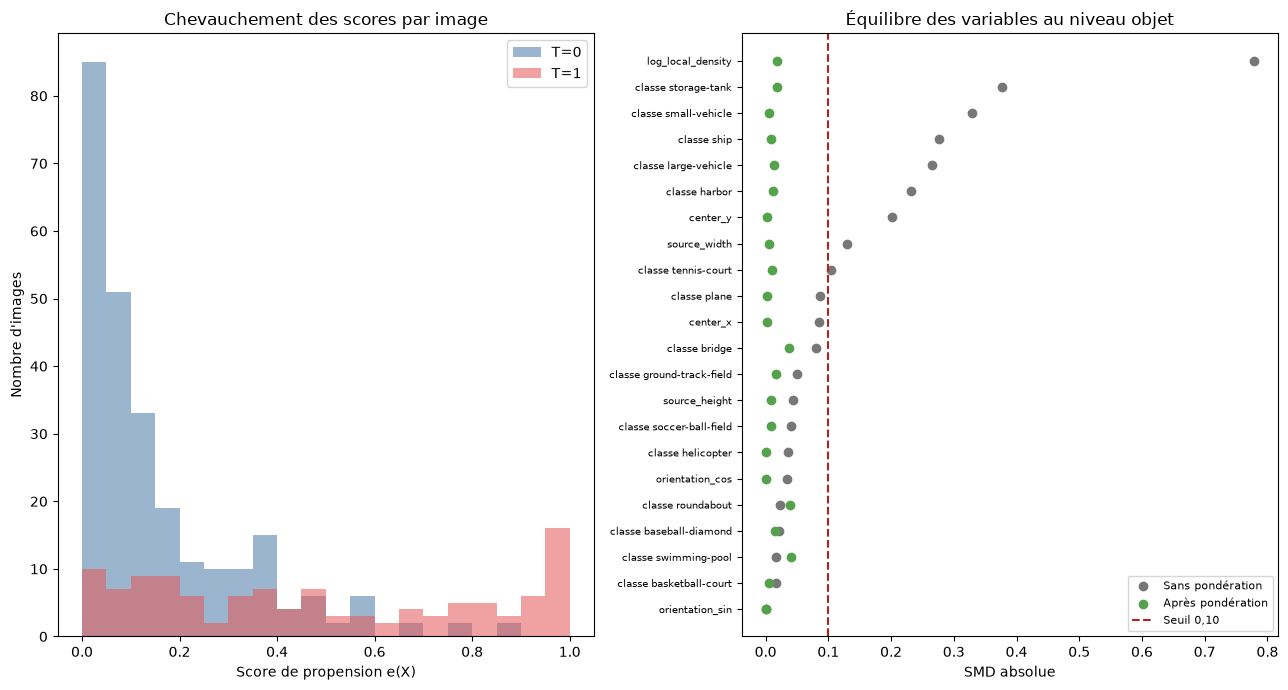

SMD maximale après pondération : 0.040
Variables dépassant 0,10 : 0


,variable,sans pondération,avec poids de chevauchement
13,class_swimming-pool,0.017,0.040
8,class_roundabout,0.024,0.039
2,class_bridge,0.080,0.037
15,log_local_density,0.778,0.018
12,class_storage-tank,0.377,0.018
3,class_ground-track-field,0.051,0.017
0,class_baseball-diamond,0.022,0.016
6,class_large-vehicle,0.265,0.013
4,class_harbor,0.231,0.012
14,class_tennis-court,0.105,0.010


In [63]:
import matplotlib.pyplot as plt


# Chaque classe devient un indicateur : 1 pour cette classe, 0 sinon.
q5_class_indicators_df = pd.get_dummies(
    q5_analysis_df["class_name"], prefix="class", dtype=float
)
q5_balance_df = pd.concat(
    [q5_analysis_df.reset_index(drop=True), q5_class_indicators_df], axis=1
)
q5_balance_columns = q5_class_indicators_df.columns.tolist() + [
    "log_local_density", "orientation_sin", "orientation_cos",
    "center_x", "center_y", "source_width", "source_height",
]


def q5_weighted_mean(values, weights):
    """Calcule une moyenne où chaque valeur reçoit le poids indiqué."""
    return float(np.average(values, weights=weights))


q5_control = q5_balance_df["T"].eq(0).to_numpy()
q5_treated = q5_balance_df["T"].eq(1).to_numpy()
q5_object_weights = q5_balance_df["overlap_weight"].to_numpy(dtype=float)
q5_smd_rows = []

for q5_variable in q5_balance_columns:
    q5_values = q5_balance_df[q5_variable].to_numpy(dtype=float)
    q5_control_values = q5_values[q5_control]
    q5_treated_values = q5_values[q5_treated]
    q5_pooled_sd = np.sqrt(
        (q5_control_values.var(ddof=1) + q5_treated_values.var(ddof=1)) / 2
    )
    if q5_pooled_sd <= 1e-12:
        q5_pooled_sd = np.inf

    q5_smd_rows.append({
        "variable": q5_variable,
        "sans pondération": abs(
            q5_treated_values.mean() - q5_control_values.mean()
        ) / q5_pooled_sd,
        "avec poids de chevauchement": abs(
            q5_weighted_mean(
                q5_treated_values, q5_object_weights[q5_treated]
            )
            - q5_weighted_mean(
                q5_control_values, q5_object_weights[q5_control]
            )
        ) / q5_pooled_sd,
    })

q5_smd_df = pd.DataFrame(q5_smd_rows).sort_values(
    "sans pondération", ascending=True
)
q5_maximum_smd = q5_smd_df["avec poids de chevauchement"].max()
if q5_maximum_smd > 0.10:
    raise ValueError("Les groupes restent trop déséquilibrés après pondération.")

# Le premier graphique montre le chevauchement des scores; le second
# montre comment les poids rapprochent les 22 variables des deux groupes.
q5_figure, q5_axes = plt.subplots(1, 2, figsize=(13, 7))
for q5_t_value, q5_label, q5_color in [
    (0, "T=0", "#4C78A8"),
    (1, "T=1", "#E45756"),
]:
    q5_mask = q5_image_propensity_df["T"].eq(q5_t_value)
    q5_axes[0].hist(
        q5_image_propensity_df.loc[q5_mask, "propensity_score"],
        bins=np.linspace(0, 1, 21),
        alpha=0.55,
        color=q5_color,
        label=q5_label,
    )
q5_axes[0].set(
    title="Chevauchement des scores par image",
    xlabel="Score de propension e(X)",
    ylabel="Nombre d'images",
)
q5_axes[0].legend()

q5_y_positions = np.arange(len(q5_smd_df))
q5_axes[1].scatter(
    q5_smd_df["sans pondération"], q5_y_positions,
    label="Sans pondération", color="#777777",
)
q5_axes[1].scatter(
    q5_smd_df["avec poids de chevauchement"], q5_y_positions,
    label="Après pondération", color="#54A24B",
)
q5_axes[1].axvline(0.10, color="#B22222", linestyle="--", label="Seuil 0,10")
q5_axes[1].set_yticks(q5_y_positions)
q5_axes[1].set_yticklabels(
    [name.replace("class_", "classe ") for name in q5_smd_df["variable"]],
    fontsize=7,
)
q5_axes[1].set(
    title="Équilibre des variables au niveau objet",
    xlabel="SMD absolue",
)
q5_axes[1].legend(fontsize=8)
q5_figure.tight_layout()
plt.show()

print("SMD maximale après pondération :", f"{q5_maximum_smd:.3f}")
print(
    "Variables dépassant 0,10 :",
    int((q5_smd_df["avec poids de chevauchement"] > 0.10).sum()),
)
display(
    q5_smd_df.sort_values(
        "avec poids de chevauchement", ascending=False
    ).head(10).round(3)
)

#### Interprétation du score retenu

Le contrôle OOF donne une AUC de `0,7135` et un score de Brier de `0,1918` au niveau image. Le modèle contient donc une information réelle sur l'appartenance à `T=1`, sans séparer parfaitement les deux groupes; ce chevauchement est justement nécessaire pour effectuer une comparaison causale.

Après l'ajustement complet et l'application des poids de chevauchement, la SMD maximale parmi les 22 variables contrôlées est de `0,040`. Aucune ne dépasse `0,10`. Les objets comparés dans les groupes `T=0` et `T=1` sont donc nettement plus semblables qu'au départ.

Le score complet sert seulement à construire les poids dans l'échantillon observé. Les scores OOF restent le contrôle de généralisation. À l'étape suivante, nous utiliserons ces poids pour estimer l'ATO et nous calculerons son incertitude en rééchantillonnant des images entières.

### 5 - Estimer l'effet moyen ATO

Nous comparons maintenant deux taux de détection dans la même population de chevauchement :

- $\mu_0$ : taux attendu sous `T=0`, donc avec une meilleure résolution;
- $\mu_1$ : taux attendu sous `T=1`, donc avec une faible résolution.

Pour chaque groupe, le taux pondéré est :

$$
\mu_t=
\frac{\sum_{i:T_i=t} w_iY_i}
     {\sum_{i:T_i=t} w_i}.
$$

L'effet recherché est ensuite :

$$
ATO=\mu_1-\mu_0.
$$

Un résultat négatif signifie que la faible résolution diminue la probabilité de détection. Par exemple, `-0,10` représente une diminution de 10 points de pourcentage, et non une diminution relative de 10 %.

Les objets d'une même image partagent le GSD et le contexte visuel. Pour mesurer correctement l'incertitude, le bootstrap rééchantillonne donc des images entières plutôt que des objets isolés.

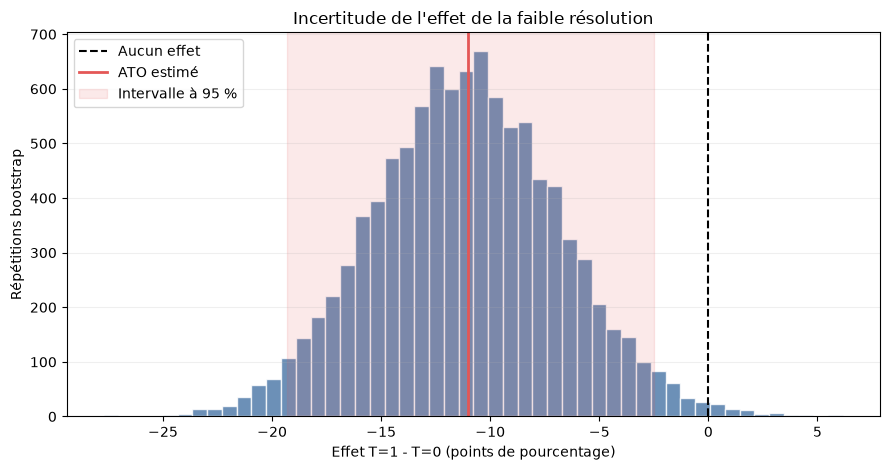

,analyse,taux T=0,taux T=1,différence T=1 - T=0
0,Différence brute descriptive,0.9158,0.7467,-0.1692
1,Effet pondéré ATO,0.9143,0.8042,-0.1101


,effet ATO (points),erreur-type bootstrap (points),IC 95 % inférieur (points),IC 95 % supérieur (points),images,répétitions
0,-11.01,4.29,-19.31,-2.48,375,10000


In [64]:
# Vérifier que la table contient toutes les variables nécessaires à l'ATO.

q5_ato_columns = [
    "source_object_id", "source_image_id", "T", "Y", "overlap_weight",
]
q5_missing_ato_columns = [
    column for column in q5_ato_columns if column not in q5_analysis_df.columns
]
if q5_missing_ato_columns:
    raise ValueError(f"Colonnes ATO manquantes : {q5_missing_ato_columns}")
if len(q5_analysis_df) != 66_968:
    raise ValueError("La population ATO attendue a changé.")
if q5_analysis_df[q5_ato_columns].isna().any().any():
    raise ValueError("Une valeur nécessaire à l'ATO est manquante.")
if q5_maximum_smd > 0.10:
    raise ValueError("L'équilibre doit être validé avant d'estimer l'ATO.")

q5_ato_T = q5_analysis_df["T"].to_numpy(dtype=int)
q5_ato_Y = q5_analysis_df["Y"].to_numpy(dtype=int)
q5_ato_weights = q5_analysis_df["overlap_weight"].to_numpy(dtype=float)


def q5_detection_rate(treatment_value, weights=None):
    """Calcule le taux de détection brut ou pondéré d'un groupe."""
    group = q5_ato_T == treatment_value
    if weights is None:
        return float(q5_ato_Y[group].mean())
    return float(np.average(q5_ato_Y[group], weights=weights[group]))


# La différence brute est descriptive; l'ATO utilise les poids validés.
q5_raw_mu_0 = q5_detection_rate(0)
q5_raw_mu_1 = q5_detection_rate(1)
q5_weighted_mu_0 = q5_detection_rate(0, q5_ato_weights)
q5_weighted_mu_1 = q5_detection_rate(1, q5_ato_weights)
q5_ato_effect = q5_weighted_mu_1 - q5_weighted_mu_0

q5_rate_comparison_df = pd.DataFrame([
    {
        "analyse": "Différence brute descriptive",
        "taux T=0": q5_raw_mu_0,
        "taux T=1": q5_raw_mu_1,
        "différence T=1 - T=0": q5_raw_mu_1 - q5_raw_mu_0,
    },
    {
        "analyse": "Effet pondéré ATO",
        "taux T=0": q5_weighted_mu_0,
        "taux T=1": q5_weighted_mu_1,
        "différence T=1 - T=0": q5_ato_effect,
    },
])

# Nous résumons chaque image par sa somme de poids et sa somme de w × Y.
q5_bootstrap_rows_df = q5_analysis_df[
    ["source_image_id", "T", "Y", "overlap_weight"]
].copy()
q5_bootstrap_rows_df["weighted_Y"] = (
    q5_bootstrap_rows_df["overlap_weight"] * q5_bootstrap_rows_df["Y"]
)
if not (
    q5_bootstrap_rows_df.groupby("source_image_id")["T"]
    .nunique().eq(1).all()
):
    raise ValueError("Le traitement varie dans une même image.")
q5_image_contributions_df = (
    q5_bootstrap_rows_df.groupby("source_image_id", as_index=False)
    .agg(
        T=("T", "first"),
        object_count=("Y", "size"),
        weight_sum=("overlap_weight", "sum"),
        weighted_Y_sum=("weighted_Y", "sum"),
    )
)
if len(q5_image_contributions_df) != 375:
    raise ValueError("Le bootstrap doit contenir 375 images.")
q5_image_group_counts = (
    q5_image_contributions_df["T"].value_counts().to_dict()
)
if q5_image_group_counts != {0: 258, 1: 117}:
    raise ValueError("La répartition des images entre T=0 et T=1 a changé.")

# À chaque répétition, les images sont tirées avec remise séparément
# dans T=0 et T=1. Les deux groupes restent ainsi toujours présents.
Q5_BOOTSTRAP_REPETITIONS = 10_000
q5_random_generator = np.random.default_rng(42)
q5_bootstrap_rates = {}

for q5_treatment_value in (0, 1):
    q5_group_images_df = q5_image_contributions_df.loc[
        q5_image_contributions_df["T"].eq(q5_treatment_value)
    ].reset_index(drop=True)
    q5_group_size = len(q5_group_images_df)
    q5_sampled_positions = q5_random_generator.integers(
        0,
        q5_group_size,
        size=(Q5_BOOTSTRAP_REPETITIONS, q5_group_size),
    )
    q5_sampled_weight_sums = q5_group_images_df[
        "weight_sum"
    ].to_numpy()[q5_sampled_positions].sum(axis=1)
    q5_sampled_outcome_sums = q5_group_images_df[
        "weighted_Y_sum"
    ].to_numpy()[q5_sampled_positions].sum(axis=1)
    q5_bootstrap_rates[q5_treatment_value] = (
        q5_sampled_outcome_sums / q5_sampled_weight_sums
    )

q5_bootstrap_effects = q5_bootstrap_rates[1] - q5_bootstrap_rates[0]
q5_ato_standard_error = float(q5_bootstrap_effects.std(ddof=1))
q5_ato_ci_lower, q5_ato_ci_upper = np.quantile(
    q5_bootstrap_effects, [0.025, 0.975]
)

q5_ato_summary_df = pd.DataFrame([{
    "effet ATO (points)": 100 * q5_ato_effect,
    "erreur-type bootstrap (points)": 100 * q5_ato_standard_error,
    "IC 95 % inférieur (points)": 100 * q5_ato_ci_lower,
    "IC 95 % supérieur (points)": 100 * q5_ato_ci_upper,
    "images": len(q5_image_contributions_df),
    "répétitions": Q5_BOOTSTRAP_REPETITIONS,
}])

q5_figure, q5_axis = plt.subplots(figsize=(9, 4.8))
q5_axis.hist(
    100 * q5_bootstrap_effects,
    bins=50,
    color="#4C78A8",
    alpha=0.82,
    edgecolor="white",
)
q5_axis.axvline(0, color="black", linestyle="--", label="Aucun effet")
q5_axis.axvline(
    100 * q5_ato_effect,
    color="#E45756",
    linewidth=2,
    label="ATO estimé",
)
q5_axis.axvspan(
    100 * q5_ato_ci_lower,
    100 * q5_ato_ci_upper,
    color="#E45756",
    alpha=0.13,
    label="Intervalle à 95 %",
)
q5_axis.set(
    title="Incertitude de l'effet de la faible résolution",
    xlabel="Effet T=1 - T=0 (points de pourcentage)",
    ylabel="Répétitions bootstrap",
)
q5_axis.legend()
q5_axis.grid(axis="y", alpha=0.2)
q5_figure.tight_layout()
plt.show()

display(q5_rate_comparison_df.round(4))
display(q5_ato_summary_df.round(2))

#### Interprétation de l'ATO

Sans ajustement, le taux de détection passe de `91,58 %` pour `T=0` à `74,67 %` pour `T=1`, soit une différence descriptive de `-16,92 points`.

Après pondération, les taux comparables sont estimés à `91,43 %` sous meilleure résolution et `80,42 %` sous faible résolution. L'ATO vaut donc `-11,01 points de pourcentage`. Une partie de la différence brute provenait de la composition différente des groupes, mais l'écart ne disparaît pas après l'ajustement.

Le bootstrap de 10 000 rééchantillonnages d'images donne un intervalle à 95 % de `[-19,31 ; -2,48] points`. Comme cet intervalle reste entièrement négatif, les données sont compatibles avec une diminution de la probabilité de détection sous faible résolution, sous les hypothèses causales retenues.

Cette conclusion concerne les objets comparables de la population `GoogleEarth`, et non tous les objets DOTA. L'intervalle représente l'incertitude entre les images, mais il ne corrige pas une éventuelle variable de confusion qui n'aurait pas été mesurée. Les poids restent également fixes pendant le bootstrap : l'incertitude liée à l'estimation du score de propension n'est donc pas recalculée à chaque répétition.

### 6 - Préparer la régression du résultat

La forêt causale doit distinguer l'effet de `T` de ce que les variables `X` expliquent déjà dans la détection. Nous estimons donc deux probabilités :

- `m0(X)` : probabilité de détection prévue sous meilleure résolution;
- `m1(X)` : probabilité de détection prévue sous faible résolution.

Le modèle `m0` apprend avec les objets observés sous `T=0` et le modèle `m1` avec ceux observés sous `T=1`. Ils utilisent uniquement les caractéristiques disponibles avant la détection : classe, densité, orientation, position, dimensions et composition de l'image.

Pour un objet réellement soumis à `T=0`, seule la prédiction `m0(X)` peut être comparée au véritable `Y`; `m1(X)` représente une situation contrefactuelle non observée. La situation est inversée pour un objet soumis à `T=1`.

In [65]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.preprocessing import OneHotEncoder


# Les variables propres à l'objet sont complétées par les résumés de son image.
q5_outcome_object_columns = [
    "source_object_id", "source_image_id", "class_name", "T", "Y",
    "propensity_fold", "log_local_density", "orientation_sin",
    "orientation_cos", "center_x", "center_y",
    "source_width", "source_height",
]
q5_missing_outcome_columns = [
    column for column in q5_outcome_object_columns
    if column not in q5_analysis_df.columns
]
if q5_missing_outcome_columns:
    raise ValueError(
        f"Variables de résultat manquantes : {q5_missing_outcome_columns}"
    )

q5_outcome_df = q5_analysis_df[q5_outcome_object_columns].copy()
q5_outcome_image_columns = [
    column for column in q5_propensity_feature_columns
    if column not in {"source_width", "source_height"}
]
q5_outcome_image_df = q5_image_propensity_df[
    ["source_image_id"] + q5_outcome_image_columns
].copy()
q5_outcome_df = q5_outcome_df.merge(
    q5_outcome_image_df,
    on="source_image_id",
    how="left",
    validate="many_to_one",
)

# La classe reste catégorielle; toutes les autres variables sont numériques.
q5_outcome_categorical_columns = ["class_name"]
q5_outcome_numeric_columns = [
    "log_local_density", "orientation_sin", "orientation_cos",
    "center_x", "center_y", "source_width", "source_height",
] + q5_outcome_image_columns
q5_outcome_feature_columns = (
    q5_outcome_categorical_columns + q5_outcome_numeric_columns
)

if len(q5_outcome_df) != 66_968:
    raise ValueError("La régression du résultat attend 66 968 objets.")
if q5_outcome_df[q5_outcome_feature_columns].isna().any().any():
    raise ValueError("Une variable du modèle de résultat est manquante.")
if not np.isfinite(
    q5_outcome_df[q5_outcome_numeric_columns].to_numpy(dtype=float)
).all():
    raise ValueError("Une variable numérique du résultat n'est pas finie.")
if not (
    q5_outcome_df.groupby("source_image_id")["propensity_fold"]
    .nunique().eq(1).all()
):
    raise ValueError("Le pli varie dans une même image.")

# OneHotEncoder transforme la classe en indicateurs 0/1.
# StandardScaler place les variables numériques sur des échelles comparables.
q5_outcome_preprocessor = ColumnTransformer(
    transformers=[
        (
            "class",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            q5_outcome_categorical_columns,
        ),
        ("numbers", StandardScaler(), q5_outcome_numeric_columns),
    ],
    remainder="drop",
)
q5_outcome_model = Pipeline(steps=[
    ("preparation", q5_outcome_preprocessor),
    (
        "model",
        LogisticRegression(solver="lbfgs", C=1.0, max_iter=3000),
    ),
])

print("Objets préparés :", len(q5_outcome_df))
print("Variables numériques :", len(q5_outcome_numeric_columns))
print("Variable catégorielle : class_name")
display(q5_outcome_df.head())

Objets préparés : 66968
Variables numériques : 30
Variable catégorielle : class_name


,source_object_id,source_image_id,class_name,T,Y,propensity_fold,log_local_density,orientation_sin,orientation_cos,center_x,...,class_share__harbor,class_share__helicopter,class_share__large_vehicle,class_share__plane,class_share__roundabout,class_share__ship,class_share__small_vehicle,class_share__soccer_ball_field,class_share__storage_tank,class_share__tennis_court
0,validation__P0003__object_0,P0003,small-vehicle,0,1,2,3.871201,-0.156917,-0.987612,0.811029,...,0.0,0.0,0.727273,0.0,0.0,0.0,0.272727,0.0,0.0,0.0
1,validation__P0003__object_1,P0003,large-vehicle,0,1,2,3.871201,0.142132,0.989848,0.580427,...,0.0,0.0,0.727273,0.0,0.0,0.0,0.272727,0.0,0.0,0.0
2,validation__P0003__object_10,P0003,large-vehicle,0,1,2,3.871201,0.377277,-0.926100,0.327158,...,0.0,0.0,0.727273,0.0,0.0,0.0,0.272727,0.0,0.0,0.0
3,validation__P0003__object_11,P0003,large-vehicle,0,1,2,3.871201,0.295572,-0.955321,0.299259,...,0.0,0.0,0.727273,0.0,0.0,0.0,0.272727,0.0,0.0,0.0
4,validation__P0003__object_12,P0003,large-vehicle,0,1,2,3.871201,0.309299,-0.950965,0.270052,...,0.0,0.0,0.727273,0.0,0.0,0.0,0.272727,0.0,0.0,0.0


### 7 - Produire `m0(X)` et `m1(X)` hors pli

Nous réutilisons les cinq plis définis au niveau des images. Pour chaque pli, deux régressions apprennent sur les quatre autres plis, puis prédisent tous les objets du pli laissé de côté. Dix modèles sont donc ajustés au total.

Cette organisation évite qu'une image serve à la fois à apprendre et à évaluer ses propres probabilités. Les prédictions hors pli pourront ensuite être utilisées pour retirer de `Y` la partie déjà prévisible à partir de `X`, avant l'entraînement de la forêt causale.

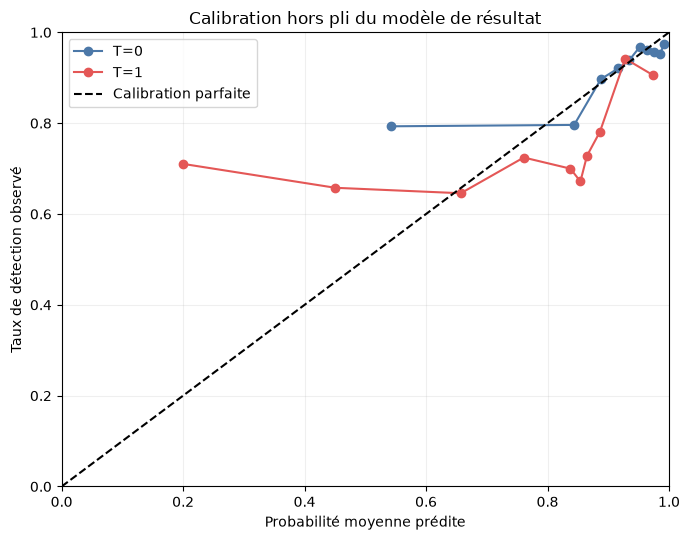

,groupe,images,objets,taux observé,probabilité prédite,AUC,Brier
0,Tous les objets,375,66968,0.8359,0.8246,0.7205,0.1472
1,"T=0, meilleure résolution",258,35325,0.9158,0.8992,0.7107,0.0824
2,"T=1, faible résolution",117,31643,0.7467,0.7413,0.6194,0.2196


,pli,images_apprentissage,images_validation,objets_validation
0,1,300,75,11759
1,2,300,75,10875
2,3,300,75,10812
3,4,300,75,9409
4,5,300,75,24113


In [66]:
# Séparer les variables explicatives X, le traitement T, le résultat Y et les plis.
q5_outcome_X = q5_outcome_df[q5_outcome_feature_columns]
q5_outcome_T = q5_outcome_df["T"].to_numpy(dtype=int)
q5_outcome_Y = q5_outcome_df["Y"].to_numpy(dtype=int)
q5_outcome_folds = q5_outcome_df["propensity_fold"].to_numpy(dtype=int)

# Une case est réservée par objet pour m0(X) et m1(X). Les NaN seront
# remplacés par des prédictions hors pli, puis serviront au contrôle final.
q5_m0_oof = np.full(len(q5_outcome_df), np.nan)
q5_m1_oof = np.full(len(q5_outcome_df), np.nan)
q5_outcome_fold_rows = []

# À chaque tour, quatre plis entraînent les modèles et le cinquième est prédit.
for q5_fold in range(1, 6):
    q5_training = q5_outcome_folds != q5_fold
    q5_validation = q5_outcome_folds == q5_fold

    # Les ensembles d'images doivent être entièrement séparés.
    q5_training_images = set(
        q5_outcome_df.loc[q5_training, "source_image_id"]
    )
    q5_validation_images = set(
        q5_outcome_df.loc[q5_validation, "source_image_id"]
    )
    if q5_training_images & q5_validation_images:
        raise ValueError("Une image apparaît dans les deux parties d'un pli.")

    # m0 apprend dans T=0 et m1 dans T=1; les deux prédisent le pli exclu.
    for q5_treatment_value, q5_destination in (
        (0, q5_m0_oof), (1, q5_m1_oof)
    ):
        q5_arm_training = q5_training & (q5_outcome_T == q5_treatment_value)
        # clone recrée la même chaîne de traitement sans modèle déjà entraîné.
        q5_fold_model = clone(q5_outcome_model)
        q5_fold_model.fit(
            q5_outcome_X.loc[q5_arm_training],
            q5_outcome_Y[q5_arm_training],
        )
        # predict_proba renvoie [P(Y=0), P(Y=1)]; [:, 1] garde la détection.
        q5_destination[q5_validation] = q5_fold_model.predict_proba(
            q5_outcome_X.loc[q5_validation]
        )[:, 1]

    # Conserver la taille des parties du pli pour vérifier le découpage.
    q5_outcome_fold_rows.append({
        "pli": q5_fold,
        "images_apprentissage": len(q5_training_images),
        "images_validation": len(q5_validation_images),
        "objets_validation": int(q5_validation.sum()),
    })

# Toutes les cases initialement NaN doivent maintenant contenir une probabilité.
if not np.isfinite(q5_m0_oof).all() or not np.isfinite(q5_m1_oof).all():
    raise ValueError("Certains objets n'ont pas reçu leurs deux probabilités.")

# Seule la probabilité correspondant au traitement réellement reçu est factuelle.
q5_m_observed_oof = np.where(
    q5_outcome_T == 1, q5_m1_oof, q5_m0_oof
)
# Mesurer la qualité prédictive globale, puis séparément dans T=0 et T=1.
# roc_auc_score évalue le classement : 0,5 correspond au hasard et 1 au parfait.
q5_outcome_metric_rows = []
for q5_treatment_value, q5_label in (
    (None, "Tous les objets"),
    (0, "T=0, meilleure résolution"),
    (1, "T=1, faible résolution"),
):
    if q5_treatment_value is None:
        # Un masque rempli de True sélectionne ici tous les objets.
        q5_metric_mask = np.ones(len(q5_outcome_df), dtype=bool)
    else:
        q5_metric_mask = q5_outcome_T == q5_treatment_value
    q5_outcome_metric_rows.append({
        "groupe": q5_label,
        "images": q5_outcome_df.loc[
            q5_metric_mask, "source_image_id"
        ].nunique(),
        "objets": int(q5_metric_mask.sum()),
        "taux observé": q5_outcome_Y[q5_metric_mask].mean(),
        "probabilité prédite": q5_m_observed_oof[q5_metric_mask].mean(),
        "AUC": roc_auc_score(
            q5_outcome_Y[q5_metric_mask],
            q5_m_observed_oof[q5_metric_mask],
        ),
        "Brier": brier_score_loss(
            q5_outcome_Y[q5_metric_mask],
            q5_m_observed_oof[q5_metric_mask],
        ),
    })

q5_outcome_metrics_df = pd.DataFrame(q5_outcome_metric_rows)
q5_outcome_folds_df = pd.DataFrame(q5_outcome_fold_rows)

# La calibration compare les probabilités factuelles aux taux réellement observés.
q5_calibration_rows = []
for q5_treatment_value, q5_label in ((0, "T=0"), (1, "T=1")):
    q5_group = q5_outcome_T == q5_treatment_value
    q5_group_df = pd.DataFrame({
        "prediction": q5_m_observed_oof[q5_group],
        "observation": q5_outcome_Y[q5_group],
    })
    # Le classement départage les scores égaux; qcut crée dix groupes de taille proche.
    q5_group_df["décile"] = pd.qcut(
        q5_group_df["prediction"].rank(method="first"),
        q=10,
        labels=False,
    ) + 1
    q5_group_summary_df = (
        q5_group_df.groupby("décile", as_index=False)
        .agg(
            probabilité_prédite=("prediction", "mean"),
            taux_observé=("observation", "mean"),
        )
    )
    q5_group_summary_df["groupe"] = q5_label
    q5_calibration_rows.append(q5_group_summary_df)
q5_outcome_calibration_df = pd.concat(
    q5_calibration_rows, ignore_index=True
)

# Les trois probabilités sont conservées pour la forêt causale.
q5_analysis_df["m0_oof"] = q5_m0_oof
q5_analysis_df["m1_oof"] = q5_m1_oof
q5_analysis_df["m_observed_oof"] = q5_m_observed_oof

# Une courbe proche de la diagonale indique des probabilités bien calibrées.
q5_figure, q5_axis = plt.subplots(figsize=(7, 5.5))
for q5_label, q5_color in (("T=0", "#4C78A8"), ("T=1", "#E45756")):
    q5_plot_rows = q5_outcome_calibration_df.loc[
        q5_outcome_calibration_df["groupe"].eq(q5_label)
    ]
    q5_axis.plot(
        q5_plot_rows["probabilité_prédite"],
        q5_plot_rows["taux_observé"],
        marker="o",
        color=q5_color,
        label=q5_label,
    )
q5_axis.plot([0, 1], [0, 1], "--", color="black", label="Calibration parfaite")
q5_axis.set(
    title="Calibration hors pli du modèle de résultat",
    xlabel="Probabilité moyenne prédite",
    ylabel="Taux de détection observé",
    xlim=(0, 1),
    ylim=(0, 1),
)
q5_axis.grid(alpha=0.2)
q5_axis.legend()
q5_figure.tight_layout()
plt.show()

display(q5_outcome_metrics_df.round(4))
display(q5_outcome_folds_df)

#### Interprétation de la régression du résultat

Sur l'ensemble des objets, la probabilité factuelle moyenne prédite est de `82,46 %`, contre un taux observé de `83,59 %`. L'AUC hors pli vaut `0,7205` : les caractéristiques `X` contiennent donc une information utile pour prévoir les détections.

Le modèle fonctionne moins bien sous faible résolution. Son AUC vaut `0,6194` et son score de Brier `0,2196` dans `T=1`, contre respectivement `0,7107` et `0,0824` dans `T=0`. La courbe de calibration montre également des écarts plus importants dans le groupe de faible résolution.

Ces résultats ne constituent pas un nouvel effet causal. Ils montrent seulement que les probabilités `m0(X)` et `m1(X)` sont utiles, mais imparfaites. La forêt causale les utilisera pour retirer de `Y` la partie déjà expliquée par `X`; ses conclusions devront tenir compte de cette calibration moins bonne dans `T=1`.

### 8 - Retirer de `T` et `Y` la partie expliquée par `X`

Avant d'estimer des effets différents selon les objets, la forêt doit travailler sur ce que les modèles précédents n'expliquent pas déjà. Nous construisons donc une probabilité moyenne de détection :

$$
m(X) = [1-e(X)]m_0(X) + e(X)m_1(X)
$$

où `e(X)` est le score de propension, tandis que `m0(X)` et `m1(X)` sont les probabilités de détection prédites sous `T=0` et `T=1`. Nous calculons ensuite :

$$
T_{res} = T-e(X)
$$

$$
Y_{res} = Y-m(X)
$$

`T_res` représente la partie du traitement imprévisible à partir de `X`; `Y_res` représente la partie de la détection encore inexpliquée. Ce ne sont pas encore des effets causaux. La forêt cherchera ensuite si les variations restantes de `T` sont associées aux variations restantes de `Y`. Les trois probabilités sont hors pli afin que chaque image soit corrigée par des modèles qui ne l'ont pas utilisée pendant leur apprentissage.

In [67]:
# Rassembler les variables nécessaires aux résidus et à la future forêt.
q5_residual_input_columns = [
    "source_object_id", "source_image_id", "class_name",
    "log_local_density", "orientation_sin", "orientation_cos",
    "center_x", "center_y", "T", "Y",
    "propensity_fold", "propensity_oof", "propensity_score",
    "m0_oof", "m1_oof",
]
q5_missing_residual_columns = [
    column for column in q5_residual_input_columns
    if column not in q5_analysis_df.columns
]
if q5_missing_residual_columns:
    raise ValueError(
        f"Variables nécessaires aux résidus manquantes : "
        f"{q5_missing_residual_columns}"
    )

q5_forest_df = q5_analysis_df[q5_residual_input_columns].copy()

# e(X), m0(X) et m1(X) proviennent de prédictions hors pli.
q5_e_oof = q5_forest_df["propensity_oof"].to_numpy(dtype=float)
q5_m0_oof = q5_forest_df["m0_oof"].to_numpy(dtype=float)
q5_m1_oof = q5_forest_df["m1_oof"].to_numpy(dtype=float)
q5_forest_T = q5_forest_df["T"].to_numpy(dtype=float)
q5_forest_Y = q5_forest_df["Y"].to_numpy(dtype=float)

# m(X) moyenne les deux résultats potentiels selon la propension estimée.
q5_expected_Y = (1 - q5_e_oof) * q5_m0_oof + q5_e_oof * q5_m1_oof

# Les résidus retirent de T et Y la partie déjà expliquée par X.
q5_T_residual = q5_forest_T - q5_e_oof
q5_Y_residual = q5_forest_Y - q5_expected_Y

q5_forest_df["expected_Y_oof"] = q5_expected_Y
q5_forest_df["T_residual"] = q5_T_residual
q5_forest_df["Y_residual"] = q5_Y_residual

# Vérifier que chaque objet possède des valeurs finies et cohérentes.
q5_values_to_check = q5_forest_df[[
    "propensity_oof", "m0_oof", "m1_oof",
    "expected_Y_oof", "T_residual", "Y_residual",
]].to_numpy(dtype=float)
if not np.isfinite(q5_values_to_check).all():
    raise ValueError("Un résidu ou une probabilité est manquant.")
if ((q5_e_oof <= 0) | (q5_e_oof >= 1)).any():
    raise ValueError("Le score de propension doit être entre 0 et 1.")
if ((q5_expected_Y < 0) | (q5_expected_Y > 1)).any():
    raise ValueError("m(X) doit être une probabilité entre 0 et 1.")
if len(q5_forest_df) != 66_968:
    raise ValueError("La population de la forêt a changé.")

# Résumer les quantités obtenues dans chacun des deux groupes.
q5_residual_summary_df = (
    q5_forest_df.groupby("T", as_index=False)
    .agg(
        images=("source_image_id", "nunique"),
        objets=("source_object_id", "size"),
        propension_moyenne=("propensity_oof", "mean"),
        T_res_moyen=("T_residual", "mean"),
        Y_res_moyen=("Y_residual", "mean"),
    )
)

display(q5_residual_summary_df.round(4))

,T,images,objets,propension_moyenne,T_res_moyen,Y_res_moyen
0,0,258,35325,0.4103,-0.4103,0.0591
1,1,117,31643,0.5601,0.4399,-0.0863


### 9 - Définir les caractéristiques qui peuvent modifier l'effet

La forêt causale cherchera si l'effet de la faible résolution varie selon la classe, la densité locale, l'orientation ou la position de l'objet. La classe est transformée en 15 indicateurs `0/1`; elle est complétée par cinq variables numériques : la densité, le sinus et le cosinus de l'orientation, puis les deux coordonnées du centre.

Le GSD exact n'est pas fourni à la forêt puisqu'il définit déjà le traitement `T`. Les identifiants, la confiance de YOLO et le ProbIoU sont également exclus : ils ne décrivent pas des caractéristiques antérieures au traitement.

Pour viser la même population de chevauchement que l'ATO, le poids de la forêt est proportionnel à `h(X) = e(X)[1-e(X)]`. Il est maximal lorsque `T=0` et `T=1` sont tous les deux plausibles. Enfin, les plis précédents sont conservés : tous les objets d'une même image restent toujours ensemble.

In [68]:
# La classe devient un indicateur 0/1 pour chacune des 15 catégories.
q5_forest_class_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    dtype=np.float64,
)
q5_forest_class_matrix = q5_forest_class_encoder.fit_transform(
    q5_forest_df[["class_name"]]
)
q5_forest_class_features = list(
    q5_forest_class_encoder.get_feature_names_out(["class_name"])
)

# Ces variables pourront séparer les objets ayant des effets différents.
q5_forest_numeric_features = [
    "log_local_density",
    "orientation_sin", "orientation_cos",
    "center_x", "center_y",
]
q5_forest_numeric_matrix = q5_forest_df[
    q5_forest_numeric_features
].to_numpy(dtype=float)

# column_stack place les indicateurs de classe et les variables numériques côte à côte.
q5_forest_X = np.column_stack([
    q5_forest_class_matrix,
    q5_forest_numeric_matrix,
])
q5_forest_feature_names = (
    q5_forest_class_features + q5_forest_numeric_features
)

# h=e(1-e) favorise les profils où les deux valeurs de T sont plausibles.
q5_e_full = q5_forest_df["propensity_score"].to_numpy(dtype=float)
q5_forest_weights = q5_e_full * (1 - q5_e_full)
q5_forest_weights = q5_forest_weights / q5_forest_weights.mean()
q5_forest_df["forest_weight"] = q5_forest_weights

# Les plis sont définis au niveau image et seront réutilisés pour la forêt.
q5_forest_folds = q5_forest_df["propensity_fold"].to_numpy(dtype=int)
q5_image_consistency_df = q5_forest_df.groupby("source_image_id")[
    ["T", "propensity_fold"]
].nunique()

# Contrôler la forme de la matrice et l'intégrité du découpage.
if q5_forest_X.shape != (66_968, 20):
    raise ValueError("La forêt attend 66 968 objets et 20 variables.")
if not np.isfinite(q5_forest_X).all():
    raise ValueError("Une caractéristique de la forêt n'est pas finie.")
if not np.isfinite(q5_forest_weights).all() or (q5_forest_weights <= 0).any():
    raise ValueError("Un poids de la forêt est invalide.")
if not q5_image_consistency_df.eq(1).all().all():
    raise ValueError("Une image a été séparée ou possède plusieurs traitements.")
if set(np.unique(q5_forest_folds)) != {1, 2, 3, 4, 5}:
    raise ValueError("Les cinq plis sont nécessaires.")

q5_forest_modifier_summary_df = pd.DataFrame([
    {
        "type": "classe",
        "nombre": len(q5_forest_class_features),
        "contenu": "un indicateur 0/1 par classe",
    },
    {
        "type": "numérique",
        "nombre": len(q5_forest_numeric_features),
        "contenu": "densité, orientation et position",
    },
])
q5_forest_fold_summary_df = (
    q5_forest_df.groupby(["propensity_fold", "T"], as_index=False)
    .agg(
        images=("source_image_id", "nunique"),
        objets=("source_object_id", "size"),
    )
    .rename(columns={"propensity_fold": "pli"})
)

display(q5_forest_modifier_summary_df)
display(q5_forest_fold_summary_df)
display(q5_forest_df.head())

,type,nombre,contenu
0,classe,15,un indicateur 0/1 par classe
1,numérique,5,"densité, orientation et position"


,pli,T,images,objets
0,1,0,52,4552
1,1,1,23,7207
2,2,0,52,7773
3,2,1,23,3102
4,3,0,52,5626
5,3,1,23,5186
6,4,0,51,6463
7,4,1,24,2946
8,5,0,51,10911
9,5,1,24,13202


,source_object_id,source_image_id,class_name,log_local_density,orientation_sin,orientation_cos,center_x,center_y,T,Y,propensity_fold,propensity_oof,propensity_score,m0_oof,m1_oof,expected_Y_oof,T_residual,Y_residual,forest_weight
0,validation__P0003__object_0,P0003,small-vehicle,3.871201,-0.156917,-0.987612,0.811029,0.873412,0,1,2,0.038416,0.047387,0.995210,0.943251,0.993214,-0.038416,0.006786,0.286355
1,validation__P0003__object_1,P0003,large-vehicle,3.871201,0.142132,0.989848,0.580427,0.927419,0,1,2,0.038416,0.047387,0.977415,0.843103,0.972256,-0.038416,0.027744,0.286355
2,validation__P0003__object_10,P0003,large-vehicle,3.871201,0.377277,-0.926100,0.327158,0.306940,0,1,2,0.038416,0.047387,0.958509,0.801301,0.952470,-0.038416,0.047530,0.286355
3,validation__P0003__object_11,P0003,large-vehicle,3.871201,0.295572,-0.955321,0.299259,0.311095,0,1,2,0.038416,0.047387,0.957828,0.801264,0.951813,-0.038416,0.048187,0.286355
4,validation__P0003__object_12,P0003,large-vehicle,3.871201,0.309299,-0.950965,0.270052,0.306452,0,1,2,0.038416,0.047387,0.956239,0.800728,0.950265,-0.038416,0.049735,0.286355


### 10 - Estimer les CATE avec une forêt causale

Le CATE est l'effet moyen du traitement pour un profil d'objet donné :

$$
CATE(v) = E[Y(1)-Y(0)\mid V=v]
$$

Cinq forêts sont entraînées. Chacune apprend sur quatre plis d'images et prédit uniquement le cinquième; chaque objet reçoit ainsi une estimation hors pli. Les arbres sont peu profonds et `honest=True` sépare les observations utilisées pour choisir les coupures de celles utilisées pour estimer les effets.

Une dispersion des CATE ne prouve pas à elle seule que les effets diffèrent réellement. Nous comparons donc la forêt à un modèle plus simple qui applique un seul effet constant. Leur R-loss mesure l'erreur restante :

$$
R = moyenne_w([Y_{res}-CATE(V)T_{res}]^2)
$$

Une R-loss plus faible est meilleure. Le gain indiqué est positif lorsque la forêt fait mieux que l'effet constant; sa stabilité entre les images sera vérifiée ensuite par bootstrap.

In [69]:
from time import perf_counter

from econml.grf import CausalForest


def q5_weighted_r_loss(observed, predicted, weights):
    """Calcule la moyenne pondérée des erreurs au carré."""
    return float(np.average(
        (np.asarray(observed) - np.asarray(predicted)) ** 2,
        weights=np.asarray(weights),
    ))


q5_forest_object_count = len(q5_forest_df)

# Ces tableaux recevront une seule prédiction hors pli par objet.
q5_cate_oof = np.full(q5_forest_object_count, np.nan)
q5_forest_Y_prediction_oof = np.full(q5_forest_object_count, np.nan)
q5_constant_Y_prediction_oof = np.full(q5_forest_object_count, np.nan)
q5_constant_effect_oof = np.full(q5_forest_object_count, np.nan)
q5_forest_assignment_count = np.zeros(q5_forest_object_count, dtype=int)
q5_forest_fold_rows = []

# Beaucoup d'arbres stabilisent la moyenne; la faible profondeur limite
# les sous-groupes trop particuliers et donc le surapprentissage.
Q5_FOREST_TREES = 1_000
# La graine reprend la date 2026-08-21 pour rendre le calcul reproductible.
Q5_FOREST_SEED = 20_260_821

print("Préparation terminée : cinq forêts de 1 000 arbres seront entraînées.")

Préparation terminée : cinq forêts de 1 000 arbres seront entraînées.


In [70]:
# ÉTAPE 1/5 - Séparer les images d'apprentissage et de validation.
# Chaque forêt prédit uniquement les images du pli laissé de côté.
for q5_fold in range(1, 6):
    # Ces deux masques booléens sélectionnent les lignes des deux parties.
    q5_validation = q5_forest_folds == q5_fold
    q5_training = ~q5_validation

    # set conserve les identifiants uniques; leur intersection doit être vide.
    q5_training_images = set(
        q5_forest_df.loc[q5_training, "source_image_id"]
    )
    q5_validation_images = set(
        q5_forest_df.loc[q5_validation, "source_image_id"]
    )
    if q5_training_images & q5_validation_images:
        raise ValueError(f"Le pli {q5_fold} partage une image.")

    # Extraire les résidus et les poids des quatre plis d'apprentissage.
    q5_train_T_res = q5_T_residual[q5_training]
    q5_train_Y_res = q5_Y_residual[q5_training]
    q5_train_weights = q5_forest_weights[q5_training]

    # ÉTAPE 2/5 - Estimer la référence à effet constant sur le train.
    # Cette formule est la pente pondérée de Y_res = effet × T_res.
    q5_constant_denominator = np.sum(
        q5_train_weights * q5_train_T_res ** 2
    )
    q5_constant_effect = float(
        np.sum(q5_train_weights * q5_train_T_res * q5_train_Y_res)
        / q5_constant_denominator
    )

    # ÉTAPE 3/5 - Construire et entraîner la forêt du pli.
    # Chaque arbre reste volontairement simple et utilise de grandes feuilles.
    q5_forest_model = CausalForest(
        n_estimators=Q5_FOREST_TREES,  # Nombre d'arbres à moyenner.
        max_depth=2,                  # Quatre feuilles au maximum par arbre.
        min_samples_split=0.10,       # Au moins 10 % du train avant une coupure.
        min_samples_leaf=0.05,        # Au moins 5 % du train dans chaque feuille.
        honest=True,                  # Coupures et effets utilisent deux sous-échantillons.
        inference=False,              # Aucun intervalle individuel n'est calculé ici.
        n_jobs=-1,                    # Utiliser tous les cœurs CPU disponibles.
        random_state=Q5_FOREST_SEED + q5_fold,  # Graine distincte par pli.
    )

    print(
        f"Pli {q5_fold}/5 : {len(q5_training_images)} images train, "
        f"{len(q5_validation_images)} images validation..."
    )
    q5_start_time = perf_counter()
    # fit reçoit V, T_res sous forme d'une colonne, Y_res et les poids ATO.
    # reshape(-1, 1) transforme le vecteur T_res en matrice à une colonne.
    q5_forest_model.fit(
        q5_forest_X[q5_training],
        q5_train_T_res.reshape(-1, 1),
        q5_train_Y_res,
        sample_weight=q5_train_weights,
    )
    q5_fit_seconds = perf_counter() - q5_start_time

    # predict renvoie le CATE estimé pour chaque objet du pli exclu.
    # reshape(-1) ramène la sortie à un vecteur aligné sur ces objets.
    q5_fold_cate = q5_forest_model.predict(
        q5_forest_X[q5_validation]
    ).reshape(-1)
    # Extraire les valeurs observées et les poids du pli de validation.
    q5_validation_T_res = q5_T_residual[q5_validation]
    q5_validation_Y_res = q5_Y_residual[q5_validation]
    q5_validation_weights = q5_forest_weights[q5_validation]

    # Pour prédire Y_res, un effet est multiplié par T_res.
    # La première prédiction varie par objet; la seconde utilise un seul effet.
    q5_fold_forest_prediction = q5_fold_cate * q5_validation_T_res
    q5_fold_constant_prediction = (
        q5_constant_effect * q5_validation_T_res
    )

    # Les masques replacent les prédictions à la ligne d'origine de chaque objet.
    q5_cate_oof[q5_validation] = q5_fold_cate
    q5_forest_Y_prediction_oof[q5_validation] = q5_fold_forest_prediction
    q5_constant_Y_prediction_oof[q5_validation] = q5_fold_constant_prediction
    q5_constant_effect_oof[q5_validation] = q5_constant_effect
    q5_forest_assignment_count[q5_validation] += 1

    # Les deux R-loss utilisent exactement les mêmes objets et les mêmes poids.
    q5_constant_loss = q5_weighted_r_loss(
        q5_validation_Y_res, q5_fold_constant_prediction,
        q5_validation_weights,
    )
    q5_forest_loss = q5_weighted_r_loss(
        q5_validation_Y_res, q5_fold_forest_prediction,
        q5_validation_weights,
    )
    # Conserver une ligne de résultats pour chaque pli de validation.
    q5_forest_fold_rows.append({
        "pli": q5_fold,
        "images validation": len(q5_validation_images),
        "objets validation": int(q5_validation.sum()),
        "durée (s)": q5_fit_seconds,
        "effet constant (points)": 100 * q5_constant_effect,
        "R-loss constante": q5_constant_loss,
        "R-loss forêt": q5_forest_loss,
        "gain forêt (%)": (
            100 * (q5_constant_loss - q5_forest_loss) / q5_constant_loss
        ),
    })
    print(f"  terminé en {q5_fit_seconds:.1f} s")

# ÉTAPE 4/5 - Vérifier les prédictions réunies après les cinq tours.
# Chaque objet doit avoir été prédit exactement une fois.
if not np.all(q5_forest_assignment_count == 1):
    raise ValueError("Chaque objet doit recevoir un seul CATE hors pli.")
# isfinite refuse les NaN et les valeurs infinies.
for q5_name, q5_values in (
    ("CATE", q5_cate_oof),
    ("prédiction forêt", q5_forest_Y_prediction_oof),
    ("prédiction constante", q5_constant_Y_prediction_oof),
):
    if not np.isfinite(q5_values).all():
        raise ValueError(f"{q5_name} contient une valeur manquante.")

# ÉTAPE 5/5 - Résumer la performance et la distribution des CATE.
# La comparaison globale réunit uniquement les prédictions hors pli.
q5_overall_constant_loss = q5_weighted_r_loss(
    q5_Y_residual, q5_constant_Y_prediction_oof, q5_forest_weights
)
q5_overall_forest_loss = q5_weighted_r_loss(
    q5_Y_residual, q5_forest_Y_prediction_oof, q5_forest_weights
)
# Le gain est positif lorsque la R-loss de la forêt est plus faible.
q5_overall_gain = (
    100 * (q5_overall_constant_loss - q5_overall_forest_loss)
    / q5_overall_constant_loss
)

q5_forest_performance_df = pd.DataFrame([{
    "objets": q5_forest_object_count,
    "images": q5_forest_df["source_image_id"].nunique(),
    "R-loss constante": q5_overall_constant_loss,
    "R-loss forêt": q5_overall_forest_loss,
    "gain forêt (%)": q5_overall_gain,
}])
q5_forest_fold_results_df = pd.DataFrame(q5_forest_fold_rows)

# Les quantiles décrivent l'étendue des effets sans prouver leur stabilité.
q5_cate_levels = [0.05, 0.25, 0.50, 0.75, 0.95]
q5_cate_quantiles_df = pd.DataFrame({
    "quantile": ["5 %", "25 %", "médiane", "75 %", "95 %"],
    "CATE (points)": 100 * np.quantile(q5_cate_oof, q5_cate_levels),
})

# Conserver les résultats objet par objet pour le bootstrap et les classes.
q5_forest_results_df = q5_forest_df[[
    "source_object_id", "source_image_id", "class_name", "T", "Y",
    "T_residual", "Y_residual", "forest_weight",
]].copy()
q5_forest_results_df["CATE_oof"] = q5_cate_oof
q5_forest_results_df["forest_prediction_oof"] = (
    q5_forest_Y_prediction_oof
)
q5_forest_results_df["constant_prediction_oof"] = (
    q5_constant_Y_prediction_oof
)

# Afficher successivement les plis, le bilan global et les quantiles des CATE.
display(q5_forest_fold_results_df.round(4))
display(q5_forest_performance_df.round(4))
display(q5_cate_quantiles_df.round(2))

Pli 1/5 : 300 images train, 75 images validation...
  terminé en 11.1 s
Pli 2/5 : 300 images train, 75 images validation...
  terminé en 10.0 s
Pli 3/5 : 300 images train, 75 images validation...
  terminé en 9.8 s
Pli 4/5 : 300 images train, 75 images validation...
  terminé en 10.4 s
Pli 5/5 : 300 images train, 75 images validation...
  terminé en 7.4 s


,pli,images validation,objets validation,durée (s),effet constant (points),R-loss constante,R-loss forêt,gain forêt (%)
0,1,75,11759,11.0607,-9.6509,0.1484,0.1487,-0.1547
1,2,75,10875,10.0151,-10.3428,0.0622,0.0637,-2.3775
2,3,75,10812,9.7813,-9.1183,0.1340,0.1333,0.5836
3,4,75,9409,10.4295,-13.5043,0.1140,0.1129,0.9533
4,5,75,24113,7.3523,-7.9811,0.1479,0.1495,-1.1191


,objets,images,R-loss constante,R-loss forêt,gain forêt (%)
0,66968,375,0.1252,0.1257,-0.4011


,quantile,CATE (points)
0,5 %,-20.07
1,25 %,-15.76
2,médiane,-7.92
3,75 %,-6.53
4,95 %,-4.97


#### Interprétation des résultats de la forêt

Les cinq effets constants sont tous négatifs, de `−13,50` à `−7,98` points : la direction générale reste donc une baisse de détection sous faible résolution. En revanche, le gain de la forêt change de signe selon le pli, de `−2,38 %` à `+0,95 %`. Son avantage n'est donc pas stable entre les groupes d'images.

Globalement, la R-loss passe de `0,1252` pour l'effet constant à `0,1257` pour la forêt, soit un gain de `−0,40 %`. La forêt est légèrement moins performante que le modèle constant sur les prédictions hors pli.

Les CATE s'étendent d'environ `−20,07` points au 5e percentile à `−4,97` points au 95e percentile, avec une médiane de `−7,92` points. Cette dispersion décrit les effets proposés par la forêt, mais ne suffit pas à démontrer une hétérogénéité réelle puisque la R-loss ne s'améliore pas. Le bootstrap suivant vérifie si cette conclusion reste stable lorsque les images changent.

### 11 - Vérifier la stabilité du gain par bootstrap

Le gain observé dépend des 375 images disponibles. Pour mesurer sa stabilité, nous créons 10 000 nouveaux échantillons en tirant les images avec remise. Tous les objets d'une image restent ensemble, car ils partagent le même traitement et le même contexte.

Le tirage est réalisé séparément dans `T=0` et `T=1`; chaque répétition conserve ainsi 258 images de meilleure résolution et 117 images de faible résolution. Pour chaque échantillon, les R-loss de la forêt et de l'effet constant sont recalculées.

L'intervalle obtenu concerne le gain prédictif de la forêt sur l'effet constant. Il ne remplace pas l'intervalle de l'ATO et ne mesure pas directement l'incertitude de chaque CATE.

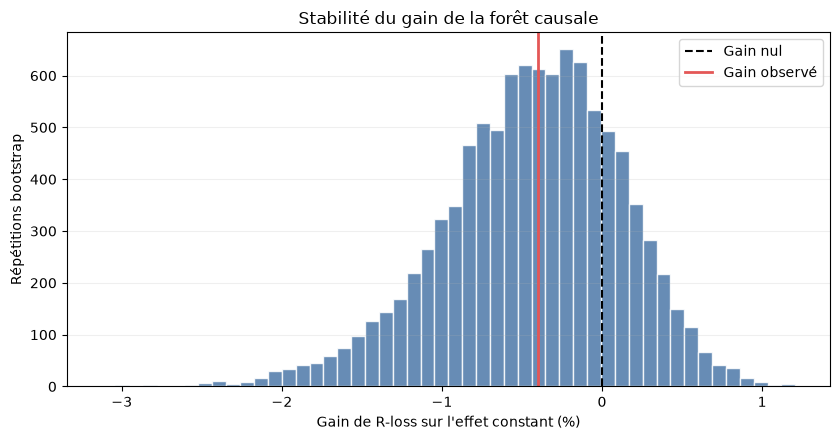

,gain observé (%),médiane bootstrap (%),IC 95 % inférieur (%),IC 95 % supérieur (%),tirages avec gain positif (%)
0,-0.401,-0.4,-1.682,0.546,22.07


In [71]:
# Calculer la masse d'erreur apportée par chaque objet.
q5_forest_bootstrap_df = q5_forest_results_df[[
    "source_image_id", "T", "Y_residual", "forest_weight",
    "forest_prediction_oof", "constant_prediction_oof",
]].copy()
q5_forest_bootstrap_df["constant_error_mass"] = (
    q5_forest_bootstrap_df["forest_weight"]
    * (
        q5_forest_bootstrap_df["Y_residual"]
        - q5_forest_bootstrap_df["constant_prediction_oof"]
    ) ** 2
)
q5_forest_bootstrap_df["forest_error_mass"] = (
    q5_forest_bootstrap_df["forest_weight"]
    * (
        q5_forest_bootstrap_df["Y_residual"]
        - q5_forest_bootstrap_df["forest_prediction_oof"]
    ) ** 2
)

# groupby ramène les contributions des objets à une ligne par image.
q5_forest_bootstrap_images_df = (
    q5_forest_bootstrap_df.groupby("source_image_id", as_index=False)
    .agg(
        T=("T", "first"),
        treatment_values=("T", "nunique"),
        objets=("T", "size"),
        constant_error_mass=("constant_error_mass", "sum"),
        forest_error_mass=("forest_error_mass", "sum"),
    )
)
if len(q5_forest_bootstrap_images_df) != 375:
    raise ValueError("Le bootstrap attend 375 images.")
if not q5_forest_bootstrap_images_df["treatment_values"].eq(1).all():
    raise ValueError("Le traitement varie dans une image.")
if q5_forest_bootstrap_images_df["T"].value_counts().to_dict() != {0: 258, 1: 117}:
    raise ValueError("La répartition des images entre T=0 et T=1 a changé.")

# Chaque répétition conserve le nombre d'images de chacun des deux groupes.
Q5_FOREST_BOOTSTRAP_REPETITIONS = 10_000
q5_bootstrap_generator = np.random.default_rng(Q5_FOREST_SEED)
q5_bootstrap_constant_mass = np.zeros(Q5_FOREST_BOOTSTRAP_REPETITIONS)
q5_bootstrap_forest_mass = np.zeros(Q5_FOREST_BOOTSTRAP_REPETITIONS)

for q5_treatment_value in (0, 1):
    q5_group_images_df = q5_forest_bootstrap_images_df.loc[
        q5_forest_bootstrap_images_df["T"].eq(q5_treatment_value)
    ].reset_index(drop=True)
    q5_group_size = len(q5_group_images_df)

    # Chaque ligne contient les positions des images d'un échantillon bootstrap.
    q5_sampled_positions = q5_bootstrap_generator.integers(
        0, q5_group_size,
        size=(Q5_FOREST_BOOTSTRAP_REPETITIONS, q5_group_size),
    )
    q5_bootstrap_constant_mass += q5_group_images_df[
        "constant_error_mass"
    ].to_numpy()[q5_sampled_positions].sum(axis=1)
    q5_bootstrap_forest_mass += q5_group_images_df[
        "forest_error_mass"
    ].to_numpy()[q5_sampled_positions].sum(axis=1)

# Un gain positif signifie que la forêt possède la plus petite R-loss.
q5_bootstrap_forest_gains = (
    100 * (q5_bootstrap_constant_mass - q5_bootstrap_forest_mass)
    / q5_bootstrap_constant_mass
)
q5_forest_gain_ci = np.quantile(
    q5_bootstrap_forest_gains, [0.025, 0.975]
)

q5_forest_bootstrap_summary_df = pd.DataFrame([{
    "gain observé (%)": q5_overall_gain,
    "médiane bootstrap (%)": np.median(q5_bootstrap_forest_gains),
    "IC 95 % inférieur (%)": q5_forest_gain_ci[0],
    "IC 95 % supérieur (%)": q5_forest_gain_ci[1],
    "tirages avec gain positif (%)": (
        100 * np.mean(q5_bootstrap_forest_gains > 0)
    ),
}])

q5_figure, q5_axis = plt.subplots(figsize=(8.5, 4.5))
q5_axis.hist(
    q5_bootstrap_forest_gains, bins=50,
    color="#4C78A8", edgecolor="white", alpha=0.85,
)
q5_axis.axvline(0, color="black", linestyle="--", label="Gain nul")
q5_axis.axvline(
    q5_overall_gain, color="#E45756", linewidth=2, label="Gain observé"
)
q5_axis.set(
    title="Stabilité du gain de la forêt causale",
    xlabel="Gain de R-loss sur l'effet constant (%)",
    ylabel="Répétitions bootstrap",
)
q5_axis.legend()
q5_axis.grid(axis="y", alpha=0.2)
q5_figure.tight_layout()
plt.show()

display(q5_forest_bootstrap_summary_df.round(3))

#### Interprétation du bootstrap de la forêt

Le gain observé est de `−0,40 %` et sa médiane bootstrap est également proche de `−0,40 %`. L'intervalle à 95 % s'étend de `−1,68 %` à `+0,55 %` et contient donc zéro. De plus, la forêt ne fait mieux que l'effet constant que dans `22,07 %` des tirages.

Nous ne démontrons donc pas que l'effet varie de manière fiable entre les profils d'objets. Les CATE peuvent servir à explorer des différences possibles, mais pas à affirmer qu'une classe ou une orientation possède un effet distinct. L'ATO de `−11,01` points et son intervalle à 95 % restent le résultat causal principal.

### 12 - Relier l'effet causal au comportement de YOLO

Les métriques prédictives de la question 3 indiquent si YOLO détecte correctement les objets observés. L'analyse causale répond à une autre question : comment la probabilité de détection changerait-elle sous faible résolution après avoir rendu les groupes comparables ?

Nous calculons ici, pour chaque classe, les taux de détection pondérés dans `T=0` et `T=1`, puis leur différence. Nous ajoutons le CATE moyen proposé par la forêt afin de comparer les deux lectures. Comme le bootstrap n'a pas validé l'avantage de la forêt, ces CATE par classe restent exploratoires.

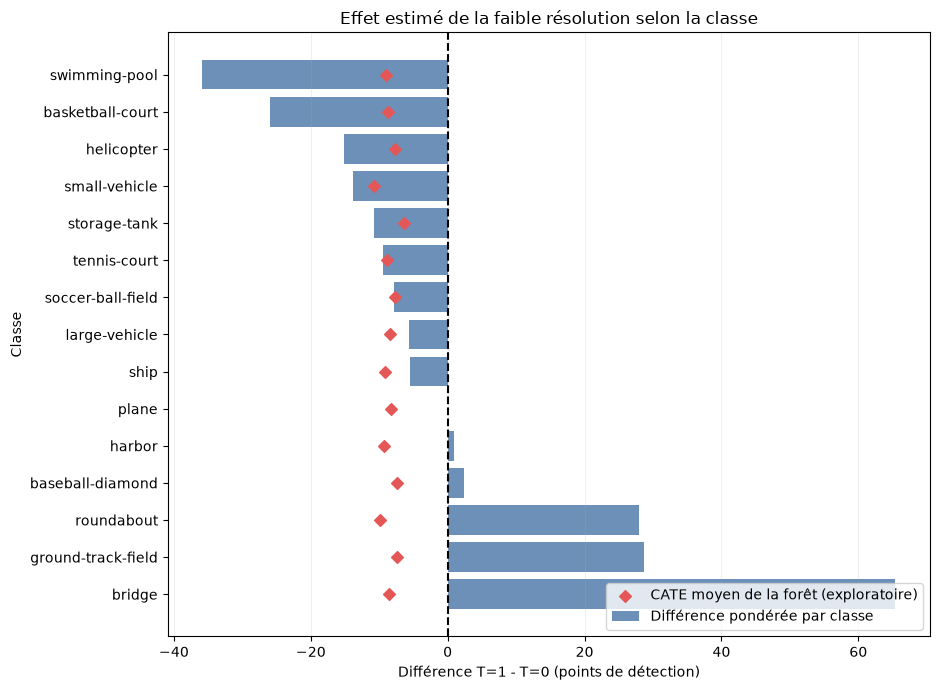

,classe,objets T=0,objets T=1,détection pondérée T=0 (%),détection pondérée T=1 (%),différence pondérée (points),CATE moyen forêt (points)
0,swimming-pool,318,236,94.17,58.31,-35.86,-9.03
1,basketball-court,71,42,92.52,66.55,-25.97,-8.72
2,helicopter,55,14,47.59,32.42,-15.16,-7.64
3,small-vehicle,20093,22914,90.56,76.77,-13.79,-10.75
4,storage-tank,79,2299,78.11,67.28,-10.83,-6.43
5,tennis-court,576,172,97.04,87.63,-9.41,-8.82
6,soccer-ball-field,42,96,89.73,81.88,-7.86,-7.67
7,large-vehicle,3852,1268,80.16,74.47,-5.69,-8.48
8,ship,6992,3179,97.67,92.12,-5.55,-9.12
9,plane,1417,786,98.92,98.90,-0.02,-8.26


In [72]:
# Vérifier que les lignes de l'analyse et de la forêt décrivent les mêmes objets.
q5_analysis_object_ids = q5_analysis_df["source_object_id"].reset_index(drop=True)
q5_forest_object_ids = q5_forest_results_df["source_object_id"].reset_index(drop=True)
if not q5_analysis_object_ids.equals(q5_forest_object_ids):
    raise ValueError("Les résultats de la forêt ne sont plus alignés sur les objets.")

# Ajouter aux résultats de la forêt le poids OW utilisé par l'ATO principal.
q5_class_effect_df = q5_forest_results_df.copy()
q5_class_effect_df["overlap_weight"] = q5_analysis_df[
    "overlap_weight"
].to_numpy(dtype=float)
q5_class_comparison_rows = []

for q5_class_name, q5_class_df in q5_class_effect_df.groupby("class_name"):
    q5_class_rates = {}
    q5_class_counts = {}

    for q5_treatment_value in (0, 1):
        q5_group_df = q5_class_df.loc[
            q5_class_df["T"].eq(q5_treatment_value)
        ]
        if q5_group_df.empty:
            raise ValueError(
                f"La classe {q5_class_name} est absente de T={q5_treatment_value}."
            )

        # np.average calcule le taux de détection avec les poids OW.
        q5_class_rates[q5_treatment_value] = np.average(
            q5_group_df["Y"],
            weights=q5_group_df["overlap_weight"],
        )
        q5_class_counts[q5_treatment_value] = len(q5_group_df)

    # Le CATE moyen est pondéré vers la même population de chevauchement.
    q5_class_cate = np.average(
        q5_class_df["CATE_oof"],
        weights=q5_class_df["forest_weight"],
    )
    q5_class_comparison_rows.append({
        "classe": q5_class_name,
        "objets T=0": q5_class_counts[0],
        "objets T=1": q5_class_counts[1],
        "détection pondérée T=0 (%)": 100 * q5_class_rates[0],
        "détection pondérée T=1 (%)": 100 * q5_class_rates[1],
        "différence pondérée (points)": (
            100 * (q5_class_rates[1] - q5_class_rates[0])
        ),
        "CATE moyen forêt (points)": 100 * q5_class_cate,
    })

# Les classes les plus affectées apparaissent en premier.
q5_class_comparison_df = (
    pd.DataFrame(q5_class_comparison_rows)
    .sort_values("différence pondérée (points)")
    .reset_index(drop=True)
)

# La barre montre la différence pondérée; le point montre le CATE exploratoire.
q5_class_plot_df = q5_class_comparison_df.sort_values(
    "différence pondérée (points)", ascending=False
)
q5_figure, q5_axis = plt.subplots(figsize=(9.5, 7))
q5_axis.barh(
    q5_class_plot_df["classe"],
    q5_class_plot_df["différence pondérée (points)"],
    color="#4C78A8", alpha=0.82, label="Différence pondérée par classe",
)
q5_axis.scatter(
    q5_class_plot_df["CATE moyen forêt (points)"],
    q5_class_plot_df["classe"],
    color="#E45756", marker="D", zorder=3,
    label="CATE moyen de la forêt (exploratoire)",
)
q5_axis.axvline(0, color="black", linestyle="--")
q5_axis.set(
    title="Effet estimé de la faible résolution selon la classe",
    xlabel="Différence T=1 - T=0 (points de détection)",
    ylabel="Classe",
)
q5_axis.legend(loc="lower right")
q5_axis.grid(axis="x", alpha=0.2)
q5_figure.tight_layout()
plt.show()

display(q5_class_comparison_df.round(2))

#### Interprétation de la comparaison par classe

Parmi les classes bien représentées, `small-vehicle` présente une baisse pondérée de `−13,79` points, `large-vehicle` de `−5,69` points et `ship` de `−5,55` points. La classe `plane` reste presque inchangée (`−0,02` point). La baisse atteint `−35,86` points pour `swimming-pool`, mais cette estimation repose sur beaucoup moins d'objets et ne possède pas ici son propre intervalle d'incertitude.

Les différences positives de `bridge`, `ground-track-field` et `roundabout` ne prouvent pas que la faible résolution améliore leur détection. Le groupe `T=0` ne contient respectivement que 10, 18 et 32 objets pour ces classes; les taux sont donc très sensibles à quelques observations.

Les CATE moyens de la forêt sont beaucoup plus rapprochés, entre environ `−10,75` et `−6,43` points. Comme la forêt n'améliore pas la R-loss, ces écarts entre classes restent exploratoires. Ce tableau décrit un comportement par classe au seuil de détection fixé; il ne constitue ni une mAP par classe ni une preuve d'effets causaux distincts.

### 13 - Synthèse de la question 5

Le tableau suivant sépare les deux conclusions principales. L'ATO mesure la variation moyenne de la probabilité de détection, en points. Le gain de R-loss mesure seulement si la forêt décrit mieux l'hétérogénéité qu'un effet constant, en pourcentage relatif de perte. Ces deux valeurs n'ont donc pas la même unité.

In [73]:
# Réunir les estimations finales sans mélanger leurs unités.
q5_final_summary_df = pd.DataFrame([
    {
        "analyse": "Effet moyen ATO",
        "mesure": "T=1 - T=0",
        "unité": "points de détection",
        "estimation": 100 * q5_ato_effect,
        "IC 95 % inférieur": 100 * q5_ato_ci_lower,
        "IC 95 % supérieur": 100 * q5_ato_ci_upper,
        "lecture": "baisse moyenne compatible avec les données",
    },
    {
        "analyse": "Forêt causale",
        "mesure": "gain sur l'effet constant",
        "unité": "% de R-loss",
        "estimation": q5_overall_gain,
        "IC 95 % inférieur": q5_forest_gain_ci[0],
        "IC 95 % supérieur": q5_forest_gain_ci[1],
        "lecture": "aucune hétérogénéité robuste démontrée",
    },
])

display(q5_final_summary_df.round(2))

,analyse,mesure,unité,estimation,IC 95 % inférieur,IC 95 % supérieur,lecture
0,Effet moyen ATO,T=1 - T=0,points de détection,-11.01,-19.31,-2.48,baisse moyenne compatible avec les données
1,Forêt causale,gain sur l'effet constant,% de R-loss,-0.40,-1.68,0.55,aucune hétérogénéité robuste démontrée


#### Conclusion et portée des résultats

Dans la population GoogleEarth où les deux niveaux de résolution sont comparables, la faible résolution diminue en moyenne la probabilité de détection de `11,01` points. L'intervalle à 95 % (`−19,31` à `−2,48` points) reste entièrement négatif. Ce résultat repose sur la pondération de chevauchement et constitue la conclusion causale principale.

La forêt produit des CATE variables, mais elle ne fait pas mieux qu'un effet constant : son gain de R-loss vaut `−0,40 %` avec un intervalle de `−1,68 %` à `+0,55 %`. Aucune hétérogénéité fiable selon la classe, la densité, l'orientation ou la position n'est donc démontrée.

Une bonne mAP répond à la qualité globale des prédictions observées, en tenant compte des détections correctes, manquées et fausses. Elle n'isole pas ce qui serait arrivé aux mêmes profils d'objets sous une autre résolution. À l'inverse, l'ATO vise cette comparaison contrefactuelle après ajustement, mais son résultat concerne ici le taux de détection des objets annotés et non la mAP complète.

Les conclusions supposent qu'aucune variable de confusion importante n'a été omise et que les modèles du score et du résultat sont suffisamment adaptés. Elles se limitent aux images GoogleEarth de chevauchement et à un traitement binaire obtenu en coupant le GSD à sa médiane. Les résultats par classe sont fragiles lorsque l'un des groupes contient peu d'objets. Enfin, `Y` a été produit par le checkpoint YOLO de l'époque 70; le modèle final de l'époque 313 obtient une mAP50-95 supérieure de seulement `0,04` point, mais l'effet causal estimé reste techniquement propre au checkpoint utilisé pour construire `Y`.

## Question 6 - Interprétation, conclusion et qualité du notebook

Cette dernière question rassemble les résultats précédents sans réentraîner les modèles. Elle distingue les performances observées des conclusions causales, puis précise les limites de l'étude.

### 1 - Interpréter les performances prédictives

Le meilleur YOLO11s-OBB, obtenu à l'époque 313 du run parti de COCO, atteint une précision de `74,96 %`, un rappel de `70,07 %`, une mAP50 de `74,31 %` et une mAP50-95 de `58,41 %`. Faster R-CNN atteint une mAP50 de `49,12 %` et une mAP50-95 de `31,88 %`. Ces scores décrivent toutefois deux géométries natives différentes : des OBB pour YOLO et des HBB pour Faster R-CNN. Leur écart ne constitue donc pas une comparaison parfaitement commune de la localisation.

Le benchmark complète cette lecture : YOLO traite environ `40,76` images par seconde contre `7,42` pour Faster R-CNN, soit près de `5,5` fois plus. Il utilise aussi moins de paramètres et moins de mémoire. YOLO est ainsi le modèle prédictif retenu.

La cellule suivante étudie les `66 968` objets GoogleEarth utilisés dans l'analyse causale. Pour chaque classe et groupe de taille, elle calcule la proportion d'objets annotés correctement retrouvés par YOLO. Ce taux descriptif n'est ni une mAP, car il ne compte pas les faux positifs, ni un effet causal.

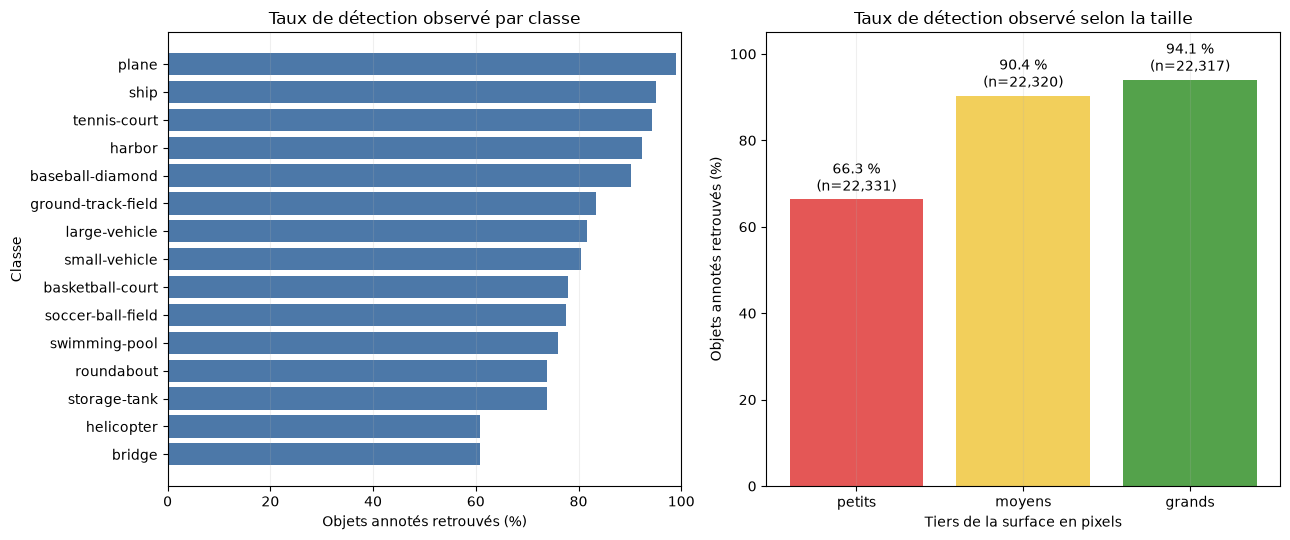

Seuils entre les groupes : 143.5 et 472.5 pixels²


,groupe_taille,objets,taux_detection_pct
0,petits,22331,66.33
1,moyens,22320,90.38
2,grands,22317,94.07


,class_name,objets,taux_detection_pct
2,bridge,135,60.74
5,helicopter,69,60.87
12,storage-tank,2378,73.84
8,roundabout,88,73.86
13,swimming-pool,554,75.99
11,soccer-ball-field,138,77.54
1,basketball-court,113,77.88
10,small-vehicle,43007,80.51
6,large-vehicle,5120,81.60
3,ground-track-field,96,83.33


: 

In [ ]:
# Un objet source peut apparaître dans plusieurs tuiles. Nous ne gardons
# donc qu'une seule surface par objet de validation.
q6_object_size_df = (
    pd.read_csv(
        q5_annotations_path,
        usecols=["split", "source_object_id", "source_area_px2"],
    )
    .loc[lambda table: table["split"].eq("validation")]
    .drop(columns="split")
    .drop_duplicates("source_object_id")
)

# La jointure ajoute la surface source au résultat binaire Y :
# Y=1 si l'objet a été détecté, sinon Y=0.
q6_predictive_df = q5_analysis_df[[
    "source_object_id", "class_name", "Y"
]].merge(
    q6_object_size_df,
    on="source_object_id",
    how="left",
    validate="one_to_one",
)
if q6_predictive_df["source_area_px2"].isna().any():
    raise ValueError("La surface d'un objet est manquante.")

# q=3 divise les objets en trois groupes d'effectifs proches.
# retbins renvoie aussi les deux seuils de surface calculés par qcut.
q6_predictive_df["groupe_taille"], q6_size_edges = pd.qcut(
    q6_predictive_df["source_area_px2"],
    q=3,
    labels=["petits", "moyens", "grands"],
    retbins=True,
)

# La moyenne de Y est la proportion d'objets annotés retrouvés.
q6_size_results_df = (
    q6_predictive_df.groupby("groupe_taille", observed=True, sort=True)
    .agg(objets=("Y", "size"), taux_detection=("Y", "mean"))
    .reset_index()
)
q6_size_results_df["taux_detection_pct"] = (
    100 * q6_size_results_df.pop("taux_detection")
)

q6_class_results_df = (
    q6_predictive_df.groupby("class_name", as_index=False)
    .agg(objets=("Y", "size"), taux_detection=("Y", "mean"))
)
q6_class_results_df["taux_detection_pct"] = (
    100 * q6_class_results_df.pop("taux_detection")
)
q6_class_results_df = q6_class_results_df.sort_values(
    "taux_detection_pct"
)

q6_figure, q6_axes = plt.subplots(1, 2, figsize=(13, 5.5))
q6_axes[0].barh(
    q6_class_results_df["class_name"],
    q6_class_results_df["taux_detection_pct"],
    color="#4C78A8",
)
q6_axes[0].set(
    title="Taux de détection observé par classe",
    xlabel="Objets annotés retrouvés (%)",
    ylabel="Classe",
    xlim=(0, 100),
)

q6_size_bars = q6_axes[1].bar(
    q6_size_results_df["groupe_taille"].astype(str),
    q6_size_results_df["taux_detection_pct"],
    color=["#E45756", "#F2CF5B", "#54A24B"],
)
q6_axes[1].set(
    title="Taux de détection observé selon la taille",
    xlabel="Tiers de la surface en pixels",
    ylabel="Objets annotés retrouvés (%)",
    ylim=(0, 105),
)
# bar_label place au-dessus de chaque barre le taux et l'effectif concernés.
q6_axes[1].bar_label(
    q6_size_bars,
    labels=[
        f"{row.taux_detection_pct:.1f} %\n(n={row.objets:,})"
        for row in q6_size_results_df.itertuples()
    ],
    padding=3,
)
for q6_axis in q6_axes:
    q6_axis.grid(axis="x", alpha=0.2)
q6_figure.tight_layout()
plt.show()

print(
    "Seuils entre les groupes : "
    f"{q6_size_edges[1]:.1f} et {q6_size_edges[2]:.1f} pixels²"
)
display(q6_size_results_df.round(2))
display(q6_class_results_df.round(2))

#### Interprétation par classe et par taille

Le taux observé augmente nettement avec la taille : `66,33 %` pour le tiers des objets les plus petits, `90,38 %` pour le tiers intermédiaire et `94,07 %` pour les plus grands. Les objets minuscules occupent peu de pixels; une petite erreur de localisation ou une perte de détails suffit donc plus souvent à manquer le seuil de correspondance.

Les classes `plane` (`98,96 %`) et `ship` (`95,07 %`) sont souvent retrouvées, tandis que `bridge` (`60,74 %`) et `helicopter` (`60,87 %`) le sont moins. Ces deux dernières classes ne comptent cependant que 135 et 69 objets : leurs pourcentages sont plus sensibles à quelques erreurs. `small-vehicle`, malgré ses nombreux exemples, reste plus difficile avec `80,51 %`.

Ces écarts sont descriptifs. Les classes n'ont pas les mêmes tailles, densités ni résolutions, et la taille apparente peut elle-même dépendre du GSD. Le graphique ne permet donc pas d'affirmer que la classe ou la taille cause directement les différences de détection.

### 2 - Interpréter les effets causaux

L'ATO estimé vaut `−11,01` points de détection pour `T=1 − T=0`. Dans la population de chevauchement, une faible résolution réduit donc en moyenne d'environ 11 points la probabilité qu'un objet annoté soit retrouvé. Son intervalle à 95 % va de `−19,31` à `−2,48` points : il exprime une incertitude importante sur l'amplitude, mais reste entièrement négatif. Cette interprétation dépend des hypothèses causales formulées à la question 4.

La forêt causale cherchait ensuite des objets affectés différemment. Son gain de R-loss vaut `−0,40 %`, avec un intervalle de `−1,68 %` à `+0,55 %`. Elle ne prédit donc pas mieux l'hétérogénéité qu'un effet constant. Aucun sous-groupe causal fiable n'est identifié; les variations de CATE par classe restent exploratoires.

La distinction est essentielle : la mAP et les taux précédents décrivent des prédictions observées, tandis que l'ATO compare ce qui serait attendu pour des objets comparables sous les deux niveaux de résolution.

### 3 - Limites de l'étude

| Limite | Conséquence possible |
|---|---|
| Tuilage | Le découpage peut séparer un objet de son contexte, le reproduire dans plusieurs tuiles ou laisser visible un fragment non annoté. Le chevauchement et le seuil de 70 % réduisent ce problème sans le supprimer. |
| Boîtes orientées converties | Pour Faster R-CNN, une OBB est convertie en HBB : l'orientation est perdue et davantage de fond entre dans la boîte. Les scores natifs YOLO et Faster R-CNN ne mesurent donc pas exactement la même géométrie. |
| Objets minuscules | Quelques pixels seulement décrivent certains objets. Leur apparence et leur IoU deviennent très sensibles à une petite variation de position. |
| Images non randomisées | Le GSD n'a pas été attribué au hasard. L'interprétation causale repose donc sur l'ajustement des différences observées entre les images. |
| Métadonnées incomplètes | Le GSD exploitable concerne ici GoogleEarth. L'analyse causale est ainsi limitée à 375 images et ne représente pas automatiquement toutes les sources de DOTA. |
| Variables non observées | Le capteur, la région, les conditions atmosphériques ou la qualité d'annotation peuvent influencer à la fois le GSD et la détection sans être mesurés. |

Enfin, le résultat causal utilise `Y` produit par le checkpoint YOLO de l'époque 70, alors que la référence prédictive finale est l'époque 313. Leur mAP50-95 ne diffère que de `0,04` point, mais l'effet causal reste formellement propre au checkpoint qui a construit `Y`.

### 4 - Repères visuels et conclusion générale

Les principales figures du notebook couvrent les différents niveaux de l'étude :

- les exemples annotés de la question 1 et le tuilage de la question 2 montrent les données fournies aux modèles;
- les courbes d'apprentissage, le benchmark et les exemples de prédictions de la question 3 présentent les performances des détecteurs;
- les distributions de surface et d'orientation de la question 1, complétées par le graphique ci-dessus, décrivent les catégories et les tailles;
- les distributions bootstrap et la comparaison causale de la question 5 montrent l'effet moyen et l'absence d'hétérogénéité robuste.

YOLO11s-OBB est finalement retenu pour ses meilleurs résultats prédictifs natifs, sa conservation de l'orientation et son efficacité à l'inférence. Les objets les plus petits restent les plus difficiles à détecter, mais cette observation descriptive ne constitue pas à elle seule un effet causal. Après ajustement, une faible résolution est associée à une baisse moyenne d'environ 11 points de détection dans la population comparable. La forêt ne met toutefois en évidence aucun sous-groupe dont l'effet serait fiablement différent.

Les résultats répondent ainsi aux deux volets du projet : choisir un détecteur adapté aux images aériennes et étudier le rôle de la résolution. Leur portée demeure limitée par la nature observationnelle des images, les métadonnées disponibles et les choix de préparation des annotations.